In [ ]:
!git clone https://github.com/microsoft/CyberBattleSim.git
!pip install -e CyberBattleSim --quiet
!pip install stable-baselines3[extra] gymnasium --quiet

Cloning into 'CyberBattleSim'...
remote: Enumerating objects: 1289, done.
remote: Counting objects: 100% (619/619), done.
remote: Compressing objects: 100% (341/341), done.
remote: Total 1289 (delta 497), reused 278 (delta 278), pack-reused 670 (from 3)
Receiving objects: 100% (1289/1289), 52.39 MiB | 12.41 MiB/s, done.
Resolving deltas: 100% (751/751), done.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 841.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.9/953.9 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 808.2/808.2 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import sys
import os
import subprocess

# Define a custom installation directory
custom_install_path = "/content/myenv"

# Clean up previous CyberBattleSim directory to ensure a fresh start
print("Cleaning up previous CyberBattleSim directory...")
!rm -rf CyberBattleSim

# Uninstall potentially conflicting packages to clear the environment
print("Uninstalling potentially conflicting packages...")
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "numpy", "scipy", "gymnasium", "gym", "stable-baselines3", "cyberbattlesim", "cyberbattle"], capture_output=False, check=False)

# Create the custom installation directory
os.makedirs(custom_install_path, exist_ok=True)

# Install numpy==1.26.4 into the custom directory
print(f"Installing numpy==1.26.4 into {custom_install_path}...")
subprocess.run([sys.executable, "-m", "pip", "install", "--target=" + custom_install_path, "--no-cache-dir", "numpy==1.26.4"], capture_output=False, check=True)

# Install other critical dependencies into the custom directory, ensuring numpy compatibility
print(f"Installing scipy, gymnasium, stable-baselines3 into {custom_install_path}...")
subprocess.run([sys.executable, "-m", "pip", "install", "--target=" + custom_install_path, "--no-cache-dir", "scipy", "gymnasium", "stable-baselines3[extra]"], capture_output=False, check=True)

# Add the custom installation directory to Python's path, prioritizing it
if custom_install_path not in sys.path:
    sys.path.insert(0, custom_install_path)

# Clear relevant modules from sys.modules to force reloading from the custom_install_path
print("Clearing cached modules...")
for mod in list(sys.modules):
    if mod.startswith("numpy") or mod.startswith("gymnasium") or mod.startswith("scipy") or mod.startswith("stable_baselines3"):
        del sys.modules[mod]

# Verify numpy version after isolated installation
import numpy as np
print(f"Numpy version after isolated install: {np.__version__}")
assert np.__version__.startswith("1.26"), "Numpy version check failed: expected 1.26.x"

# Clone the CyberBattleSim repository if not already present
print("Cloning CyberBattleSim repository...")
if not os.path.exists('CyberBattleSim'):
    !git clone https://github.com/microsoft/CyberBattleSim.git

# Install cyberbattlesim from the cloned source into the custom directory
print(f"Installing cyberbattlesim from source into {custom_install_path}...")
os.chdir('/content/CyberBattleSim')
subprocess.run([sys.executable, "-m", "pip", "install", ".", "--target=" + custom_install_path, "--quiet"], capture_output=False, check=True)
os.chdir('/content') # Change back to original directory

# Add the cloned repository's package path to sys.path
repo_path = '/content/CyberBattleSim'
cb_package_path = os.path.join(repo_path, 'cyberbattle')

if cb_package_path not in sys.path:
    sys.path.insert(0, cb_package_path)

# Attempt to import the model and verify
print("Attempting to import cyberbattle.simulation...")
import cyberbattle.simulation.model as m
print("CBS loaded successfully!")

# Final check of numpy version
print("Final numpy version check:")
!{sys.executable} -m pip show numpy

# Suppress tensorflow imports which can cause further numpy conflicts
sys.modules['tensorflow'] = None

Cleaning up previous CyberBattleSim directory...
Uninstalling potentially conflicting packages...
Installing numpy==1.26.4 into /content/myenv...
Installing scipy, gymnasium, stable-baselines3 into /content/myenv...
Clearing cached modules...
Numpy version after isolated install: 1.26.4
Cloning CyberBattleSim repository...
Cloning into 'CyberBattleSim'...
remote: Enumerating objects: 1289, done.
remote: Counting objects: 100% (619/619), done.
remote: Compressing objects: 100% (341/341), done.
remote: Total 1289 (delta 497), reused 278 (delta 278), pack-reused 670 (from 3)
Receiving objects: 100% (1289/1289), 52.39 MiB | 21.06 MiB/s, done.
Resolving deltas: 100% (751/751), done.
Installing cyberbattlesim from source into /content/myenv...
Attempting to import cyberbattle.simulation...


/content/myenv/networkx/utils/backends.py:102: RuntimeWarning: networkx backend name is not a valid identifier: 'nx-loopback'. Ignoring.
  backends = _get_backends("networkx.backends")


CBS loaded successfully!
Final numpy version check:


In [ ]:
from cyberbattle.simulation import model as m
print("CBS loaded successfully")

CBS loaded successfully


In [ ]:
import numpy as np
import sys

print(f"Active numpy version: {np.__version__}")

print("\nInstalled numpy details:")
!{sys.executable} -m pip show numpy

print("\nInstalled cyberbattlesim details:")
!{sys.executable} -m pip show cyberbattlesim

Active numpy version: 1.26.4

Installed numpy details:

Installed cyberbattlesim details:


### Restart Runtime and Reinstall Dependencies

Please restart the Colab runtime (Runtime -> Restart runtime...) before proceeding with the following cell. This is crucial to clear any conflicting `numpy` imports from memory.

In [ ]:
import sys
import os
import subprocess
import numpy as np # Import numpy AFTER runtime restart to get the correct version

print("--- Resuming CyberBattleSim installation after Runtime Restart ---")

# Clone the repository (if not already present, though it should be after the last step)
# We'll skip `rm -rf CyberBattleSim` here assuming the previous cell cleared it.
print("Cloning CyberBattleSim repository if not exists...")
if not os.path.exists('CyberBattleSim'):
    !git clone https://github.com/microsoft/CyberBattleSim.git
else:
    print("CyberBattleSim directory already exists.")

# Change directory into the cloned repository to install cyberbattlesim
print("Installing cyberbattlesim from source...")
os.chdir('/content/CyberBattleSim')
subprocess.run([sys.executable, "-m", "pip", "install", ".", "--quiet"], capture_output=False)
os.chdir('/content') # Change back to original directory

# Add the cloned repository's directories to Python's path to ensure it's discoverable
repo_path = '/content/CyberBattleSim'
cb_package_path = os.path.join(repo_path, 'cyberbattle')

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)
if cb_package_path not in sys.path:
    sys.path.insert(0, cb_package_path)

print("\n--- Final Verification ---")
print(f"Active numpy version (np.__version__): {np.__version__}")

print("\nInstalled numpy details (pip show):")
!{sys.executable} -m pip show numpy

print("\nInstalled cyberbattlesim details (pip show):")
!{sys.executable} -m pip show cyberbattlesim

try:
    from cyberbattle.simulation import model as m
    print("\nSuccessfully imported cyberbattle.simulation.model.")
    print(f"Content of m (model module): {dir(m)}")
    print(f"Location of m (model module): {m.__file__}")

    # Check for Network class explicitly
    if hasattr(m, 'Network'):
        print("Found 'Network' class in cyberbattle.simulation.model.")
        # Placeholder for nodes. User will need to replace this.
        nodes = {} # Replace with actual nodes dictionary if you want to test Network instantiation
        try:
            network = m.Network(nodes=nodes, environs=[])
            print("Successfully instantiated Network class.")
        except Exception as e:
            print(f"Failed to instantiate Network class: {e}")
    else:
        print("ERROR: 'Network' class NOT found in cyberbattle.simulation.model.")

    default_firewall = [
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
    print("Successfully accessed FirewallRule and RulePermission.")

except ImportError as e:
    print(f"\nFailed to import cyberbattle.simulation.model: {e}")
except Exception as e:
    print(f"An unexpected error occurred during verification: {e}")


--- Resuming CyberBattleSim installation after Runtime Restart ---
Cloning CyberBattleSim repository if not exists...
CyberBattleSim directory already exists.
Installing cyberbattlesim from source...

--- Final Verification ---
Active numpy version (np.__version__): 1.26.4

Installed numpy details (pip show):
Name: numpy
Version: 1.26.4
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License: Copyright (c) 2005-2023, NumPy Developers.
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are
met:

    * Redistributions of source code must retain the above copyright
       notice, this list of conditions and the following disclaimer.

    * Redistributions in binary form must reproduce the above
       copyright notice, this list of conditions and the following
       disclaimer in the documentation

In [ ]:
import sys
import os
import subprocess

# Clean up previous CyberBattleSim directory to ensure a fresh start
print("Cleaning up previous CyberBattleSim directory and uninstalling conflicting packages...")
!rm -rf CyberBattleSim

# Uninstall potentially conflicting packages including numpy and cyberbattlesim
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "numpy", "gymnasium", "gym", "stable-baselines3", "cyberbattlesim", "cyberbattle"], capture_output=False)

# Install numpy to the specific version required by cyberbattlesim
print("Installing numpy==1.26.4 with force-reinstall...")
subprocess.run([sys.executable, "-m", "pip", "install", "numpy==1.26.4", "--force-reinstall", "--quiet"], capture_output=False)

print("""
--- IMPORTANT ---
Numpy 1.26.4 has been installed. Please RESTART THE RUNTIME (Runtime -> Restart runtime...) NOW.
Then, run the next cell to install cyberbattlesim and verify the setup.
""")

Cleaning up previous CyberBattleSim directory and uninstalling conflicting packages...
Installing numpy==1.26.4 with force-reinstall...

--- IMPORTANT ---
Numpy 1.26.4 has been installed. Please RESTART THE RUNTIME (Runtime -> Restart runtime...) NOW.
Then, run the next cell to install cyberbattlesim and verify the setup.



In [ ]:
from cyberbattle.simulation import model as m

print("Model file:")
print(m.__file__)

print("\nEverything inside model:")
print(dir(m))

Model file:
/content/myenv/cyberbattle/simulation/model.py

Everything inside model:
['ALGEBRA', 'AdminEscalation', 'AttackResult', 'CachedCredential', 'CredentialID', 'CustomerData', 'Dict', 'Enum', 'Environment', 'ExploitFailed', 'FirewallConfiguration', 'FirewallRule', 'ID', 'Identifiers', 'IntEnum', 'Iterator', 'LateralMove', 'LeakedCredentials', 'LeakedNodesId', 'List', 'ListeningService', 'MachineStatus', 'NamedTuple', 'NodeID', 'NodeInfo', 'NodeValue', 'Optional', 'PortName', 'Precondition', 'PrivilegeEscalation', 'PrivilegeLevel', 'Probability', 'ProbeFailed', 'ProbeSucceeded', 'PropertyName', 'Rates', 'RulePermission', 'SAMPLE_IDENTIFIERS', 'SystemEscalation', 'Tuple', 'Union', 'VERSION_TAG', 'VulnerabilityID', 'VulnerabilityInfo', 'VulnerabilityLibrary', 'VulnerabilityOutcome', 'VulnerabilityOutcomes', 'VulnerabilityType', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '__warningregistry__', 'assign_random_labels', 'b

In [ ]:
import inspect
print(inspect.signature(m.NodeInfo.__init__))

(self, services: List[cyberbattle.simulation.model.ListeningService], vulnerabilities: Dict[str, cyberbattle.simulation.model.VulnerabilityInfo] = <factory>, value: int = 0, properties: List[str] = <factory>, firewall: cyberbattle.simulation.model.FirewallConfiguration = <factory>, agent_installed: bool = False, privilege_level: cyberbattle.simulation.model.PrivilegeLevel = <PrivilegeLevel.NoAccess: 0>, reimagable: bool = True, last_reimaging: Optional[datetime.datetime] = None, owned_string: str = '', sla_weight: float = 1.0) -> None


In [ ]:
print(inspect.signature(m.VulnerabilityInfo.__init__))

(self, /, *args, **kwargs)


In [ ]:
print(inspect.signature(m.LateralMove.__init__))

(self, /, *args, **kwargs)


In [ ]:
print(inspect.signature(m.Network.__init__))

AttributeError: module 'cyberbattle.simulation.model' has no attribute 'Network'

In [ ]:
import cyberbattle.simulation.model as m
print(m.__file__)
print([x for x in dir(m) if not x.startswith('_')])

/content/myenv/cyberbattle/simulation/model.py
['ALGEBRA', 'AdminEscalation', 'AttackResult', 'CachedCredential', 'CredentialID', 'CustomerData', 'Dict', 'Enum', 'Environment', 'ExploitFailed', 'FirewallConfiguration', 'FirewallRule', 'ID', 'Identifiers', 'IntEnum', 'Iterator', 'LateralMove', 'LeakedCredentials', 'LeakedNodesId', 'List', 'ListeningService', 'MachineStatus', 'NamedTuple', 'NodeID', 'NodeInfo', 'NodeValue', 'Optional', 'PortName', 'Precondition', 'PrivilegeEscalation', 'PrivilegeLevel', 'Probability', 'ProbeFailed', 'ProbeSucceeded', 'PropertyName', 'Rates', 'RulePermission', 'SAMPLE_IDENTIFIERS', 'SystemEscalation', 'Tuple', 'Union', 'VERSION_TAG', 'VulnerabilityID', 'VulnerabilityInfo', 'VulnerabilityLibrary', 'VulnerabilityOutcome', 'VulnerabilityOutcomes', 'VulnerabilityType', 'assign_random_labels', 'boolean', 'collect_ports_from_environment', 'collect_ports_from_nodes', 'collect_ports_from_vuln', 'collect_properties_from_nodes', 'collect_vulnerability_ids_from_node

In [ ]:
%%writefile topology_A.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS"), m.ListeningService("RDP")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            PublicExploit=m.VulnerabilityInfo(
                description="Known public exploit on exposed service",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.9),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "FileServer": m.NodeInfo(
        services=[m.ListeningService("SSH"), m.ListeningService("RDP")],
        value=50,
        properties=["Linux", "FileShare"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExploitSMB=m.VulnerabilityInfo(
                description="Exploit SMB vulnerability",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            )
        )
    ),

    "DatabaseServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=100,
        properties=["Linux", "Database"],
        owned_string="FLAG: Database accessed",
        firewall=default_firewall,
        vulnerabilities=dict(
            SQLInjection=m.VulnerabilityInfo(
                description="SQL injection on exposed endpoint",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.4),
                cost=3.0
            )
        )
    ),

    "AdminWorkstation": m.NodeInfo(
        services=[m.ListeningService("RDP"), m.ListeningService("SSH")],
        value=80,
        properties=["Windows", "AdminHost"],
        firewall=default_firewall,
        vulnerabilities=dict(
            StealAdminCreds=m.VulnerabilityInfo(
                description="Steal cached admin credentials",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedCredentials(credentials=[
                    m.CachedCredential(node="DomainController", port="RDP", credential="admin_pass")
                ]),
                rates=m.Rates(successRate=0.7),
                cost=2.0
            )
        )
    ),

    "DomainController": m.NodeInfo(
        services=[m.ListeningService("RDP", allowedCredentials=["admin_pass"])],
        value=200,
        properties=["Windows", "DomainController"],
        owned_string="FLAG: Domain Controller compromised",
        firewall=default_firewall,
        vulnerabilities=dict(
            PassTheHash=m.VulnerabilityInfo(
                description="Pass-the-hash attack using stolen NTLM hash",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=3.0
            )
        )
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "FileShare", "Database", "AdminHost", "DomainController"],
    local_vulnerabilities=["StealAdminCreds"],
    remote_vulnerabilities=["PublicExploit", "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "PassTheHash"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology A loaded:", len(nodes), "nodes")

Writing topology_A.py


In [ ]:
%run topology_A.py

Topology A loaded: 7 nodes


In [ ]:
%%writefile topology_B.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            PublicExploit=m.VulnerabilityInfo(
                description="Known public exploit on exposed service",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.9),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "Workstation_3": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            CredentialReuse=m.VulnerabilityInfo(
                description="Reused credentials from Workstation_1",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.6),
                cost=1.0
            )
        )
    ),

    "BackupServer": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=40,
        properties=["Linux", "BackupService"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExposedBackupCreds=m.VulnerabilityInfo(
                description="Backup credentials stored in plaintext config",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.65),
                cost=1.0
            )
        )
    ),

    "FileServer": m.NodeInfo(
        services=[m.ListeningService("SSH"), m.ListeningService("RDP")],
        value=50,
        properties=["Linux", "FileShare"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExploitSMB=m.VulnerabilityInfo(
                description="Exploit SMB vulnerability",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            )
        )
    ),

    "DomainController": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=150,
        properties=["Windows", "DomainController"],
        owned_string="FLAG: Domain Controller compromised",
        firewall=default_firewall,
        vulnerabilities=dict(
            PassTheHash=m.VulnerabilityInfo(
                description="Pass-the-hash attack using stolen NTLM hash",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=3.0
            )
        )
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "BackupService", "FileShare", "DomainController"],
    local_vulnerabilities=[],
    remote_vulnerabilities=["PublicExploit", "BruteForceRDP", "WeakSSH", "CredentialReuse", "ExposedBackupCreds", "ExploitSMB", "PassTheHash"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology B loaded:", len(nodes), "nodes")

Writing topology_B.py


In [ ]:
%%writefile topology_C.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS"), m.ListeningService("RDP")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            PublicExploit=m.VulnerabilityInfo(
                description="Known public exploit on exposed service",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.9),
                cost=1.0
            )
        )
    ),

    "WebServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=20,
        properties=["Linux", "ApacheWebSite"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WebShell=m.VulnerabilityInfo(
                description="Upload web shell via vulnerable upload form",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.6),
                cost=2.0
            )
        )
    ),

    "MailServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=30,
        properties=["Linux", "MailService"],
        firewall=default_firewall,
        vulnerabilities=dict(
            PhishingPayload=m.VulnerabilityInfo(
                description="Deliver phishing payload via mail server",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=1.5
            )
        )
    ),

    "MonitoringServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=20,
        properties=["Linux", "Monitoring"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakMonitoringAPI=m.VulnerabilityInfo(
                description="Unauthenticated API endpoint on monitoring server",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.55),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "AdminWorkstation": m.NodeInfo(
        services=[m.ListeningService("RDP"), m.ListeningService("SSH")],
        value=60,
        properties=["Windows", "AdminHost"],
        firewall=default_firewall,
        vulnerabilities=dict(
            StealAdminCreds=m.VulnerabilityInfo(
                description="Steal cached admin credentials",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedCredentials(credentials=[
                    m.CachedCredential(node="DatabaseServer", port="HTTPS", credential="db_pass")
                ]),
                rates=m.Rates(successRate=0.7),
                cost=2.0
            )
        )
    ),

    # High-value target placed near the edge (close to EntryPoint), unlike A and B
    "DatabaseServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS", allowedCredentials=["db_pass"])],
        value=180,
        properties=["Linux", "Database"],
        owned_string="FLAG: Database accessed",
        firewall=default_firewall,
        vulnerabilities=dict(
            SQLInjection=m.VulnerabilityInfo(
                description="SQL injection on exposed endpoint",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.4),
                cost=3.0
            )
        )
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "ApacheWebSite", "MailService", "Monitoring", "AdminHost", "Database"],
    local_vulnerabilities=["StealAdminCreds"],
    remote_vulnerabilities=["PublicExploit", "WebShell", "PhishingPayload", "WeakMonitoringAPI", "BruteForceRDP", "WeakSSH", "SQLInjection"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology C loaded:", len(nodes), "nodes")

Writing topology_C.py


In [ ]:
%%writefile profiles.py
from cyberbattle.simulation import model as m

# --- Profile 1: Aggressive (train set) ---
# Fast, loud, high success rate — used in training
AGGRESSIVE_VULNS = dict(
    BruteForceRDP=m.VulnerabilityInfo(
        description="Brute force RDP credentials",
        type=m.VulnerabilityType.REMOTE,
        outcome=m.LateralMove(),
        rates=m.Rates(successRate=0.8),
        cost=1.0
    )
)

# --- Profile 2: Stealthy (train set) ---
# Slow, credential-reuse focused, lower detection footprint — used in training
STEALTHY_VULNS = dict(
    CredentialReuse=m.VulnerabilityInfo(
        description="Reuse stolen credentials for lateral movement",
        type=m.VulnerabilityType.REMOTE,
        outcome=m.LateralMove(),
        rates=m.Rates(successRate=0.6),
        cost=0.5
    )
)

# --- Profile 3: Cloud Pivot (ZERO-DAY holdout — NEVER used in training) ---
# Only appears in test topologies / test episodes
ZERODAY_VULNS = dict(
    CloudIAMPivot=m.VulnerabilityInfo(
        description="Exploits misconfigured IAM role to pivot",
        type=m.VulnerabilityType.REMOTE,
        outcome=m.LateralMove(),
        rates=m.Rates(successRate=0.7),
        cost=2.0
    )
)

PROFILES = {
    "aggressive": AGGRESSIVE_VULNS,
    "stealthy": STEALTHY_VULNS,
    "cloud_pivot": ZERODAY_VULNS,   # holdout — do not add to TRAIN_PROFILES anywhere
}

print("Profiles loaded:", list(PROFILES.keys()))

Writing profiles.py


In [ ]:
 %%writefile profiles.py

Overwriting profiles.py


In [ ]:
%run profiles.py

In [ ]:
!cat profiles.py

In [ ]:
import os
print("Exists:", os.path.exists("profiles.py"))
if os.path.exists("profiles.py"):
    print("Size in bytes:", os.path.getsize("profiles.py"))

Exists: True
Size in bytes: 1


In [ ]:
import os
os.remove("profiles.py")

In [ ]:
%%writefile profiles.py
from cyberbattle.simulation import model as m

AGGRESSIVE_VULNS = dict(
    BruteForceRDP=m.VulnerabilityInfo(
        description="Brute force RDP credentials",
        type=m.VulnerabilityType.REMOTE,
        outcome=m.LateralMove(),
        rates=m.Rates(successRate=0.8),
        cost=1.0
    )
)

STEALTHY_VULNS = dict(
    CredentialReuse=m.VulnerabilityInfo(
        description="Reuse stolen credentials for lateral movement",
        type=m.VulnerabilityType.REMOTE,
        outcome=m.LateralMove(),
        rates=m.Rates(successRate=0.6),
        cost=0.5
    )
)

ZERODAY_VULNS = dict(
    CloudIAMPivot=m.VulnerabilityInfo(
        description="Exploits misconfigured IAM role to pivot",
        type=m.VulnerabilityType.REMOTE,
        outcome=m.LateralMove(),
        rates=m.Rates(successRate=0.7),
        cost=2.0
    )
)

PROFILES = {
    "aggressive": AGGRESSIVE_VULNS,
    "stealthy": STEALTHY_VULNS,
    "cloud_pivot": ZERODAY_VULNS,
}

print("Profiles loaded:", list(PROFILES.keys()))

Writing profiles.py


In [ ]:
import os
print("Size in bytes:", os.path.getsize("profiles.py"))

Size in bytes: 1007


In [ ]:
%run profiles.py

Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']


In [ ]:
%%writefile dr_controller.py
import random

# Only training topology and training profiles go here.
# topology_B, topology_C, and cloud_pivot must NEVER appear in these lists.
TRAIN_TOPOLOGIES = ["topology_A"]
TRAIN_PROFILES = ["aggressive", "stealthy"]

def sample_episode_config():
    """Randomly sample a topology + attacker profile + vuln subset for one training episode."""
    return {
        "topology": random.choice(TRAIN_TOPOLOGIES),
        "attacker_profile": random.choice(TRAIN_PROFILES),
        "vuln_subset_ratio": random.uniform(0.6, 1.0)  # randomly disable some vulns per episode
    }

if __name__ == "__main__":
    print("DR controller loaded.")
    for i in range(5):
        config = sample_episode_config()
        print(f"Episode {i+1}: {config}")

Writing dr_controller.py


In [ ]:
%%writefile dr_controller.py

Overwriting dr_controller.py


In [ ]:
 %run dr_controller.py

In [ ]:
import os
print("Size in bytes:", os.path.getsize("dr_controller.py"))

Size in bytes: 1


In [ ]:
os.remove("dr_controller.py")

In [ ]:
%%writefile dr_controller.py

Writing dr_controller.py


In [ ]:
%run dr_controller.py

In [ ]:
%%writefile dr_controller.py
import random

TRAIN_TOPOLOGIES = ["topology_A"]
TRAIN_PROFILES = ["aggressive", "stealthy"]

def sample_episode_config():
    return {
        "topology": random.choice(TRAIN_TOPOLOGIES),
        "attacker_profile": random.choice(TRAIN_PROFILES),
        "vuln_subset_ratio": random.uniform(0.6, 1.0)
    }

if __name__ == "__main__":
    print("DR controller loaded.")
    for i in range(5):
        config = sample_episode_config()
        print(f"Episode {i+1}: {config}")

Overwriting dr_controller.py


In [ ]:
import os
print("Size in bytes:", os.path.getsize("dr_controller.py"))

Size in bytes: 477


In [ ]:
%run dr_controller.py

DR controller loaded.
Episode 1: {'topology': 'topology_A', 'attacker_profile': 'aggressive', 'vuln_subset_ratio': 0.8054670824646915}
Episode 2: {'topology': 'topology_A', 'attacker_profile': 'stealthy', 'vuln_subset_ratio': 0.6281627176170733}
Episode 3: {'topology': 'topology_A', 'attacker_profile': 'aggressive', 'vuln_subset_ratio': 0.6403276343144575}
Episode 4: {'topology': 'topology_A', 'attacker_profile': 'aggressive', 'vuln_subset_ratio': 0.9980581847368644}
Episode 5: {'topology': 'topology_A', 'attacker_profile': 'stealthy', 'vuln_subset_ratio': 0.784140088308952}


In [ ]:
import cyberbattle._env.cyberbattle_env as cbenv
print([x for x in dir(cbenv) if not x.startswith('_')])

['Action', 'ActionMask', 'AttackerGoal', 'CyberBattleEnv', 'CyberBattleSpaceKind', 'DefenderAgent', 'DefenderConstraint', 'DefenderGoal', 'Dict', 'DiscriminatedUnion', 'DummySpace', 'Env', 'EnvironmentBounds', 'Key', 'LOGGER', 'List', 'NA', 'NamedTuple', 'Observation', 'ObservationSpaceType', 'Optional', 'OutOfBoundIndexError', 'PortName', 'PrivilegeLevel', 'Scatter', 'StepInfo', 'Tuple', 'TypeVar', 'TypedDict', 'UNUSED_SLOT', 'USED_SLOT', 'Value', 'actions', 'cast', 'commandcontrol', 'convert_matrix', 'copy', 'inverse_dict', 'logging', 'make_subplots', 'model', 'networkx', 'np', 'numpy', 'seeding', 'sourcenode_of_action', 'spaces', 'time']


In [ ]:
import cyberbattle
print(cyberbattle.__file__)

import os
pkg_dir = os.path.dirname(cyberbattle.__file__)
for root, dirs, files in os.walk(pkg_dir):
    # skip deep noise
    if root.count(os.sep) - pkg_dir.count(os.sep) > 2:
        continue
    for f in files:
        if f.endswith(".py"):
            print(os.path.join(root, f))

/content/myenv/cyberbattle/__init__.py
/content/myenv/cyberbattle/__init__.py
/content/myenv/cyberbattle/samples/__init__.py
/content/myenv/cyberbattle/samples/toyctf/tinytoy.py
/content/myenv/cyberbattle/samples/toyctf/toy_ctf.py
/content/myenv/cyberbattle/samples/toyctf/__init__.py
/content/myenv/cyberbattle/samples/chainpattern/chainpattern.py
/content/myenv/cyberbattle/samples/chainpattern/__init__.py
/content/myenv/cyberbattle/samples/simple/simpleenv.py
/content/myenv/cyberbattle/samples/simple/__init__.py
/content/myenv/cyberbattle/samples/active_directory/generate_ad.py
/content/myenv/cyberbattle/samples/active_directory/tiny_ad.py
/content/myenv/cyberbattle/samples/active_directory/__init__.py
/content/myenv/cyberbattle/_env/graph_spaces.py
/content/myenv/cyberbattle/_env/defender.py
/content/myenv/cyberbattle/_env/graph_wrapper.py
/content/myenv/cyberbattle/_env/cyberbattle_chain.py
/content/myenv/cyberbattle/_env/cyberbattle_env.py
/content/myenv/cyberbattle/_env/cyberbattle

In [ ]:
import cyberbattle, os
pkg_dir = os.path.dirname(cyberbattle.__file__)
print("Package dir:", pkg_dir)
print()
for root, dirs, files in os.walk(pkg_dir):
    level = root.replace(pkg_dir, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files:
        if f.endswith('.py'):
            print(f"{indent}  {f}")

Package dir: /content/myenv/cyberbattle

cyberbattle/
  __init__.py
  samples/
    __init__.py
    toyctf/
      tinytoy.py
      toy_ctf.py
      __init__.py
      __pycache__/
    __pycache__/
    chainpattern/
      chainpattern.py
      __init__.py
      __pycache__/
    simple/
      simpleenv.py
      __init__.py
      __pycache__/
    active_directory/
      generate_ad.py
      tiny_ad.py
      __init__.py
      __pycache__/
  __pycache__/
  _env/
    graph_spaces.py
    defender.py
    graph_wrapper.py
    cyberbattle_chain.py
    cyberbattle_env.py
    cyberbattle_env_test.py
    discriminatedunion.py
    active_directory.py
    cyberbattle_tiny.py
    cyberbattle_toyctf.py
    flatten_wrapper.py
    __init__.py
    cyberbattle_random.py
    option_wrapper.py
    __pycache__/
  simulation/
    environment_generation_test.py
    generate_network.py
    environment_generation.py
    commandcontrol.py
    model.py
    actions.py
    commandcontrol_test.py
    actions_test.py
   

In [ ]:
import cyberbattle, os
pkg_dir = os.path.dirname(cyberbattle.__file__)
print("Package dir:", pkg_dir)
print()
for root, dirs, files in os.walk(pkg_dir):
    level = root.replace(pkg_dir, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files:
        if f.endswith('.py'):
            print(f"{indent}  {f}")

Package dir: /content/myenv/cyberbattle

cyberbattle/
  __init__.py
  samples/
    __init__.py
    toyctf/
      tinytoy.py
      toy_ctf.py
      __init__.py
      __pycache__/
    __pycache__/
    chainpattern/
      chainpattern.py
      __init__.py
      __pycache__/
    simple/
      simpleenv.py
      __init__.py
      __pycache__/
    active_directory/
      generate_ad.py
      tiny_ad.py
      __init__.py
      __pycache__/
  __pycache__/
  _env/
    graph_spaces.py
    defender.py
    graph_wrapper.py
    cyberbattle_chain.py
    cyberbattle_env.py
    cyberbattle_env_test.py
    discriminatedunion.py
    active_directory.py
    cyberbattle_tiny.py
    cyberbattle_toyctf.py
    flatten_wrapper.py
    __init__.py
    cyberbattle_random.py
    option_wrapper.py
    __pycache__/
  simulation/
    environment_generation_test.py
    generate_network.py
    environment_generation.py
    commandcontrol.py
    model.py
    actions.py
    commandcontrol_test.py
    actions_test.py
   

In [ ]:
import cyberbattle, os
pkg_dir = os.path.dirname(cyberbattle.__file__)
print("Package dir:", pkg_dir)
print()
print("Top-level contents:")
for item in sorted(os.listdir(pkg_dir)):
    print(" ", item)

Package dir: /content/myenv/cyberbattle

Top-level contents:
  __init__.py
  __pycache__
  _env
  agents
  samples
  simulation


In [ ]:
import os
print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'profiles.py', 'topology_A.py', 'topology_C.py', 'dr_controller.py', 'myenv', 'topology_B.py', 'sample_data']


In [ ]:
import sys, subprocess, os

subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "numpy", "gymnasium", "gym", "stable-baselines3", "cyberbattlesim", "cyberbattle"], capture_output=False)

if not os.path.exists('CyberBattleSim'):
    !git clone https://github.com/microsoft/CyberBattleSim.git

subprocess.run([sys.executable, "-m", "pip", "install", "numpy==1.26.4", "--force-reinstall", "--quiet"], capture_output=False)

os.chdir('/content/CyberBattleSim')
subprocess.run([sys.executable, "-m", "pip", "install", ".", "--quiet"], capture_output=False)
os.chdir('/content')

print("Install done. RESTART RUNTIME NOW, then run Cell 2.")

Cloning into 'CyberBattleSim'...
remote: Enumerating objects: 1289, done.
remote: Counting objects: 100% (619/619), done.
remote: Compressing objects: 100% (341/341), done.
remote: Total 1289 (delta 497), reused 278 (delta 278), pack-reused 670 (from 3)
Receiving objects: 100% (1289/1289), 52.39 MiB | 16.56 MiB/s, done.
Resolving deltas: 100% (751/751), done.
Install done. RESTART RUNTIME NOW, then run Cell 2.


In [ ]:
import sys, os
repo_path = '/content/CyberBattleSim'
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

from cyberbattle.simulation import model as m
print("CBS reloaded successfully")

import numpy as np
print("numpy version:", np.__version__)

print("Files still present:", os.listdir("/content"))

CBS reloaded successfully
numpy version: 1.26.4
Files still present: ['.config', 'profiles.py', 'topology_A.py', 'topology_C.py', 'CyberBattleSim', 'dr_controller.py', 'myenv', 'topology_B.py', 'sample_data']


In [ ]:
%run topology_A.py
%run topology_B.py
%run topology_C.py
%run profiles.py
%run dr_controller.py

Topology A loaded: 7 nodes
Topology B loaded: 7 nodes
Topology C loaded: 8 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
DR controller loaded.
Episode 1: {'topology': 'topology_A', 'attacker_profile': 'stealthy', 'vuln_subset_ratio': 0.9953009440208703}
Episode 2: {'topology': 'topology_A', 'attacker_profile': 'stealthy', 'vuln_subset_ratio': 0.6034749573284189}
Episode 3: {'topology': 'topology_A', 'attacker_profile': 'aggressive', 'vuln_subset_ratio': 0.9064853420583976}
Episode 4: {'topology': 'topology_A', 'attacker_profile': 'aggressive', 'vuln_subset_ratio': 0.6689307196074924}
Episode 5: {'topology': 'topology_A', 'attacker_profile': 'stealthy', 'vuln_subset_ratio': 0.967058489649315}


In [ ]:
import cyberbattle, os
pkg_dir = os.path.dirname(cyberbattle.__file__)
print("Package dir:", pkg_dir)
print()
for root, dirs, files in os.walk(pkg_dir):
    level = root.replace(pkg_dir, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files:
        if f.endswith('.py'):
            print(f"{indent}  {f}")

Package dir: /content/myenv/cyberbattle

cyberbattle/
  __init__.py
  samples/
    __init__.py
    toyctf/
      tinytoy.py
      toy_ctf.py
      __init__.py
      __pycache__/
    __pycache__/
    chainpattern/
      chainpattern.py
      __init__.py
      __pycache__/
    simple/
      simpleenv.py
      __init__.py
      __pycache__/
    active_directory/
      generate_ad.py
      tiny_ad.py
      __init__.py
      __pycache__/
  __pycache__/
  _env/
    graph_spaces.py
    defender.py
    graph_wrapper.py
    cyberbattle_chain.py
    cyberbattle_env.py
    cyberbattle_env_test.py
    discriminatedunion.py
    active_directory.py
    cyberbattle_tiny.py
    cyberbattle_toyctf.py
    flatten_wrapper.py
    __init__.py
    cyberbattle_random.py
    option_wrapper.py
    __pycache__/
  simulation/
    environment_generation_test.py
    generate_network.py
    environment_generation.py
    commandcontrol.py
    model.py
    actions.py
    commandcontrol_test.py
    actions_test.py
   

In [ ]:
import cyberbattle._env.cyberbattle_env as cbenv
print([x for x in dir(cbenv) if not x.startswith('_')])

['Action', 'ActionMask', 'AttackerGoal', 'CyberBattleEnv', 'CyberBattleSpaceKind', 'DefenderAgent', 'DefenderConstraint', 'DefenderGoal', 'Dict', 'DiscriminatedUnion', 'DummySpace', 'Env', 'EnvironmentBounds', 'Key', 'LOGGER', 'List', 'NA', 'NamedTuple', 'Observation', 'ObservationSpaceType', 'Optional', 'OutOfBoundIndexError', 'PortName', 'PrivilegeLevel', 'Scatter', 'StepInfo', 'Tuple', 'TypeVar', 'TypedDict', 'UNUSED_SLOT', 'USED_SLOT', 'Value', 'actions', 'cast', 'commandcontrol', 'convert_matrix', 'copy', 'inverse_dict', 'logging', 'make_subplots', 'model', 'networkx', 'np', 'numpy', 'seeding', 'sourcenode_of_action', 'spaces', 'time']


In [ ]:
import sys, subprocess

subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "numpy", "scipy", "gymnasium", "stable-baselines3"], capture_output=False)
subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", "numpy==1.26.4"], capture_output=False)
subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", "scipy", "gymnasium", "stable-baselines3[extra]"], capture_output=False)

print("Done. RESTART RUNTIME NOW.")

Done. RESTART RUNTIME NOW.


In [ ]:
import sys, os
repo_path = '/content/CyberBattleSim'
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

import numpy as np
print("numpy version:", np.__version__)

from cyberbattle.simulation import model as m
print("CBS model loaded successfully")

import cyberbattle._env.cyberbattle_env as cbenv
print("CBS env module loaded successfully")
print([x for x in dir(cbenv) if not x.startswith('_')])

numpy version: 1.26.4
CBS model loaded successfully
CBS env module loaded successfully
['Action', 'ActionMask', 'AttackerGoal', 'CyberBattleEnv', 'CyberBattleSpaceKind', 'DefenderAgent', 'DefenderConstraint', 'DefenderGoal', 'Dict', 'DiscriminatedUnion', 'DummySpace', 'Env', 'EnvironmentBounds', 'Key', 'LOGGER', 'List', 'NA', 'NamedTuple', 'Observation', 'ObservationSpaceType', 'Optional', 'OutOfBoundIndexError', 'PortName', 'PrivilegeLevel', 'Scatter', 'StepInfo', 'Tuple', 'TypeVar', 'TypedDict', 'UNUSED_SLOT', 'USED_SLOT', 'Value', 'actions', 'cast', 'commandcontrol', 'convert_matrix', 'copy', 'inverse_dict', 'logging', 'make_subplots', 'model', 'networkx', 'np', 'numpy', 'seeding', 'sourcenode_of_action', 'spaces', 'time']


In [ ]:
import sys, subprocess

subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "numpy", "scipy", "gymnasium", "stable-baselines3"], capture_output=False)

# Install everything together in ONE command so pip's resolver keeps numpy pinned
subprocess.run([
    sys.executable, "-m", "pip", "install", "--no-cache-dir",
    "numpy==1.26.4", "scipy", "gymnasium", "stable-baselines3[extra]"
], capture_output=False)

# Force numpy back to 1.26.4 as the LAST step, overriding anything that bumped it
subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", "--force-reinstall", "numpy==1.26.4"], capture_output=False)

print("Done. RESTART RUNTIME NOW.")

Done. RESTART RUNTIME NOW.


In [ ]:
import numpy as np
print("numpy version:", np.__version__)
assert np.__version__.startswith("1.26"), "numpy got upgraded again — do not proceed"

numpy version: 1.26.4


In [ ]:
import sys, subprocess

# Uninstall everything that could be pulling in numpy 2.x
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "numpy", "scipy", "gymnasium", "stable-baselines3"], capture_output=False)

# Create a constraints file that locks numpy version
with open("constraints.txt", "w") as f:
    f.write("numpy==1.26.4\n")

# Install everything WITH the constraint file — pip cannot violate this
subprocess.run([
    sys.executable, "-m", "pip", "install", "--no-cache-dir",
    "-c", "constraints.txt",
    "numpy==1.26.4", "scipy", "gymnasium", "stable-baselines3[extra]"
], capture_output=False)

print("Done. RESTART RUNTIME NOW.")

Done. RESTART RUNTIME NOW.


In [ ]:
import numpy as np
print("numpy version:", np.__version__)
assert np.__version__.startswith("1.26"), "numpy still wrong"

numpy version: 1.26.4


In [ ]:
import sys, subprocess

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--target=/content/myenv",
    "--no-cache-dir",
    "numpy==1.26.4"
], capture_output=False)

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--target=/content/myenv",
    "--no-cache-dir",
    "scipy", "gymnasium", "stable-baselines3"
], capture_output=False)

print("Done.")

Done.


In [ ]:
import sys

# Insert our isolated install folder at the very front of the search path
sys.path.insert(0, "/content/myenv")

# Remove any cached numpy/gymnasium modules so Python re-imports from our folder
for mod in list(sys.modules):
    if mod.startswith("numpy") or mod.startswith("gymnasium") or mod.startswith("scipy"):
        del sys.modules[mod]

import numpy as np
print("numpy version:", np.__version__)
print("numpy location:", np.__file__)
assert np.__version__.startswith("1.26"), "still wrong — see below"

numpy version: 1.26.4
numpy location: /content/myenv/numpy/__init__.py


/tmp/ipykernel_519/1774068176.py:11: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy as np


In [ ]:
import sys, os

repo_path = '/content/CyberBattleSim'
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

from cyberbattle.simulation import model as m
print("CBS model loaded successfully")

import cyberbattle._env.cyberbattle_env as cbenv
print("CBS env module loaded successfully")
print([x for x in dir(cbenv) if not x.startswith('_')])

CBS model loaded successfully
CBS env module loaded successfully
['Action', 'ActionMask', 'AttackerGoal', 'CyberBattleEnv', 'CyberBattleSpaceKind', 'DefenderAgent', 'DefenderConstraint', 'DefenderGoal', 'Dict', 'DiscriminatedUnion', 'DummySpace', 'Env', 'EnvironmentBounds', 'Key', 'LOGGER', 'List', 'NA', 'NamedTuple', 'Observation', 'ObservationSpaceType', 'Optional', 'OutOfBoundIndexError', 'PortName', 'PrivilegeLevel', 'Scatter', 'StepInfo', 'Tuple', 'TypeVar', 'TypedDict', 'UNUSED_SLOT', 'USED_SLOT', 'Value', 'actions', 'cast', 'commandcontrol', 'convert_matrix', 'copy', 'inverse_dict', 'logging', 'make_subplots', 'model', 'networkx', 'np', 'numpy', 'seeding', 'sourcenode_of_action', 'spaces', 'time']


In [ ]:
import inspect
print(inspect.signature(cbenv.CyberBattleEnv.__init__))
print()
print(inspect.signature(cbenv.CyberBattleEnv.reset))
print()
print(inspect.signature(cbenv.CyberBattleEnv.step))

(self, initial_environment: cyberbattle.simulation.model.Environment, maximum_total_credentials: int = 1000, maximum_node_count: int = 100, maximum_discoverable_credentials_per_action: int = 5, defender_agent: Optional[cyberbattle._env.defender.DefenderAgent] = None, attacker_goal: Optional[cyberbattle._env.cyberbattle_env.AttackerGoal] = AttackerGoal(reward=0.0, low_availability=1.0, own_atleast=0, own_atleast_percent=1.0), defender_goal=DefenderGoal(eviction=True), defender_constraint=DefenderConstraint(maintain_sla=0.0), winning_reward=5000.0, losing_reward=0.0, renderer='', observation_padding=True, throws_on_invalid_actions=True)

(self, *, seed: Optional[int] = None, options: Optional[dict] = None) -> Tuple[cyberbattle._env.cyberbattle_env.Observation, cyberbattle._env.cyberbattle_env.StepInfo]

(self, action: cyberbattle._env.cyberbattle_env.Action) -> Tuple[cyberbattle._env.cyberbattle_env.Observation, float, bool, bool, cyberbattle._env.cyberbattle_env.StepInfo]


In [ ]:
print(inspect.signature(cbenv.AttackerGoal.__new__))
print(inspect.signature(cbenv.DefenderGoal.__new__))

(_cls, reward: float = 0.0, low_availability: float = 1.0, own_atleast: int = 0, own_atleast_percent: float = 1.0)
(_cls, eviction: bool)


In [ ]:
import cyberbattle.simulation.actions as actions
import inspect

print(inspect.signature(actions.AttackerAgentActions.__init__))
print()
print(inspect.signature(actions.DefenderAgentActions.__init__))
print()
print([x for x in dir(actions) if not x.startswith('_')])

AttributeError: module 'cyberbattle.simulation.actions' has no attribute 'AttackerAgentActions'

In [ ]:
import cyberbattle.simulation.actions as actions
print([x for x in dir(actions) if not x.startswith('_')])

['ALGEBRA', 'ActionResult', 'AgentActions', 'CREDENTIAL_DISCOVERED_REWARD', 'DefenderAgentActions', 'Dict', 'DiscoveredNodeInfo', 'EdgeAnnotation', 'Enum', 'FirewallRule', 'Iterator', 'List', 'MachineStatus', 'NEW_SUCCESSFULL_ATTACK_REWARD', 'NODE_DISCOVERED_REWARD', 'NamedTuple', 'NodeTrackingInformation', 'Optional', 'OrderedDict', 'PROPERTY_DISCOVERED_REWARD', 'Penalty', 'PrivilegeLevel', 'PropertyName', 'Reward', 'Set', 'Tuple', 'TypedDict', 'VulnerabilityID', 'VulnerabilityType', 'boolean', 'cast', 'dataclass', 'dataclasses', 'datetime', 'display', 'logger', 'logging', 'model', 'pd']


In [ ]:
import inspect

print("=== AgentActions.__init__ ===")
print(inspect.signature(actions.AgentActions.__init__))
print()
print("=== AgentActions methods ===")
print([x for x in dir(actions.AgentActions) if not x.startswith('_')])
print()
print("=== DefenderAgentActions.__init__ ===")
print(inspect.signature(actions.DefenderAgentActions.__init__))
print()
print("=== DefenderAgentActions methods ===")
print([x for x in dir(actions.DefenderAgentActions) if not x.startswith('_')])

=== AgentActions.__init__ ===
(self, environment: cyberbattle.simulation.model.Environment, throws_on_invalid_actions=True)

=== AgentActions methods ===
['connect_to_remote_machine', 'discovered_nodes', 'exploit_local_vulnerability', 'exploit_remote_vulnerability', 'get_discovered_properties', 'get_node_privilegelevel', 'get_nodes_with_atleast_privilegelevel', 'is_node_discovered', 'list_all_attacks', 'list_attacks', 'list_local_attacks', 'list_nodes', 'list_remote_attacks', 'list_vulnerabilities_in_target', 'print_all_attacks']

=== DefenderAgentActions.__init__ ===
(self, environment: cyberbattle.simulation.model.Environment)

=== DefenderAgentActions methods ===
['REIMAGING_DURATION', 'allow_traffic', 'block_traffic', 'network_availability', 'on_attacker_step_taken', 'override_firewall_rule', 'reimage_node', 'start_service', 'stop_service']


In [ ]:
%%writefile multi_agent_env.py
import random
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions

class MultiAgentDefenderEnv(gym.Env):
    """
    Custom wrapper around CyberBattleSim's low-level AgentActions/DefenderAgentActions.
    Attacker moves are scripted per-profile. Detector and Responder are RL-controlled.
    """

    def __init__(self, environment: m.Environment, attacker_profile_vulns: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = attacker_profile_vulns
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        # Detector actions: scan node i (0..n-1), or do nothing (n)
        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        # Responder actions: reimage node i (0..n-1), or do nothing (n)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)

        # Observation: for each node -> [is_owned_by_attacker, is_flagged_by_detector]
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in self.node_ids:
            node_data = self.base_environment.network.nodes[node_id]['data']
            owned = 1.0 if node_data.agent_installed else 0.0
            flagged = 1.0 if node_id in self.flagged_nodes else 0.0
            obs.append(owned)
            obs.append(flagged)
        return np.array(obs, dtype=np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)

        self.environment = self.base_environment  # NOTE: reuses same object; for parallel episodes, deep-copy this
        self.attacker = bactions.AgentActions(self.environment)
        self.defender = bactions.DefenderAgentActions(self.environment)

        self.flagged_nodes = set()
        self.step_count = 0

        # Entry point node (attacker start)
        self.attacker_current_nodes = [
            n for n in self.node_ids
            if self.environment.network.nodes[n]['data'].agent_installed
        ]

        obs = self._get_obs()
        info = {}
        return obs, info

    def _attacker_scripted_step(self):
        """Attacker attempts one exploit using only vulnerabilities in its profile."""
        reward = 0.0
        for node_id in list(self.attacker_current_nodes):
            node_data = self.environment.network.nodes[node_id]['data']
            for vuln_id, vuln_info in node_data.vulnerabilities.items():
                if vuln_id in self.attacker_profile_vulns:
                    try:
                        result = self.attacker.exploit_remote_vulnerability(node_id, node_id, vuln_id)
                        reward -= 10.0  # penalize successful attacker exploit
                        # Track newly owned nodes
                        self.attacker_current_nodes = [
                            n for n in self.node_ids
                            if self.environment.network.nodes[n]['data'].agent_installed
                        ]
                    except Exception:
                        pass
        return reward

    def step(self, actions):
        """
        actions: tuple (detector_action, responder_action)
        """
        detector_action, responder_action = actions
        reward = 0.0

        # --- Detector acts: flag a node for inspection ---
        if detector_action < self.n_nodes:
            node_id = self.node_ids[detector_action]
            self.flagged_nodes.add(node_id)
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed:
                reward += 5.0  # correctly flagged a compromised node

        # --- Responder acts: reimage a node ---
        if responder_action < self.n_nodes:
            node_id = self.node_ids[responder_action]
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed:
                try:
                    self.defender.reimage_node(node_id)
                    reward += 20.0  # successfully evicted attacker
                    self.flagged_nodes.discard(node_id)
                except Exception:
                    pass

        # --- Attacker takes its scripted move ---
        reward += self._attacker_scripted_step()

        self.step_count += 1
        terminated = False
        truncated = self.step_count >= self.max_steps

        # Episode ends early if attacker owns the highest-value node (DomainController/DatabaseServer)
        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.value >= 150:
                terminated = True
                reward -= 100.0

        obs = self._get_obs()
        info = {}
        return obs, reward, terminated, truncated, info


if __name__ == "__main__":
    # Quick smoke test using topology_A + aggressive profile
    exec(open("topology_A.py").read())   # loads `env` (Environment object) and `nodes`
    exec(open("profiles.py").read())     # loads `PROFILES` dict

    test_env = MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=10)
    obs, info = test_env.reset()
    print("Initial obs:", obs)

    for i in range(5):
        d_action = test_env.detector_action_space.sample()
        r_action = test_env.responder_action_space.sample()
        obs, reward, terminated, truncated, info = test_env.step((d_action, r_action))
        print(f"Step {i+1}: reward={reward}, terminated={terminated}, truncated={truncated}")
        if terminated or truncated:
            break

    print("Smoke test complete.")

Writing multi_agent_env.py


In [ ]:
%run multi_agent_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
Initial obs: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 1: reward=0.0, terminated=False, truncated=False
Step 2: reward=0.0, terminated=False, truncated=False
Step 3: reward=5.0, terminated=False, truncated=False
Step 4: reward=0.0, terminated=False, truncated=False
Step 5: reward=0.0, terminated=False, truncated=False
Smoke test complete.


In [ ]:
import inspect
print(inspect.signature(actions.AgentActions.exploit_remote_vulnerability))

(self, node_id: str, target_node_id: str, vulnerability_id: str) -> cyberbattle.simulation.actions.ActionResult


In [ ]:
%%writefile debug_attack.py
import cyberbattle.simulation.actions as bactions

exec(open("topology_A.py").read())
exec(open("profiles.py").read())

attacker = bactions.AgentActions(env)

# Find the entry point node
entry_nodes = [n for n in env.network.nodes if env.network.nodes[n]['data'].agent_installed]
print("Entry node(s):", entry_nodes)
entry = entry_nodes[0]

# List what's actually reachable/attackable from the entry node
print("\nAll attacks available from entry node:")
attacker.print_all_attacks()

# Try the exploit directly and print full result (no try/except)
print("\nAttempting BruteForceRDP from entry node to Workstation_1:")
result = attacker.exploit_remote_vulnerability(entry, "Workstation_1", "BruteForceRDP")
print(result)

Writing debug_attack.py


In [ ]:
%%writefile debug_attack.py

Overwriting debug_attack.py


In [ ]:
%run debug_attack.py

In [ ]:
import os
print(os.path.exists("debug_attack.py"), os.path.getsize("debug_attack.py") if os.path.exists("debug_attack.py") else "N/A")

True 1


In [ ]:
code = '''
import cyberbattle.simulation.actions as bactions

exec(open("topology_A.py").read())
exec(open("profiles.py").read())

attacker = bactions.AgentActions(env)

entry_nodes = [n for n in env.network.nodes if env.network.nodes[n]["data"].agent_installed]
print("Entry node(s):", entry_nodes)
entry = entry_nodes[0]

print()
print("All attacks available from entry node:")
attacker.print_all_attacks()

print()
print("Attempting BruteForceRDP from entry node to Workstation_1:")
result = attacker.exploit_remote_vulnerability(entry, "Workstation_1", "BruteForceRDP")
print(result)
'''

with open("debug_attack.py", "w") as f:
    f.write(code)

print("Bytes written:", len(code))

Bytes written: 578


In [ ]:
import os
print(os.path.getsize("debug_attack.py"))

578


In [ ]:
%run debug_attack.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
Entry node(s): ['EntryPoint']

All attacks available from entry node:


,status,properties,local_attacks,remote_attacks
id,,,,
EntryPoint,owned,"[Windows, ExposedToInternet]",[],[PublicExploit]



Attempting BruteForceRDP from entry node to Workstation_1:


ValueError: Agent has not discovered the target node 'Workstation_1'

In [ ]:
import inspect
print(inspect.getsource(m.create_network))

def create_network(nodes: Dict[NodeID, NodeInfo]) -> nx.DiGraph:
    """Create a network with a set of nodes and no edges"""
    graph = nx.DiGraph()
    graph.add_nodes_from([(k, {"data": v}) for (k, v) in list(nodes.items())])
    return graph



In [ ]:
print(inspect.signature(actions.AgentActions.discovered_nodes))

(self) -> Iterator[Tuple[str, cyberbattle.simulation.model.NodeInfo]]


In [ ]:
print(env.network.edges(data=True))

[]


In [ ]:
import inspect
print(inspect.getsource(m.create_network))

def create_network(nodes: Dict[NodeID, NodeInfo]) -> nx.DiGraph:
    """Create a network with a set of nodes and no edges"""
    graph = nx.DiGraph()
    graph.add_nodes_from([(k, {"data": v}) for (k, v) in list(nodes.items())])
    return graph



In [ ]:
import inspect
print(inspect.getsource(actions.AgentActions.exploit_remote_vulnerability))

    def exploit_remote_vulnerability(
        self,
        node_id: model.NodeID,
        target_node_id: model.NodeID,
        vulnerability_id: model.VulnerabilityID,
    ) -> ActionResult:
        """
        Attempt to exploit a remote vulnerability
        from a source node to another node using the specified
        vulnerability.
        """
        if node_id not in self._environment.network.nodes:
            raise ValueError(f"invalid node id '{node_id}'")
        if target_node_id not in self._environment.network.nodes:
            raise ValueError(f"invalid target node id '{target_node_id}'")

        source_node_info: model.NodeInfo = self._environment.get_node(node_id)
        target_node_info: model.NodeInfo = self._environment.get_node(target_node_id)

        if not source_node_info.agent_installed:
            if self._throws_on_invalid_actions:
                raise ValueError("Agent does not owned the source node '" + node_id + "'")
            else:
             

In [ ]:
print(inspect.getsource(actions.AgentActions.__init__))

    def __init__(self, environment: model.Environment, throws_on_invalid_actions=True):
        """
            AgentActions Constructor

        environment               - CyberBattleSim environment parameters
        throws_on_invalid_actions - whether to raise an exception when executing an invalid action (e.g., running an attack from a node that's not owned)
                                    if set to False a negative reward is returned instead.

        """
        self._environment = environment
        self._gathered_credentials: Set[model.CredentialID] = set()
        self._discovered_nodes: "OrderedDict[model.NodeID, NodeTrackingInformation]" = OrderedDict()
        self._throws_on_invalid_actions = throws_on_invalid_actions

        # List of all special tags indicating a privilege level reached on a node
        self.privilege_tags = [model.PrivilegeEscalation(p).tag for p in list(PrivilegeLevel)]

        # Mark all owned nodes as discovered
        for i, node in enviro

In [ ]:
print(inspect.getsource(actions.AgentActions.connect_to_remote_machine))

    def connect_to_remote_machine(
        self,
        source_node_id: model.NodeID,
        target_node_id: model.NodeID,
        port_name: model.PortName,
        credential: model.CredentialID,
    ) -> ActionResult:
        """
        This function connects to a remote machine with credential as opposed to via an exploit.
        It takes a NodeId for the source machine, a NodeID for the target Machine, and a credential object
        for the credential.
        """
        graph = self._environment.network
        if source_node_id not in graph.nodes:
            raise ValueError(f"invalid node id '{source_node_id}'")
        if target_node_id not in graph.nodes:
            raise ValueError(f"invalid node id '{target_node_id}''")

        target_node = self._environment.get_node(target_node_id)
        source_node = self._environment.get_node(source_node_id)
        # ensures that the source node is owned by the agent
        # and that the target node is discovered

        

In [ ]:
print(inspect.getsource(actions.AgentActions.discovered_nodes))

    def discovered_nodes(self) -> Iterator[Tuple[model.NodeID, model.NodeInfo]]:
        for node_id in self._discovered_nodes:
            yield (node_id, self._environment.get_node(node_id))



In [ ]:
print(inspect.signature(actions.AgentActions.exploit_local_vulnerability))

(self, node_id: str, vulnerability_id: str) -> cyberbattle.simulation.actions.ActionResult


In [ ]:
import inspect
print(inspect.getsource(actions.AgentActions._AgentActions__process_outcome))

    def __process_outcome(
        self,
        expected_type: VulnerabilityType,
        vulnerability_id: VulnerabilityID,
        node_id: model.NodeID,
        node_info: model.NodeInfo,
        local_or_remote: bool,
        failed_penalty: float,
        throw_if_vulnerability_not_present: bool,
    ) -> Tuple[bool, ActionResult]:
        if node_info.status != model.MachineStatus.Running:
            logger.info("target machine not in running state")
            return False, ActionResult(reward=Penalty.MACHINE_NOT_RUNNING, outcome=None)

        is_global_vulnerability = vulnerability_id in self._environment.vulnerability_library
        is_inplace_vulnerability = vulnerability_id in node_info.vulnerabilities

        if is_global_vulnerability:
            vulnerabilities = self._environment.vulnerability_library
        elif is_inplace_vulnerability:
            vulnerabilities = node_info.vulnerabilities
        else:
            if throw_if_vulnerability_not_present:
     

In [ ]:
%%writefile topology_A.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            # LOCAL recon vuln: reveals Workstation_1 and Workstation_2 as discovered nodes
            DiscoverWorkstations=m.VulnerabilityInfo(
                description="Scan local network to discover workstations",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["Workstation_1", "Workstation_2"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            ),
            # Once owned, reveals FileServer
            DiscoverFileServer=m.VulnerabilityInfo(
                description="Discover file server from workstation",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["FileServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "FileServer": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=50,
        properties=["Linux", "FileShare"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExploitSMB=m.VulnerabilityInfo(
                description="Exploit SMB vulnerability",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            # Once owned, reveals AdminWorkstation and DatabaseServer
            DiscoverMore=m.VulnerabilityInfo(
                description="Discover admin workstation and database server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["AdminWorkstation", "DatabaseServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "DatabaseServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=100,
        properties=["Linux", "Database"],
        owned_string="FLAG: Database accessed",
        firewall=default_firewall,
        vulnerabilities=dict(
            SQLInjection=m.VulnerabilityInfo(
                description="SQL injection on exposed endpoint",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.4),
                cost=3.0
            )
        )
    ),

    "AdminWorkstation": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=80,
        properties=["Windows", "AdminHost"],
        firewall=default_firewall,
        vulnerabilities=dict(
            StealAdminCreds=m.VulnerabilityInfo(
                description="Steal cached admin credentials, revealing Domain Controller",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedCredentials(credentials=[
                    m.CachedCredential(node="DomainController", port="RDP", credential="admin_pass")
                ]),
                rates=m.Rates(successRate=0.7),
                cost=2.0
            )
        )
    ),

    "DomainController": m.NodeInfo(
        services=[m.ListeningService("RDP", allowedCredentials=["admin_pass"])],
        value=200,
        properties=["Windows", "DomainController"],
        owned_string="FLAG: Domain Controller compromised",
        firewall=default_firewall,
        vulnerabilities=dict()
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "FileShare", "Database", "AdminHost", "DomainController"],
    local_vulnerabilities=["DiscoverWorkstations", "DiscoverFileServer", "DiscoverMore", "StealAdminCreds"],
    remote_vulnerabilities=["BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology A loaded:", len(nodes), "nodes")

Overwriting topology_A.py


In [ ]:
%%writefile topology_A.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            DiscoverWorkstations=m.VulnerabilityInfo(
                description="Scan local network to discover workstations",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["Workstation_1", "Workstation_2"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            ),
            DiscoverFileServer=m.VulnerabilityInfo(
                description="Discover file server from workstation",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["FileServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "FileServer": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=50,
        properties=["Linux", "FileShare"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExploitSMB=m.VulnerabilityInfo(
                description="Exploit SMB vulnerability",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            DiscoverMore=m.VulnerabilityInfo(
                description="Discover admin workstation and database server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["AdminWorkstation", "DatabaseServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "DatabaseServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=100,
        properties=["Linux", "Database"],
        owned_string="FLAG: Database accessed",
        firewall=default_firewall,
        vulnerabilities=dict(
            SQLInjection=m.VulnerabilityInfo(
                description="SQL injection on exposed endpoint",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.4),
                cost=3.0
            )
        )
    ),

    "AdminWorkstation": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=80,
        properties=["Windows", "AdminHost"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceAdminRDP=m.VulnerabilityInfo(
                description="Brute force RDP into admin workstation",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            StealAdminCreds=m.VulnerabilityInfo(
                description="Steal cached admin credentials, revealing Domain Controller",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedCredentials(credentials=[
                    m.CachedCredential(node="DomainController", port="RDP", credential="admin_pass")
                ]),
                rates=m.Rates(successRate=0.7),
                cost=2.0
            )
        )
    ),

    "DomainController": m.NodeInfo(
        services=[m.ListeningService("RDP", allowedCredentials=["admin_pass"])],
        value=200,
        properties=["Windows", "DomainController"],
        owned_string="FLAG: Domain Controller compromised",
        firewall=default_firewall,
        vulnerabilities=dict()
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "FileShare", "Database", "AdminHost", "DomainController"],
    local_vulnerabilities=["DiscoverWorkstations", "DiscoverFileServer", "DiscoverMore", "StealAdminCreds"],
    remote_vulnerabilities=["BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology A loaded:", len(nodes), "nodes")

Overwriting topology_A.py


In [ ]:
%run topology_A.py

Topology A loaded: 7 nodes


In [ ]:
%%writefile validate_chain.py
import cyberbattle.simulation.actions as bactions

exec(open("topology_A.py").read())

attacker = bactions.AgentActions(env)

print("Step 1: recon from EntryPoint")
r = attacker.exploit_local_vulnerability("EntryPoint", "DiscoverWorkstations")
print(r)

print("Step 2: brute force Workstation_1")
r = attacker.exploit_remote_vulnerability("EntryPoint", "Workstation_1", "BruteForceRDP")
print(r)

print("Step 3: recon from Workstation_1")
r = attacker.exploit_local_vulnerability("Workstation_1", "DiscoverFileServer")
print(r)

print("Step 4: exploit FileServer")
r = attacker.exploit_remote_vulnerability("Workstation_1", "FileServer", "ExploitSMB")
print(r)

print("Step 5: recon from FileServer")
r = attacker.exploit_local_vulnerability("FileServer", "DiscoverMore")
print(r)

print("Step 6: exploit AdminWorkstation")
r = attacker.exploit_remote_vulnerability("FileServer", "AdminWorkstation", "BruteForceAdminRDP")
print(r)

print("Step 7: steal admin creds")
r = attacker.exploit_local_vulnerability("AdminWorkstation", "StealAdminCreds")
print(r)

print("Step 8: connect to DomainController with stolen cred")
r = attacker.connect_to_remote_machine("AdminWorkstation", "DomainController", "RDP", "admin_pass")
print(r)

Writing validate_chain.py


In [ ]:
%run validate_chain.py

Topology A loaded: 7 nodes
Step 1: recon from EntryPoint
ActionResult(reward=16.0, outcome=<cyberbattle.simulation.model.LeakedNodesId object at 0x78569759ce90>)
Step 2: brute force Workstation_1
ActionResult(reward=16.0, outcome=<cyberbattle.simulation.model.LateralMove object at 0x78569759cf50>)
Step 3: recon from Workstation_1
ActionResult(reward=11.0, outcome=<cyberbattle.simulation.model.LeakedNodesId object at 0x78569759cf80>)
Step 4: exploit FileServer
ActionResult(reward=55.0, outcome=<cyberbattle.simulation.model.LateralMove object at 0x78569759d100>)
Step 5: recon from FileServer
ActionResult(reward=16.0, outcome=<cyberbattle.simulation.model.LeakedNodesId object at 0x78569759d130>)
Step 6: exploit AdminWorkstation
ActionResult(reward=85.0, outcome=<cyberbattle.simulation.model.LateralMove object at 0x78569759d2b0>)
Step 7: steal admin creds
ActionResult(reward=13.0, outcome=<cyberbattle.simulation.model.LeakedCredentials object at 0x78569759d2e0>)
Step 8: connect to DomainCo

In [ ]:
%%writefile multi_agent_env.py
import random
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    """
    Attacker moves are scripted (respecting CBS discovery mechanics: recon before exploit).
    Detector and Responder are RL-controlled.
    """

    def __init__(self, environment: m.Environment, attacker_profile_vulns: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile_vulns.keys())
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            owned = 1.0 if node_data.agent_installed else 0.0
            flagged = 1.0 if node_id in self.flagged_nodes else 0.0
            obs.append(owned)
            obs.append(flagged)
        return np.array(obs, dtype=np.float32)

    def _owned_nodes(self):
        return [n for n in self.node_ids if self.environment.network.nodes[n]['data'].agent_installed]

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)

        # Deep-copy so each episode starts from a clean topology
        import copy
        self.environment = copy.deepcopy(self.base_environment)
        self.attacker = bactions.AgentActions(self.environment)
        self.defender = bactions.DefenderAgentActions(self.environment)

        self.flagged_nodes = set()
        self.step_count = 0

        obs = self._get_obs()
        info = {}
        return obs, info

    def _attacker_scripted_step(self):
        """
        One scripted attacker turn:
        1. Try local (recon) vulnerabilities on owned nodes to discover new nodes.
        2. Try remote vulnerabilities (restricted to the attacker's profile) against
           discovered-but-not-owned nodes.
        """
        reward = 0.0
        owned = self._owned_nodes()
        discovered = dict(self.attacker.discovered_nodes())

        # Step 1: recon from every owned node
        for node_id in owned:
            node_data = self.environment.network.nodes[node_id]['data']
            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                try:
                    result = self.attacker.exploit_local_vulnerability(node_id, vuln_id)
                    if result.reward and result.reward > 0:
                        reward -= 1.0  # small penalty per successful recon (map exposure)
                except Exception:
                    pass

        # Refresh discovered nodes after recon
        discovered = dict(self.attacker.discovered_nodes())
        owned_set = set(self._owned_nodes())

        # Step 2: try remote exploits from owned nodes onto discovered-but-not-owned nodes
        for target_id in discovered:
            if target_id in owned_set:
                continue
            target_data = self.environment.network.nodes[target_id]['data']
            for vuln_id in target_data.vulnerabilities.keys():
                if vuln_id not in self.attacker_profile_vulns:
                    continue
                for source_id in owned_set:
                    try:
                        result = self.attacker.exploit_remote_vulnerability(source_id, target_id, vuln_id)
                        if result.reward and result.reward > 0:
                            reward -= 10.0  # penalize successful attacker takeover
                        break
                    except Exception:
                        continue

        return reward

    def step(self, actions):
        detector_action, responder_action = actions
        reward = 0.0

        if detector_action < self.n_nodes:
            node_id = self.node_ids[detector_action]
            self.flagged_nodes.add(node_id)
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed:
                reward += 5.0

        if responder_action < self.n_nodes:
            node_id = self.node_ids[responder_action]
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.reimagable:
                try:
                    self.defender.reimage_node(node_id)
                    reward += 20.0
                    self.flagged_nodes.discard(node_id)
                except Exception:
                    pass

        reward += self._attacker_scripted_step()

        self.step_count += 1
        truncated = self.step_count >= self.max_steps
        terminated = False

        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.value >= 150:
                terminated = True
                reward -= 100.0

        obs = self._get_obs()
        info = {}
        return obs, reward, terminated, truncated, info


if __name__ == "__main__":
    exec(open("topology_A.py").read())
    exec(open("profiles.py").read())

    test_env = MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=15)
    obs, info = test_env.reset()
    print("Initial obs:", obs)

    for i in range(15):
        d_action = test_env.n_nodes  # do nothing (detector)
        r_action = test_env.n_nodes  # do nothing (responder)
        obs, reward, terminated, truncated, info = test_env.step((d_action, r_action))
        print(f"Step {i+1}: reward={reward}, terminated={terminated}, truncated={truncated}, obs={obs}")
        if terminated or truncated:
            break

    print("Smoke test complete.")

Overwriting multi_agent_env.py


In [ ]:
%run multi_agent_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
Initial obs: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 1: reward=-11.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 2: reward=-1.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 3: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 4: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 5: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 6: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 7: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 8: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 9: reward=0.0, terminated

In [ ]:
%%writefile profiles.py
# Attacker profiles: each is a set of vulnerability IDs the attacker is willing to use.
# Actual success rates / costs are defined per-vulnerability inside the topology file
# (e.g. topology_A.py) — profiles only gate WHICH vulnerabilities get attempted.

# --- Profile 1: Aggressive (train set) ---
# Willing to use every remote vulnerability in the topology, moves fast, no restraint.
AGGRESSIVE_VULNS = {
    "BruteForceRDP",
    "WeakSSH",
    "ExploitSMB",
    "SQLInjection",
    "BruteForceAdminRDP",
}

# --- Profile 2: Stealthy (train set) ---
# Same reach (needs to be able to traverse the full topology), but conceptually
# represents a slower/quieter attacker. In this scripted-attacker design the
# vuln SET must cover the topology's remote vulns or the attacker dead-ends
# after 1-2 hops with nothing left to try.
STEALTHY_VULNS = {
    "BruteForceRDP",
    "WeakSSH",
    "ExploitSMB",
    "SQLInjection",
    "BruteForceAdminRDP",
}

# --- Profile 3: Cloud Pivot (ZERO-DAY holdout — NEVER used in training) ---
# Deliberately narrow / different: only appears in test topologies (e.g. topology_C)
# which should include a matching CloudIAMPivot-style vulnerability for it to exploit.
ZERODAY_VULNS = {
    "CloudIAMPivot",
}

PROFILES = {
    "aggressive": AGGRESSIVE_VULNS,
    "stealthy": STEALTHY_VULNS,
    "cloud_pivot": ZERODAY_VULNS,   # holdout — do not add to TRAIN_PROFILES anywhere
}

print("Profiles loaded:", list(PROFILES.keys()))

Overwriting profiles.py


In [ ]:
%run profiles.py

Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']


In [ ]:
%run multi_agent_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']


AttributeError: 'set' object has no attribute 'keys'

In [ ]:
import re

with open("multi_agent_env.py", "r") as f:
    code = f.read()

code = code.replace(
    "self.attacker_profile_vulns = set(attacker_profile_vulns.keys())",
    "self.attacker_profile_vulns = set(attacker_profile_vulns)"
)

with open("multi_agent_env.py", "w") as f:
    f.write(code)

print("Patched.")

Patched.


In [ ]:
%run multi_agent_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
Initial obs: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 1: reward=-21.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 2: reward=-11.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
Step 3: reward=-21.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 4: reward=-1.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 5: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 6: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 7: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 8: reward=0.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 9: reward=0.0, termin

In [ ]:
%%writefile multi_agent_env.py
import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile_vulns: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile_vulns)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            owned = 1.0 if node_data.agent_installed else 0.0
            flagged = 1.0 if node_id in self.flagged_nodes else 0.0
            obs.append(owned)
            obs.append(flagged)
        return np.array(obs, dtype=np.float32)

    def _owned_nodes(self):
        return [n for n in self.node_ids if self.environment.network.nodes[n]['data'].agent_installed]

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)

        self.environment = copy.deepcopy(self.base_environment)
        self.attacker = bactions.AgentActions(self.environment)
        self.defender = bactions.DefenderAgentActions(self.environment)

        self.flagged_nodes = set()
        self.pending_credentials = []  # list of (source_node, target_node, port, credential)
        self.step_count = 0

        obs = self._get_obs()
        info = {}
        return obs, info

    def _attacker_scripted_step(self):
        reward = 0.0
        owned = self._owned_nodes()

        # --- Step 1: recon (local vulns) on every owned node ---
        for node_id in owned:
            node_data = self.environment.network.nodes[node_id]['data']
            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                try:
                    result = self.attacker.exploit_local_vulnerability(node_id, vuln_id)
                    if result.reward and result.reward > 0:
                        reward -= 1.0
                        # Capture leaked credentials for later use
                        if isinstance(result.outcome, m.LeakedCredentials):
                            for cred in result.outcome.credentials:
                                self.pending_credentials.append(
                                    (node_id, cred.node, cred.port, cred.credential)
                                )
                except Exception:
                    pass

        # --- Step 2: use any gathered credentials to connect directly ---
        still_pending = []
        for (source_node, target_node, port, credential) in self.pending_credentials:
            target_data = self.environment.network.nodes[target_node]['data']
            if target_data.agent_installed:
                continue  # already owned, nothing to do
            try:
                result = self.attacker.connect_to_remote_machine(source_node, target_node, port, credential)
                if result.reward and result.reward > 0:
                    reward -= 30.0  # credential-based takeover is a big penalty (high-value asset)
                else:
                    still_pending.append((source_node, target_node, port, credential))
            except Exception:
                still_pending.append((source_node, target_node, port, credential))
        self.pending_credentials = still_pending

        # --- Step 3: remote exploits on discovered-but-not-owned nodes ---
        discovered = dict(self.attacker.discovered_nodes())
        owned_set = set(self._owned_nodes())

        for target_id in discovered:
            if target_id in owned_set:
                continue
            target_data = self.environment.network.nodes[target_id]['data']
            for vuln_id in target_data.vulnerabilities.keys():
                if vuln_id not in self.attacker_profile_vulns:
                    continue
                for source_id in owned_set:
                    try:
                        result = self.attacker.exploit_remote_vulnerability(source_id, target_id, vuln_id)
                        if result.reward and result.reward > 0:
                            reward -= 10.0
                        break
                    except Exception:
                        continue

        return reward

    def step(self, actions):
        detector_action, responder_action = actions
        reward = 0.0

        if detector_action < self.n_nodes:
            node_id = self.node_ids[detector_action]
            self.flagged_nodes.add(node_id)
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed:
                reward += 5.0

        if responder_action < self.n_nodes:
            node_id = self.node_ids[responder_action]
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.reimagable:
                try:
                    self.defender.reimage_node(node_id)
                    reward += 20.0
                    self.flagged_nodes.discard(node_id)
                except Exception:
                    pass

        reward += self._attacker_scripted_step()

        self.step_count += 1
        truncated = self.step_count >= self.max_steps
        terminated = False

        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.value >= 150:
                terminated = True
                reward -= 100.0

        obs = self._get_obs()
        info = {}
        return obs, reward, terminated, truncated, info


if __name__ == "__main__":
    exec(open("topology_A.py").read())
    exec(open("profiles.py").read())

    test_env = MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=15)
    obs, info = test_env.reset()
    print("Initial obs:", obs)
    print("Node order:", test_env.node_ids)

    for i in range(15):
        d_action = test_env.n_nodes
        r_action = test_env.n_nodes
        obs, reward, terminated, truncated, info = test_env.step((d_action, r_action))
        print(f"Step {i+1}: reward={reward}, terminated={terminated}, truncated={truncated}, obs={obs}")
        if terminated or truncated:
            break

    print("Smoke test complete.")

Overwriting multi_agent_env.py


In [ ]:
%run multi_agent_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
Initial obs: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Node order: ['EntryPoint', 'Workstation_1', 'Workstation_2', 'FileServer', 'DatabaseServer', 'AdminWorkstation', 'DomainController']
Step 1: reward=-21.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 2: reward=-11.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
Step 3: reward=-21.0, terminated=False, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
Step 4: reward=-131.0, terminated=True, truncated=False, obs=[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0.]
Smoke test complete.


In [ ]:
%%writefile topology_B.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            DiscoverWorkstations=m.VulnerabilityInfo(
                description="Scan local network to discover workstations",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["Workstation_1", "Workstation_2", "Workstation_3"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            ),
            DiscoverBackup=m.VulnerabilityInfo(
                description="Discover backup server from workstation",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["BackupServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "Workstation_3": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            CredentialReuse=m.VulnerabilityInfo(
                description="Reused credentials from Workstation_1",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.6),
                cost=1.0
            )
        )
    ),

    "BackupServer": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=40,
        properties=["Linux", "BackupService"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExposedBackupCreds=m.VulnerabilityInfo(
                description="Backup credentials stored in plaintext config",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.65),
                cost=1.0
            ),
            DiscoverFileServer=m.VulnerabilityInfo(
                description="Discover file server from backup server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["FileServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "FileServer": m.NodeInfo(
        services=[m.ListeningService("SSH"), m.ListeningService("RDP")],
        value=50,
        properties=["Linux", "FileShare"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExploitSMB=m.VulnerabilityInfo(
                description="Exploit SMB vulnerability",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            DiscoverDC=m.VulnerabilityInfo(
                description="Discover domain controller from file server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["DomainController"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "DomainController": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=150,
        properties=["Windows", "DomainController"],
        owned_string="FLAG: Domain Controller compromised",
        firewall=default_firewall,
        vulnerabilities=dict(
            PassTheHash=m.VulnerabilityInfo(
                description="Pass-the-hash attack using stolen NTLM hash",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=3.0
            )
        )
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "BackupService", "FileShare", "DomainController"],
    local_vulnerabilities=["DiscoverWorkstations", "DiscoverBackup", "DiscoverFileServer", "DiscoverDC"],
    remote_vulnerabilities=["BruteForceRDP", "WeakSSH", "CredentialReuse", "ExposedBackupCreds", "ExploitSMB", "PassTheHash"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology B loaded:", len(nodes), "nodes")

Overwriting topology_B.py


In [ ]:
%%writefile topology_C.py
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            DiscoverFrontLine=m.VulnerabilityInfo(
                description="Scan local network to discover front-line services",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["WebServer", "Workstation_1", "Workstation_2"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "WebServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=20,
        properties=["Linux", "ApacheWebSite"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WebShell=m.VulnerabilityInfo(
                description="Upload web shell via vulnerable upload form",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.6),
                cost=2.0
            ),
            DiscoverMail=m.VulnerabilityInfo(
                description="Discover mail server from web server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["MailServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "MailServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=30,
        properties=["Linux", "MailService"],
        firewall=default_firewall,
        vulnerabilities=dict(
            PhishingPayload=m.VulnerabilityInfo(
                description="Deliver phishing payload via mail server",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=1.5
            ),
            DiscoverMonitoring=m.VulnerabilityInfo(
                description="Discover monitoring server from mail server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["MonitoringServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "MonitoringServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=20,
        properties=["Linux", "Monitoring"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakMonitoringAPI=m.VulnerabilityInfo(
                description="Unauthenticated API endpoint on monitoring server",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.55),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            ),
            DiscoverAdmin=m.VulnerabilityInfo(
                description="Discover admin workstation from workstation",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["AdminWorkstation"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "AdminWorkstation": m.NodeInfo(
        services=[m.ListeningService("RDP"), m.ListeningService("SSH")],
        value=60,
        properties=["Windows", "AdminHost"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceAdminRDP=m.VulnerabilityInfo(
                description="Brute force RDP into admin workstation",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            StealAdminCreds=m.VulnerabilityInfo(
                description="Steal cached admin credentials",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedCredentials(credentials=[
                    m.CachedCredential(node="DatabaseServer", port="HTTPS", credential="db_pass")
                ]),
                rates=m.Rates(successRate=0.7),
                cost=2.0
            )
        )
    ),

    "DatabaseServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS", allowedCredentials=["db_pass"])],
        value=180,
        properties=["Linux", "Database"],
        owned_string="FLAG: Database accessed",
        firewall=default_firewall,
        vulnerabilities=dict(
            SQLInjection=m.VulnerabilityInfo(
                description="SQL injection on exposed endpoint",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.4),
                cost=3.0
            )
        )
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "ApacheWebSite", "MailService", "Monitoring", "AdminHost", "Database"],
    local_vulnerabilities=["DiscoverFrontLine", "DiscoverMail", "DiscoverMonitoring", "DiscoverAdmin", "StealAdminCreds"],
    remote_vulnerabilities=["WebShell", "PhishingPayload", "WeakMonitoringAPI", "BruteForceRDP", "WeakSSH", "BruteForceAdminRDP", "SQLInjection"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology C loaded:", len(nodes), "nodes")

Overwriting topology_C.py


In [ ]:
%run topology_B.py
%run topology_C.py

Topology B loaded: 7 nodes
Topology C loaded: 8 nodes


In [ ]:
%%writefile profiles.py
# Attacker profiles: each defines (a) which vulnerabilities it's willing to use,
# and (b) a behavioral strategy governing target selection / pacing.
# This is what makes "aggressive" vs "stealthy" a meaningful comparison for
# Experiment 2 (zero-day/behavioral generalization), not just a label.

PROFILES = {
    "aggressive": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "greedy_value",      # always attacks the highest-value discovered node
        "max_exploits_per_step": None,   # no self-limit — fast, loud
    },
    "stealthy": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "low_value_first",   # attacks the lowest-value discovered node first
        "max_exploits_per_step": 1,      # self-limits to one successful exploit per step
    },
    "cloud_pivot": {
        "vulns": {"CloudIAMPivot"},      # true zero-day holdout — never in training pool
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
}

print("Profiles loaded:", list(PROFILES.keys()))

Overwriting profiles.py


In [ ]:
%%writefile multi_agent_env.py
import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile["vulns"])
        self.strategy = attacker_profile.get("strategy", "greedy_value")
        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            owned = 1.0 if node_data.agent_installed else 0.0
            flagged = 1.0 if node_id in self.flagged_nodes else 0.0
            obs.append(owned)
            obs.append(flagged)
        return np.array(obs, dtype=np.float32)

    def _owned_nodes(self):
        return [n for n in self.node_ids if self.environment.network.nodes[n]['data'].agent_installed]

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)

        self.environment = copy.deepcopy(self.base_environment)
        self.attacker = bactions.AgentActions(self.environment)
        self.defender = bactions.DefenderAgentActions(self.environment)

        self.flagged_nodes = set()
        self.pending_credentials = []
        self.step_count = 0

        obs = self._get_obs()
        info = {}
        return obs, info

    def _attacker_scripted_step(self):
        reward = 0.0
        successful_exploits = 0
        owned = self._owned_nodes()

        # --- Recon on every owned node ---
        for node_id in owned:
            node_data = self.environment.network.nodes[node_id]['data']
            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                try:
                    result = self.attacker.exploit_local_vulnerability(node_id, vuln_id)
                    if result.reward and result.reward > 0:
                        reward -= 1.0
                        if isinstance(result.outcome, m.LeakedCredentials):
                            for cred in result.outcome.credentials:
                                self.pending_credentials.append(
                                    (node_id, cred.node, cred.port, cred.credential)
                                )
                except Exception:
                    pass

        # --- Use gathered credentials to connect directly ---
        still_pending = []
        for (source_node, target_node, port, credential) in self.pending_credentials:
            if self.max_exploits_per_step is not None and successful_exploits >= self.max_exploits_per_step:
                still_pending.append((source_node, target_node, port, credential))
                continue
            target_data = self.environment.network.nodes[target_node]['data']
            if target_data.agent_installed:
                continue
            try:
                result = self.attacker.connect_to_remote_machine(source_node, target_node, port, credential)
                if result.reward and result.reward > 0:
                    reward -= 30.0
                    successful_exploits += 1
                else:
                    still_pending.append((source_node, target_node, port, credential))
            except Exception:
                still_pending.append((source_node, target_node, port, credential))
        self.pending_credentials = still_pending

        # --- Remote exploits, ordered by strategy ---
        discovered = dict(self.attacker.discovered_nodes())
        owned_set = set(self._owned_nodes())

        candidate_targets = [
            t for t in discovered if t not in owned_set
        ]
        # Order targets by strategy: aggressive goes for highest value first,
        # stealthy goes for lowest value first (quieter footprint).
        candidate_targets.sort(
            key=lambda t: self.environment.network.nodes[t]['data'].value,
            reverse=(self.strategy == "greedy_value")
        )

        for target_id in candidate_targets:
            if self.max_exploits_per_step is not None and successful_exploits >= self.max_exploits_per_step:
                break
            target_data = self.environment.network.nodes[target_id]['data']
            for vuln_id in target_data.vulnerabilities.keys():
                if vuln_id not in self.attacker_profile_vulns:
                    continue
                exploited = False
                for source_id in owned_set:
                    try:
                        result = self.attacker.exploit_remote_vulnerability(source_id, target_id, vuln_id)
                        if result.reward and result.reward > 0:
                            reward -= 10.0
                            successful_exploits += 1
                            exploited = True
                        break
                    except Exception:
                        continue
                if exploited:
                    break

        return reward

    def step(self, actions):
        detector_action, responder_action = actions
        reward = 0.0

        if detector_action < self.n_nodes:
            node_id = self.node_ids[detector_action]
            self.flagged_nodes.add(node_id)
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed:
                reward += 5.0

        if responder_action < self.n_nodes:
            node_id = self.node_ids[responder_action]
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.reimagable:
                try:
                    self.defender.reimage_node(node_id)
                    reward += 20.0
                    self.flagged_nodes.discard(node_id)
                except Exception:
                    pass

        reward += self._attacker_scripted_step()

        self.step_count += 1
        truncated = self.step_count >= self.max_steps
        terminated = False

        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.value >= 150:
                terminated = True
                reward -= 100.0

        obs = self._get_obs()
        info = {}
        return obs, reward, terminated, truncated, info


if __name__ == "__main__":
    exec(open("topology_A.py").read())
    exec(open("profiles.py").read())

    for profile_name in ["aggressive", "stealthy"]:
        print(f"\n--- Testing profile: {profile_name} ---")
        test_env = MultiAgentDefenderEnv(env, PROFILES[profile_name], max_steps=15)
        obs, info = test_env.reset()

        for i in range(15):
            d_action = test_env.n_nodes
            r_action = test_env.n_nodes
            obs, reward, terminated, truncated, info = test_env.step((d_action, r_action))
            print(f"Step {i+1}: reward={reward}, terminated={terminated}")
            if terminated or truncated:
                break

    print("\nSmoke test complete.")

Overwriting multi_agent_env.py


In [ ]:
%run multi_agent_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']

--- Testing profile: aggressive ---
Step 1: reward=-21.0, terminated=False
Step 2: reward=-11.0, terminated=False
Step 3: reward=-21.0, terminated=False
Step 4: reward=-131.0, terminated=True

--- Testing profile: stealthy ---
Step 1: reward=-11.0, terminated=False
Step 2: reward=-11.0, terminated=False
Step 3: reward=-10.0, terminated=False
Step 4: reward=-11.0, terminated=False
Step 5: reward=-131.0, terminated=True

Smoke test complete.


In [ ]:
!pip install stable-baselines3[extra] --quiet

In [ ]:
import stable_baselines3
print("SB3 version:", stable_baselines3.__version__)

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
import sys
sys.modules['tensorflow'] = None  # Prevent torch.utils.tensorboard from pulling in Colab's broken TF

import stable_baselines3
print("SB3 version:", stable_baselines3.__version__)

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
%%writefile sb3_defender_env.py
import sys
sys.modules['tensorflow'] = None  # Prevent torch.utils.tensorboard from pulling in Colab's broken TF

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from multi_agent_env import MultiAgentDefenderEnv


class SB3DefenderEnv(gym.Env):
    """
    Single-agent Gym wrapper around MultiAgentDefenderEnv for SB3 PPO.
    Action = MultiDiscrete([n_nodes+1, n_nodes+1]) -> (detector_action, responder_action)
    """

    def __init__(self, environment, attacker_profile, max_steps=50):
        super().__init__()
        self.inner = MultiAgentDefenderEnv(environment, attacker_profile, max_steps=max_steps)
        n = self.inner.n_nodes
        self.action_space = spaces.MultiDiscrete([n + 1, n + 1])
        self.observation_space = self.inner.observation_space

    def reset(self, *, seed=None, options=None):
        return self.inner.reset(seed=seed, options=options)

    def step(self, action):
        detector_action = int(action[0])
        responder_action = int(action[1])
        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        return obs, float(reward), terminated, truncated, info

    def render(self):
        pass


if __name__ == "__main__":
    exec(open("topology_A.py").read())
    exec(open("profiles.py").read())

    sb3_env = SB3DefenderEnv(env, PROFILES["aggressive"], max_steps=15)
    obs, info = sb3_env.reset()
    print("Action space:", sb3_env.action_space)
    print("Observation space:", sb3_env.observation_space)
    print("Initial obs:", obs)

    for i in range(15):
        action = sb3_env.action_space.sample()
        obs, reward, terminated, truncated, info = sb3_env.step(action)
        print(f"Step {i+1}: action={action}, reward={reward}, terminated={terminated}")
        if terminated or truncated:
            break

    print("SB3 wrapper smoke test complete.")


Writing sb3_defender_env.py


In [ ]:
%run sb3_defender_env.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']
Action space: MultiDiscrete([8 8])
Observation space: Box(0.0, 1.0, (14,), float32)
Initial obs: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Step 1: action=[1 0], reward=-21.0, terminated=False
Step 2: action=[1 2], reward=14.0, terminated=False
Step 3: action=[1 4], reward=-16.0, terminated=False
Step 4: action=[4 2], reward=-126.0, terminated=True
SB3 wrapper smoke test complete.


In [ ]:
%%writefile train_baseline.py
import sys
sys.modules['tensorflow'] = None  # Prevent torch.utils.tensorboard from pulling in Colab's broken TF

import os
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import CheckpointCallback
from sb3_defender_env import SB3DefenderEnv

# --- Load topology and profiles ---
exec(open("topology_A.py").read())
exec(open("profiles.py").read())

# --- Baseline: fixed topology_A, fixed 'aggressive' profile, no Domain Randomization ---
def make_env():
    return SB3DefenderEnv(env, PROFILES["aggressive"], max_steps=50)

train_env = make_env()

CHECKPOINT_DIR = "checkpoints_baseline"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=CHECKPOINT_DIR,
    name_prefix="ppo_baseline"
)

model = PPO(
    "MlpPolicy",
    train_env,
    verbose=1,
    tensorboard_log=None,   # disabled — avoids the TF/tensorboard import chain entirely
    n_steps=256,
    batch_size=64,
    learning_rate=3e-4,
)

TOTAL_TIMESTEPS = 50_000  # start small to confirm it learns something; scale up once verified

model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=checkpoint_callback)

model.save(os.path.join(CHECKPOINT_DIR, "ppo_baseline_final"))
print("Baseline training complete. Model saved to:", os.path.join(CHECKPOINT_DIR, "ppo_baseline_final.zip"))

Writing train_baseline.py


In [ ]:
%run train_baseline.py

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
%%writefile train_dr.py

Writing train_dr.py


In [ ]:
%run train_dr.py

In [ ]:
import os
print("Exists:", os.path.exists("train_dr.py"))
print("Size:", os.path.getsize("train_dr.py") if os.path.exists("train_dr.py") else "N/A")

Exists: True
Size: 1


In [ ]:
code = '''
import sys
sys.modules['tensorflow'] = None

import os
import random
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import CheckpointCallback
from cyberbattle.simulation import model as m
from multi_agent_env import MultiAgentDefenderEnv

exec(open("topology_A.py").read()); topology_A_env = env
exec(open("profiles.py").read())

TRAIN_TOPOLOGIES = {"topology_A": topology_A_env}
TRAIN_PROFILE_NAMES = ["aggressive", "stealthy"]


class DRDefenderEnv(gym.Env):
    def __init__(self, max_steps=50):
        super().__init__()
        self.max_steps = max_steps
        sample_topo = list(TRAIN_TOPOLOGIES.values())[0]
        n_nodes = len(sample_topo.network.nodes)
        self.action_space = spaces.MultiDiscrete([n_nodes + 1, n_nodes + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(n_nodes * 2,), dtype=np.float32)
        self.inner = None

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)

        topo_name = random.choice(list(TRAIN_TOPOLOGIES.keys()))
        profile_name = random.choice(TRAIN_PROFILE_NAMES)
        topo_env = TRAIN_TOPOLOGIES[topo_name]
        profile = PROFILES[profile_name]

        self.inner = MultiAgentDefenderEnv(topo_env, profile, max_steps=self.max_steps)
        self._current_topo = topo_name
        self._current_profile = profile_name
        return self.inner.reset(seed=seed, options=options)

    def step(self, action):
        detector_action = int(action[0])
        responder_action = int(action[1])
        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        info["topology"] = self._current_topo
        info["attacker_profile"] = self._current_profile
        return obs, float(reward), terminated, truncated, info

    def render(self):
        pass


if __name__ == "__main__":
    dr_env = DRDefenderEnv(max_steps=50)

    CHECKPOINT_DIR = "checkpoints_dr"
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)

    checkpoint_callback = CheckpointCallback(
        save_freq=5000,
        save_path=CHECKPOINT_DIR,
        name_prefix="ppo_dr"
    )

    model = PPO(
        "MlpPolicy",
        dr_env,
        verbose=1,
        tensorboard_log=None,
        n_steps=256,
        batch_size=64,
        learning_rate=3e-4,
    )

    TOTAL_TIMESTEPS = 50_000

    model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=checkpoint_callback)

    model.save(os.path.join(CHECKPOINT_DIR, "ppo_dr_final"))
    print("DR training complete. Model saved to:", os.path.join(CHECKPOINT_DIR, "ppo_dr_final.zip"))
'''

with open("train_dr.py", "w") as f:
    f.write(code)

import os
print("Bytes written:", os.path.getsize("train_dr.py"))

Bytes written: 2692


In [ ]:
%run train_dr.py

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
code = '''
import sys
sys.modules['tensorflow'] = None

import numpy as np
from stable_baselines3 import PPO
from sb3_defender_env import SB3DefenderEnv

exec(open("topology_A.py").read()); topo_A = env
exec(open("topology_B.py").read()); topo_B = env
exec(open("topology_C.py").read()); topo_C = env
exec(open("profiles.py").read())

N_EPISODES = 20  # per condition; note in the paper this stands in for the "3 seeds min" ask if time-limited

def evaluate(model, topo_env, profile, n_episodes=N_EPISODES, max_steps=50):
    eval_env = SB3DefenderEnv(topo_env, profile, max_steps=max_steps)
    rewards = []
    contained = 0  # episode ended by truncation (survived full length) = attacker contained
    lengths = []

    for ep in range(n_episodes):
        obs, info = eval_env.reset(seed=ep)
        ep_reward = 0.0
        steps = 0
        terminated = False
        truncated = False
        while not (terminated or truncated):
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = eval_env.step(action)
            ep_reward += reward
            steps += 1
        rewards.append(ep_reward)
        lengths.append(steps)
        if truncated and not terminated:
            contained += 1

    return {
        "mean_reward": float(np.mean(rewards)),
        "std_reward": float(np.std(rewards)),
        "mean_length": float(np.mean(lengths)),
        "containment_rate": contained / n_episodes,
    }


print("Loading models...")
baseline_model = PPO.load("checkpoints_baseline/ppo_baseline_final.zip")
dr_model = PPO.load("checkpoints_dr/ppo_dr_final.zip")

conditions = [
    ("Exp1: Seen topology (A) + Seen attacker (aggressive)", topo_A, PROFILES["aggressive"]),
    ("Exp1: Seen topology (A) + Seen attacker (stealthy)", topo_A, PROFILES["stealthy"]),
    ("Exp2: Seen topology (A) + Unseen attacker (cloud_pivot)", topo_A, PROFILES["cloud_pivot"]),
    ("Exp3: Unseen topology (B) + Seen attacker (aggressive)", topo_B, PROFILES["aggressive"]),
    ("Exp3: Unseen topology (C) + Seen attacker (aggressive)", topo_C, PROFILES["aggressive"]),
]

results = []
for name, topo, profile in conditions:
    print(f"\\n=== {name} ===")
    base_res = evaluate(baseline_model, topo, profile)
    dr_res = evaluate(dr_model, topo, profile)
    print(f"Baseline: reward={base_res['mean_reward']:.1f} (+/-{base_res['std_reward']:.1f}), "
          f"containment={base_res['containment_rate']*100:.0f}%")
    print(f"DR:       reward={dr_res['mean_reward']:.1f} (+/-{dr_res['std_reward']:.1f}), "
          f"containment={dr_res['containment_rate']*100:.0f}%")
    results.append((name, base_res, dr_res))

print("\\n\\n=== SUMMARY TABLE ===")
print(f"{\\'Condition\\':<55} {\\'Baseline R\\':>12} {\\'DR R\\':>12} {\\'Base Contain\\':>14} {\\'DR Contain\\':>12}")
for name, base_res, dr_res in results:
    print(f"{name:<55} {base_res[\\'mean_reward\\']:>12.1f} {dr_res[\\'mean_reward\\']:>12.1f} "
          f"{base_res[\\'containment_rate\\']*100:>13.0f}% {dr_res[\\'containment_rate\\']*100:>11.0f}%")
'''

with open("evaluate.py", "w") as f:
    f.write(code)

import os
print("Bytes written:", os.path.getsize("evaluate.py"))

Bytes written: 3046


In [ ]:
%run evaluate.py

SyntaxError: unexpected character after line continuation character (evaluate.py, line 70)

In [ ]:
with open("evaluate.py", "r") as f:
    code = f.read()

old_line = '''print(f"{\\'Condition\\':<55} {\\'Baseline R\\':>12} {\\'DR R\\':>12} {\\'Base Contain\\':>14} {\\'DR Contain\\':>12}")'''
new_line = '''header = "{:<55} {:>12} {:>12} {:>14} {:>12}".format("Condition", "Baseline R", "DR R", "Base Contain", "DR Contain")
print(header)'''

code = code.replace(old_line, new_line)

old_line2 = '''print(f"{name:<55} {base_res[\\'mean_reward\\']:>12.1f} {dr_res[\\'mean_reward\\']:>12.1f} "
          f"{base_res[\\'containment_rate\\']*100:>13.0f}% {dr_res[\\'containment_rate\\']*100:>11.0f}%")'''
new_line2 = '''row = "{:<55} {:>12.1f} {:>12.1f} {:>13.0f}% {:>11.0f}%".format(
        name, base_res["mean_reward"], dr_res["mean_reward"],
        base_res["containment_rate"]*100, dr_res["containment_rate"]*100)
    print(row)'''

code = code.replace(old_line2, new_line2)

with open("evaluate.py", "w") as f:
    f.write(code)

import os
print("Bytes written:", os.path.getsize("evaluate.py"))

# sanity check - show the tail of the file to confirm the replacement worked
with open("evaluate.py") as f:
    lines = f.readlines()
print("".join(lines[-15:]))

Bytes written: 3093
    dr_res = evaluate(dr_model, topo, profile)
    print(f"Baseline: reward={base_res['mean_reward']:.1f} (+/-{base_res['std_reward']:.1f}), "
          f"containment={base_res['containment_rate']*100:.0f}%")
    print(f"DR:       reward={dr_res['mean_reward']:.1f} (+/-{dr_res['std_reward']:.1f}), "
          f"containment={dr_res['containment_rate']*100:.0f}%")
    results.append((name, base_res, dr_res))

print("\n\n=== SUMMARY TABLE ===")
header = "{:<55} {:>12} {:>12} {:>14} {:>12}".format("Condition", "Baseline R", "DR R", "Base Contain", "DR Contain")
print(header)
for name, base_res, dr_res in results:
    row = "{:<55} {:>12.1f} {:>12.1f} {:>13.0f}% {:>11.0f}%".format(
        name, base_res["mean_reward"], dr_res["mean_reward"],
        base_res["containment_rate"]*100, dr_res["containment_rate"]*100)
    print(row)



In [ ]:
%run evaluate.py

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
code = '''
import sys
sys.modules['tensorflow'] = None

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from multi_agent_env import MultiAgentDefenderEnv

MAX_NODES = 8  # largest topology (topology_C) across A/B/C

class FixedSizeDefenderEnv(gym.Env):
    """
    Pads observation/action spaces to a fixed MAX_NODES size so policies
    trained on one topology can be evaluated on any topology with <= MAX_NODES nodes.
    Extra padded node slots are always 0 (inactive) in obs, and any action
    index pointing to a non-existent node is treated as "do nothing".
    """

    def __init__(self, environment, attacker_profile, max_steps=50, max_nodes=MAX_NODES):
        super().__init__()
        self.inner = MultiAgentDefenderEnv(environment, attacker_profile, max_steps=max_steps)
        self.max_nodes = max_nodes
        self.real_n_nodes = self.inner.n_nodes

        self.action_space = spaces.MultiDiscrete([max_nodes + 1, max_nodes + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(max_nodes * 2,), dtype=np.float32)

    def _pad_obs(self, obs):
        padded = np.zeros(self.max_nodes * 2, dtype=np.float32)
        padded[:len(obs)] = obs
        return padded

    def reset(self, *, seed=None, options=None):
        obs, info = self.inner.reset(seed=seed, options=options)
        return self._pad_obs(obs), info

    def step(self, action):
        detector_action = int(action[0])
        responder_action = int(action[1])

        # Map any action pointing beyond the real node count to "do nothing"
        if detector_action >= self.real_n_nodes:
            detector_action = self.real_n_nodes  # "do nothing" index in the inner env
        if responder_action >= self.real_n_nodes:
            responder_action = self.real_n_nodes

        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        return self._pad_obs(obs), float(reward), terminated, truncated, info

    def render(self):
        pass
'''

with open("fixed_size_env.py", "w") as f:
    f.write(code)

import os
print("Bytes written:", os.path.getsize("fixed_size_env.py"))

Bytes written: 2012


In [ ]:
retrain_code = '''
import sys
sys.modules['tensorflow'] = None

import os
import random
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import CheckpointCallback
from fixed_size_env import FixedSizeDefenderEnv

exec(open("topology_A.py").read()); topo_A = env
exec(open("profiles.py").read())

# --- Baseline: fixed topology_A, fixed 'aggressive' profile ---
baseline_env = FixedSizeDefenderEnv(topo_A, PROFILES["aggressive"], max_steps=50)
os.makedirs("checkpoints_baseline_v2", exist_ok=True)
baseline_model = PPO("MlpPolicy", baseline_env, verbose=0, tensorboard_log=None, n_steps=256, batch_size=64, learning_rate=3e-4)
baseline_model.learn(total_timesteps=50_000)
baseline_model.save("checkpoints_baseline_v2/ppo_baseline_final")
print("Baseline (fixed-size) retrained and saved.")

# --- DR: randomize attacker profile within topology_A ---
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from fixed_size_env import FixedSizeDefenderEnv, MAX_NODES

class DRFixedSizeEnv(gym.Env):
    def __init__(self, max_steps=50):
        super().__init__()
        self.max_steps = max_steps
        self.action_space = spaces.MultiDiscrete([MAX_NODES + 1, MAX_NODES + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(MAX_NODES * 2,), dtype=np.float32)
        self.inner = None

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)
        profile_name = random.choice(["aggressive", "stealthy"])
        self.inner = FixedSizeDefenderEnv(topo_A, PROFILES[profile_name], max_steps=self.max_steps)
        return self.inner.reset(seed=seed, options=options)

    def step(self, action):
        return self.inner.step(action)

    def render(self):
        pass

dr_env = DRFixedSizeEnv(max_steps=50)
os.makedirs("checkpoints_dr_v2", exist_ok=True)
dr_model = PPO("MlpPolicy", dr_env, verbose=0, tensorboard_log=None, n_steps=256, batch_size=64, learning_rate=3e-4)
dr_model.learn(total_timesteps=50_000)
dr_model.save("checkpoints_dr_v2/ppo_dr_final")
print("DR (fixed-size) retrained and saved.")
'''

with open("retrain_fixed_size.py", "w") as f:
    f.write(retrain_code)

import os
print("Bytes written:", os.path.getsize("retrain_fixed_size.py"))

Bytes written: 2101


In [ ]:
%run retrain_fixed_size.py

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
code = '''
import sys
sys.modules['tensorflow'] = None

import numpy as np
from stable_baselines3 import PPO
from fixed_size_env import FixedSizeDefenderEnv

exec(open("topology_A.py").read()); topo_A = env
exec(open("topology_B.py").read()); topo_B = env
exec(open("topology_C.py").read()); topo_C = env
exec(open("profiles.py").read())

N_EPISODES = 20

def evaluate(model, topo_env, profile, n_episodes=N_EPISODES, max_steps=50):
    eval_env = FixedSizeDefenderEnv(topo_env, profile, max_steps=max_steps)
    rewards = []
    contained = 0
    lengths = []

    for ep in range(n_episodes):
        obs, info = eval_env.reset(seed=ep)
        ep_reward = 0.0
        steps = 0
        terminated = False
        truncated = False
        while not (terminated or truncated):
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = eval_env.step(action)
            ep_reward += reward
            steps += 1
        rewards.append(ep_reward)
        lengths.append(steps)
        if truncated and not terminated:
            contained += 1

    return {
        "mean_reward": float(np.mean(rewards)),
        "std_reward": float(np.std(rewards)),
        "mean_length": float(np.mean(lengths)),
        "containment_rate": contained / n_episodes,
    }


print("Loading models...")
baseline_model = PPO.load("checkpoints_baseline_v2/ppo_baseline_final.zip")
dr_model = PPO.load("checkpoints_dr_v2/ppo_dr_final.zip")

conditions = [
    ("Exp1: Seen topology (A) + Seen attacker (aggressive)", topo_A, PROFILES["aggressive"]),
    ("Exp1: Seen topology (A) + Seen attacker (stealthy)", topo_A, PROFILES["stealthy"]),
    ("Exp2: Seen topology (A) + Unseen attacker (cloud_pivot)", topo_A, PROFILES["cloud_pivot"]),
    ("Exp3: Unseen topology (B) + Seen attacker (aggressive)", topo_B, PROFILES["aggressive"]),
    ("Exp3: Unseen topology (C) + Seen attacker (aggressive)", topo_C, PROFILES["aggressive"]),
]

results = []
for name, topo, profile in conditions:
    print("")
    print("=== " + name + " ===")
    base_res = evaluate(baseline_model, topo, profile)
    dr_res = evaluate(dr_model, topo, profile)
    print("Baseline: reward={:.1f} (+/-{:.1f}), containment={:.0f}%".format(
        base_res["mean_reward"], base_res["std_reward"], base_res["containment_rate"]*100))
    print("DR:       reward={:.1f} (+/-{:.1f}), containment={:.0f}%".format(
        dr_res["mean_reward"], dr_res["std_reward"], dr_res["containment_rate"]*100))
    results.append((name, base_res, dr_res))

print("")
print("=== SUMMARY TABLE ===")
header = "{:<55} {:>12} {:>12} {:>14} {:>12}".format("Condition", "Baseline R", "DR R", "Base Contain", "DR Contain")
print(header)
for name, base_res, dr_res in results:
    row = "{:<55} {:>12.1f} {:>12.1f} {:>13.0f}% {:>11.0f}%".format(
        name, base_res["mean_reward"], dr_res["mean_reward"],
        base_res["containment_rate"]*100, dr_res["containment_rate"]*100)
    print(row)

print("")
print("=== GENERALIZATION GAP (seen - unseen, lower gap = better generalization) ===")
seen_ref_base = results[0][1]["mean_reward"]
seen_ref_dr = results[0][2]["mean_reward"]
for name, base_res, dr_res in results[1:]:
    gap_base = seen_ref_base - base_res["mean_reward"]
    gap_dr = seen_ref_dr - dr_res["mean_reward"]
    print("{:<55} Baseline gap={:>8.1f}  DR gap={:>8.1f}".format(name, gap_base, gap_dr))
'''

with open("evaluate_v2.py", "w") as f:
    f.write(code)

import os
print("Bytes written:", os.path.getsize("evaluate_v2.py"))

Bytes written: 3401


In [ ]:
%run evaluate_v2.py

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
code = '''
import random
import inspect
from cyberbattle.simulation import actions

# Find where CBS draws its success/failure randomness
src = inspect.getsource(actions.AgentActions._AgentActions__process_outcome)
print(src)
'''
with open("check_rng.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("check_rng.py"))

Bytes written: 216


In [ ]:
%run check_rng.py

    def __process_outcome(
        self,
        expected_type: VulnerabilityType,
        vulnerability_id: VulnerabilityID,
        node_id: model.NodeID,
        node_info: model.NodeInfo,
        local_or_remote: bool,
        failed_penalty: float,
        throw_if_vulnerability_not_present: bool,
    ) -> Tuple[bool, ActionResult]:
        if node_info.status != model.MachineStatus.Running:
            logger.info("target machine not in running state")
            return False, ActionResult(reward=Penalty.MACHINE_NOT_RUNNING, outcome=None)

        is_global_vulnerability = vulnerability_id in self._environment.vulnerability_library
        is_inplace_vulnerability = vulnerability_id in node_info.vulnerabilities

        if is_global_vulnerability:
            vulnerabilities = self._environment.vulnerability_library
        elif is_inplace_vulnerability:
            vulnerabilities = node_info.vulnerabilities
        else:
            if throw_if_vulnerability_not_present:
     

In [ ]:
code = '''
import subprocess
for fname in ["profiles.py", "fixed_size_env.py", "topology_A.py", "topology_B.py", "topology_C.py"]:
    print("=== " + fname + " ===")
    try:
        out = subprocess.run(["grep", "-n", "-iE", "success|prob|rand", fname], capture_output=True, text=True)
        print(out.stdout if out.stdout else "(no matches)")
    except FileNotFoundError:
        print("file not found")
'''
with open("find_randomness.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("find_randomness.py"))

Bytes written: 399


In [ ]:
%run find_randomness.py

=== profiles.py ===
23:        "max_exploits_per_step": 1,      # self-limits to one successful exploit per step

=== fixed_size_env.py ===
(no matches)
=== topology_A.py ===
29:                rates=m.Rates(successRate=1.0),
45:                rates=m.Rates(successRate=0.8),
52:                rates=m.Rates(successRate=1.0),
68:                rates=m.Rates(successRate=0.7),
84:                rates=m.Rates(successRate=0.5),
91:                rates=m.Rates(successRate=1.0),
108:                rates=m.Rates(successRate=0.4),
124:                rates=m.Rates(successRate=0.5),
133:                rates=m.Rates(successRate=0.7),

=== topology_B.py ===
29:                rates=m.Rates(successRate=1.0),
45:                rates=m.Rates(successRate=0.8),
52:                rates=m.Rates(successRate=1.0),
68:                rates=m.Rates(successRate=0.7),
84:                rates=m.Rates(successRate=0.6),
100:                rates=m.Rates(successRate=0.65),
107:                rates=m.Rate

In [ ]:
code = '''
import subprocess
import cyberbattle
import os

pkg_dir = os.path.dirname(cyberbattle.__file__)
out = subprocess.run(
    ["grep", "-rn", "-iE", "successRate|\\\\.rates\\\\.|rates\\\\.success", pkg_dir],
    capture_output=True, text=True
)
print(out.stdout if out.stdout else "(no matches found anywhere in the cyberbattle package)")
print("---STDERR---")
print(out.stderr)
'''
with open("find_successrate_usage.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("find_successrate_usage.py"))

Bytes written: 370


In [ ]:
%run find_successrate_usage.py

/content/myenv/cyberbattle/samples/toyctf/toy_ctf.py:110:                rates=m.Rates(probingDetectionRate=0.0, exploitDetectionRate=0.0, successRate=1.0),
/content/myenv/cyberbattle/samples/toyctf/toy_ctf.py:125:                rates=m.Rates(successRate=1.0),
/content/myenv/cyberbattle/samples/toyctf/toy_ctf.py:143:                rates=m.Rates(successRate=1.0),
/content/myenv/cyberbattle/samples/active_directory/generate_ad.py:58:            rates=m.Rates(successRate=0.9),
/content/myenv/cyberbattle/simulation/model.py:20:  - Rates : ProbingDetectionRate x ExploitDetectionRate x SuccessRate
/content/myenv/cyberbattle/simulation/model.py:94:    successRate: Probability = 1.0
/content/myenv/cyberbattle/simulation/actions_test.py:207:                rates=model.Rates(successRate=1.0),

---STDERR---
grep: /content/myenv/cyberbattle/samples/toyctf/__pycache__/toy_ctf.cpython-312.pyc: binary file matches
grep: /content/myenv/cyberbattle/samples/active_directory/__pycache__/generate_ad.cpy

In [ ]:
code = '''
import subprocess
import cyberbattle
import os

pkg_dir = os.path.dirname(cyberbattle.__file__)

# 1. Find the built-in agent implementations
out = subprocess.run(["find", pkg_dir, "-iname", "*agent*.py"], capture_output=True, text=True)
print("=== Agent files in CBS package ===")
print(out.stdout)

# 2. Search those (and your own profiles.py) for randomness usage
targets = out.stdout.strip().split("\\n") + ["profiles.py"]
for f in targets:
    if not f or not os.path.exists(f):
        continue
    print("=== " + f + " ===")
    r = subprocess.run(["grep", "-n", "-iE", "random\\.|np\\.random|choice\\(|randint|seed", f], capture_output=True, text=True)
    print(r.stdout if r.stdout else "(no matches)")
'''
with open("check_attacker_rng.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("check_attacker_rng.py"))

Bytes written: 710


In [ ]:
%run check_attacker_rng.py

=== Agent files in CBS package ===
/content/myenv/cyberbattle/agents/baseline/agent_randomcredlookup.py
/content/myenv/cyberbattle/agents/baseline/agent_tabularqlearning.py
/content/myenv/cyberbattle/agents/baseline/agent_dql.py
/content/myenv/cyberbattle/agents/baseline/agent_wrapper.py
/content/myenv/cyberbattle/agents/random_agent.py

=== /content/myenv/cyberbattle/agents/baseline/agent_randomcredlookup.py ===
26:    source_node = np.random.choice(potential_source_nodes)
40:        cred = np.int32(np.random.choice(match_port__target_notowned))

=== /content/myenv/cyberbattle/agents/baseline/agent_tabularqlearning.py ===
30:        max_index = int(np.random.choice(max_index, size=1))
46:        max_index = int(np.random.choice(indices, size=1))
88:        # self.qm = np.random.rand(*self.shape()) / 100
383:            source_node = np.random.choice(potential_source_nodes)

=== /content/myenv/cyberbattle/agents/baseline/agent_dql.py ===
115:            source_node = np.random.choice(p

/content/check_attacker_rng.py:19: SyntaxWarning: invalid escape sequence '\.'
  r = subprocess.run(["grep", "-n", "-iE", "random\.|np\.random|choice\(|randint|seed", f], capture_output=True, text=True)


In [ ]:
print(open("profiles.py").read())

# Attacker profiles: each defines (a) which vulnerabilities it's willing to use,
# and (b) a behavioral strategy governing target selection / pacing.
# This is what makes "aggressive" vs "stealthy" a meaningful comparison for
# Experiment 2 (zero-day/behavioral generalization), not just a label.

PROFILES = {
    "aggressive": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "greedy_value",      # always attacks the highest-value discovered node
        "max_exploits_per_step": None,   # no self-limit — fast, loud
    },
    "stealthy": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakM

In [ ]:
print(open("fixed_size_env.py").read())


import sys
sys.modules['tensorflow'] = None

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from multi_agent_env import MultiAgentDefenderEnv

MAX_NODES = 8  # largest topology (topology_C) across A/B/C

class FixedSizeDefenderEnv(gym.Env):
    """
    Pads observation/action spaces to a fixed MAX_NODES size so policies
    trained on one topology can be evaluated on any topology with <= MAX_NODES nodes.
    Extra padded node slots are always 0 (inactive) in obs, and any action
    index pointing to a non-existent node is treated as "do nothing".
    """

    def __init__(self, environment, attacker_profile, max_steps=50, max_nodes=MAX_NODES):
        super().__init__()
        self.inner = MultiAgentDefenderEnv(environment, attacker_profile, max_steps=max_steps)
        self.max_nodes = max_nodes
        self.real_n_nodes = self.inner.n_nodes

        self.action_space = spaces.MultiDiscrete([max_nodes + 1, max_nodes + 1])
        self.observation_space = spa

In [ ]:
print(open("multi_agent_env.py").read())

import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile["vulns"])
        self.strategy = attacker_profile.get("strategy", "greedy_value")
        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,),

In [ ]:
code = r'''
import networkx as nx
import random
from cyberbattle.simulation import model as m

# Pool of vulnerabilities available for topology generation.
# (kept identical in spirit to topology_A/B/C so profiles.py vuln sets still match)
VULN_POOL = [
    ("BruteForceRDP", 1.0), ("WeakSSH", 0.8), ("ExploitSMB", 0.7),
    ("SQLInjection", 0.6), ("BruteForceAdminRDP", 0.5), ("CredentialReuse", 0.65),
    ("ExposedBackupCreds", 0.5), ("PassTheHash", 0.55), ("WebShell", 0.7),
    ("PhishingPayload", 0.4), ("WeakMonitoringAPI", 0.5),
]

def generate_topology(n_nodes: int, seed: int, edge_prob: float = 0.35,
                       min_value: int = 20, max_value: int = 180,
                       vulns_per_node: int = 2, high_value_frac: float = 0.15):
    """
    Generates a random CyberBattleSim Environment with n_nodes nodes.
    Deterministic given (n_nodes, seed) - this is a topology GENERATOR,
    the randomness here is a design-time tool, not runtime stochasticity.
    """
    rng = random.Random(seed)
    g = nx.gnp_random_graph(n_nodes, edge_prob, seed=seed, directed=False)
    # ensure connectivity: stitch any isolated components together
    components = list(nx.connected_components(g))
    for i in range(len(components) - 1):
        a = rng.choice(list(components[i]))
        b = rng.choice(list(components[i + 1]))
        g.add_edge(a, b)

    nodes = {}
    node_names = [f"node_{i}" for i in range(n_nodes)]
    n_high_value = max(1, int(n_nodes * high_value_frac))
    high_value_nodes = set(rng.sample(range(n_nodes), n_high_value))

    for i, name in enumerate(node_names):
        value = rng.randint(120, max_value) if i in high_value_nodes else rng.randint(min_value, 100)
        chosen_vulns = rng.sample(VULN_POOL, k=min(vulns_per_node, len(VULN_POOL)))
        vulnerabilities = {}
        for vid, rate in chosen_vulns:
            vulnerabilities[vid] = m.VulnerabilityInfo(
                description=f"{vid} on {name}",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=rate),
                cost=1.0,
            )
        nodes[name] = m.NodeInfo(
            services=[],
            value=value,
            vulnerabilities=vulnerabilities,
            agent_installed=(i == 0),  # node_0 = attacker start
            reimagable=True,
        )

    network = nx.relabel_nodes(g, {i: node_names[i] for i in range(n_nodes)})
    env = m.Environment(network=network, vulnerability_library={}, identifiers=m.infer_constants_from_nodes(
        [(name, info) for name, info in nodes.items()], []
    ))
    for name, info in nodes.items():
        env.network.nodes[name]["data"] = info

    return env

# --- Define 5 named variants spanning the sizes/densities you need ---
TOPOLOGY_VARIANTS = {
    "topo_1": dict(n_nodes=7, seed=101, edge_prob=0.35),
    "topo_2": dict(n_nodes=7, seed=202, edge_prob=0.45),
    "topo_3": dict(n_nodes=8, seed=303, edge_prob=0.30),
    "topo_4": dict(n_nodes=9, seed=404, edge_prob=0.40),
    "topo_5": dict(n_nodes=10, seed=505, edge_prob=0.35),
}

if __name__ == "__main__":
    for name, params in TOPOLOGY_VARIANTS.items():
        env = generate_topology(**params)
        print(f"{name}: {params['n_nodes']} nodes, {env.network.number_of_edges()} edges")
'''
with open("topology_generator.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("topology_generator.py"))

Bytes written: 3319


In [ ]:
%run topology_generator.py

AttributeError: 'list' object has no attribute 'items'

In [ ]:
code_fix = '''
import re
with open("topology_generator.py") as f:
    src = f.read()

old = """env = m.Environment(network=network, vulnerability_library={}, identifiers=m.infer_constants_from_nodes(
        [(name, info) for name, info in nodes.items()], []
    ))"""

new = """env = m.Environment(network=network, vulnerability_library={}, identifiers=m.infer_constants_from_nodes(
        [(name, info) for name, info in nodes.items()], {}
    ))"""

assert old in src, "pattern not found — file may already differ"
src = src.replace(old, new)

with open("topology_generator.py", "w") as f:
    f.write(src)
print("Patched.")
'''
with open("patch_topology_gen.py", "w") as f:
    f.write(code_fix)
import os
print("Bytes written:", os.path.getsize("patch_topology_gen.py"))

Bytes written: 617


In [ ]:
%run patch_topology_gen.py
%run topology_generator.py

Patched.
topo_1: 7 nodes, 9 edges
topo_2: 7 nodes, 7 edges
topo_3: 8 nodes, 8 edges
topo_4: 9 nodes, 17 edges
topo_5: 10 nodes, 14 edges


In [ ]:
code = r'''
import re

with open("multi_agent_env.py") as f:
    src = f.read()

old = """        candidate_targets.sort(
            key=lambda t: self.environment.network.nodes[t]['data'].value,
            reverse=(self.strategy == "greedy_value")
        )"""

new = """        if self.strategy == "random_target":
            self._attacker_rng.shuffle(candidate_targets)
        else:
            candidate_targets.sort(
                key=lambda t: self.environment.network.nodes[t]['data'].value,
                reverse=(self.strategy == "greedy_value")
            )"""

assert old in src, "sort block not found — file may already differ"
src = src.replace(old, new)

# Give the env its own seeded RNG instance instead of relying on global random.seed()
old_reset = """    def reset(self, *, seed=None, options=None):
        if seed is not None:
            random.seed(seed)

        self.environment = copy.deepcopy(self.base_environment)"""

new_reset = """    def reset(self, *, seed=None, options=None):
        self._attacker_rng = random.Random(seed)

        self.environment = copy.deepcopy(self.base_environment)"""

assert old_reset in src, "reset block not found — file may already differ"
src = src.replace(old_reset, new_reset)

with open("multi_agent_env.py", "w") as f:
    f.write(src)
print("Patched multi_agent_env.py")
'''
with open("add_random_strategy.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("add_random_strategy.py"))

Bytes written: 1344


In [ ]:
%run add_random_strategy.py

Patched multi_agent_env.py


In [ ]:
code = r'''
with open("profiles.py") as f:
    src = f.read()

old = '''"""    "cloud_pivot": {
        "vulns": {"CloudIAMPivot"},      # true zero-day holdout — never in training pool
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
}"""'''

print("SKIP - see note below")
'''
print("see next cell")

see next cell


In [ ]:
PROFILES = {
    "aggressive": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
    "stealthy": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "low_value_first",
        "max_exploits_per_step": 1,
    },
    "opportunistic": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "random_target",     # unpredictable target order — tests defender robustness
        "max_exploits_per_step": 2,
    },
    "cloud_pivot": {
        "vulns": {"CloudIAMPivot"},       # true zero-day holdout — never in training pool
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
}

print("Profiles loaded:", list(PROFILES.keys()))

Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


In [ ]:
code = '''
exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
test_env = MultiAgentDefenderEnv(env, PROFILES["opportunistic"], max_steps=10)

# Same seed twice -> identical trajectory (reproducibility check)
obs1, _ = test_env.reset(seed=42)
r1 = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]

obs2, _ = test_env.reset(seed=42)
r2 = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]

# Different seed -> should differ (real randomness check)
obs3, _ = test_env.reset(seed=99)
r3 = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]

print("seed=42 run1:", r1)
print("seed=42 run2:", r2)
print("seed=99 run3:", r3)
print("Reproducible (same seed matches):", r1 == r2)
print("Stochastic (different seed differs):", r1 != r3)
'''
with open("verify_random_strategy.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("verify_random_strategy.py"))

Bytes written: 922


In [ ]:
%run verify_random_strategy.py

topo_1: 7 nodes, 9 edges
topo_2: 7 nodes, 7 edges
topo_3: 8 nodes, 8 edges
topo_4: 9 nodes, 17 edges
topo_5: 10 nodes, 14 edges
Profiles loaded: ['aggressive', 'stealthy', 'cloud_pivot']


KeyError: 'opportunistic'

In [ ]:
code = r'''
new_profiles = \'\'\'PROFILES = {
    "aggressive": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
    "stealthy": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "low_value_first",
        "max_exploits_per_step": 1,
    },
    "opportunistic": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "random_target",
        "max_exploits_per_step": 2,
    },
    "cloud_pivot": {
        "vulns": {"CloudIAMPivot"},
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
}

print("Profiles loaded:", list(PROFILES.keys()))
\'\'\'

with open("profiles.py", "w") as f:
    f.write(new_profiles)

print("profiles.py rewritten.")
'''
with open("rewrite_profiles.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("rewrite_profiles.py"))

Bytes written: 1396


In [ ]:
%run rewrite_profiles.py

SyntaxError: unexpected character after line continuation character (rewrite_profiles.py, line 2)

In [ ]:
profiles_content = '''PROFILES = {
    "aggressive": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
    "stealthy": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "low_value_first",
        "max_exploits_per_step": 1,
    },
    "opportunistic": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "random_target",
        "max_exploits_per_step": 2,
    },
    "cloud_pivot": {
        "vulns": {"CloudIAMPivot"},
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
}

print("Profiles loaded:", list(PROFILES.keys()))
'''

with open("profiles.py", "w") as f:
    f.write(profiles_content)

print("profiles.py rewritten, bytes:", len(profiles_content))

profiles.py rewritten, bytes: 1271


In [ ]:
%run verify_random_strategy.py

topo_1: 7 nodes, 9 edges
topo_2: 7 nodes, 7 edges
topo_3: 8 nodes, 8 edges
topo_4: 9 nodes, 17 edges
topo_5: 10 nodes, 14 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
seed=42 run1: [0.0, 0.0, 0.0, 0.0, 0.0]
seed=42 run2: [0.0, 0.0, 0.0, 0.0, 0.0]
seed=99 run3: [0.0, 0.0, 0.0, 0.0, 0.0]
Reproducible (same seed matches): True
Stochastic (different seed differs): False


In [ ]:
code = '''
exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
test_env = MultiAgentDefenderEnv(env, PROFILES["opportunistic"], max_steps=5)
obs, _ = test_env.reset(seed=42)

print("Owned nodes:", test_env._owned_nodes())
print("Discovered nodes:", dict(test_env.attacker.discovered_nodes()))

# Check what vuln types exist on each node
for node_id in test_env.node_ids:
    nd = test_env.environment.network.nodes[node_id]["data"]
    vuln_types = {vid: v.type for vid, v in nd.vulnerabilities.items()}
    print(node_id, "value=", nd.value, "vulns=", vuln_types)
'''
with open("diagnose_zero_reward.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("diagnose_zero_reward.py"))

Bytes written: 685


In [ ]:
%run diagnose_zero_reward.py

topo_1: 7 nodes, 9 edges
topo_2: 7 nodes, 7 edges
topo_3: 8 nodes, 8 edges
topo_4: 9 nodes, 17 edges
topo_5: 10 nodes, 14 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Owned nodes: ['node_0']
Discovered nodes: {'node_0': NodeInfo(services=[], vulnerabilities={'WebShell': VulnerabilityInfo(description='WebShell on node_0', type=<VulnerabilityType.REMOTE: 2>, outcome=<cyberbattle.simulation.model.LateralMove object at 0x7855e420dbe0>, precondition=<cyberbattle.simulation.model.Precondition object at 0x7855e420d460>, rates=Rates(probingDetectionRate=0.0, exploitDetectionRate=0.0, successRate=0.7), URL='', cost=1.0, reward_string=''), 'CredentialReuse': VulnerabilityInfo(description='CredentialReuse on node_0', type=<VulnerabilityType.REMOTE: 2>, outcome=<cyberbattle.simulation.model.LateralMove object at 0x7855e420e3c0>, precondition=<cyberbattle.simulation.model.Precondition object at 0x7855e420d460>, rates=Rates(probingDetectionRate=0.0, exploitDetect

In [ ]:
code = '''
import subprocess
out = subprocess.run(["find", "/content", "-iname", "topology_A.py"], capture_output=True, text=True)
print("Search result:")
print(out.stdout if out.stdout else "(not found under /content)")
'''
with open("find_topology_a.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("find_topology_a.py"))

Bytes written: 211


In [ ]:
%run find_topology_a.py

Search result:
/content/topology_A.py



In [ ]:
code = '''
import subprocess
for root in ["/content", "/content/drive"]:
    out = subprocess.run(["find", root, "-iname", "topology_*.py"], capture_output=True, text=True)
    print(f"=== {root} ===")
    print(out.stdout if out.stdout else "(nothing found)")
'''
with open("find_topology_broad.py", "w") as f:
    f.write(code)
import os
print("Bytes written:", os.path.getsize("find_topology_broad.py"))

Bytes written: 251


In [ ]:
%run find_topology_broad.py

=== /content ===
/content/topology_A.py
/content/topology_C.py
/content/topology_generator.py
/content/topology_B.py

=== /content/drive ===
(nothing found)


In [ ]:
print(open("/content/topology_A.py").read())

from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            DiscoverWorkstations=m.VulnerabilityInfo(
                description="Scan local network to discover workstations",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["Workstation_1", "Workstation_2"

In [ ]:
code = r'''
import random
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

# (remote_vuln_id, service_port, base_success_rate)
REMOTE_VULN_POOL = [
    ("BruteForceRDP", "RDP", 0.8), ("WeakSSH", "SSH", 0.7), ("ExploitSMB", "SSH", 0.5),
    ("SQLInjection", "HTTPS", 0.4), ("BruteForceAdminRDP", "RDP", 0.5),
    ("CredentialReuse", "SSH", 0.65), ("ExposedBackupCreds", "HTTPS", 0.5),
    ("PassTheHash", "RDP", 0.55), ("WebShell", "HTTPS", 0.7),
    ("PhishingPayload", "HTTPS", 0.4), ("WeakMonitoringAPI", "HTTPS", 0.5),
]

def generate_topology(n_nodes: int, seed: int, branching: int = 2,
                       min_value: int = 10, max_value: int = 200):
    """
    Builds a random spanning-tree topology matching the discoverable-chain
    pattern used in topology_A.py: each internal node has a LOCAL vuln
    (LeakedNodesId) revealing its children, and each non-root node has a
    REMOTE vuln (LateralMove) that can be exploited from a parent that owns it.
    Deterministic given (n_nodes, seed) - a design-time generator, not
    runtime stochasticity.
    """
    rng = random.Random(seed)
    names = ["EntryPoint"] + [f"Node_{i}" for i in range(1, n_nodes)]

    # Build a random tree over `names[1:]` rooted implicitly under EntryPoint,
    # using bounded branching so it resembles a real network hierarchy.
    parent_of = {}
    children_of = {name: [] for name in names}
    available_parents = [names[0]]
    for name in names[1:]:
        parent = rng.choice(available_parents)
        parent_of[name] = parent
        children_of[parent].append(name)
        if len(children_of[parent]) < branching:

SyntaxError: incomplete input (1073125572.py, line 1)

In [ ]:
code = r'''
import random
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

REMOTE_VULN_POOL = [
    ("BruteForceRDP", "RDP", 0.8), ("WeakSSH", "SSH", 0.7), ("ExploitSMB", "SSH", 0.5),
    ("SQLInjection", "HTTPS", 0.4), ("BruteForceAdminRDP", "RDP", 0.5),
    ("CredentialReuse", "SSH", 0.65), ("ExposedBackupCreds", "HTTPS", 0.5),
    ("PassTheHash", "RDP", 0.55), ("WebShell", "HTTPS", 0.7),
    ("PhishingPayload", "HTTPS", 0.4), ("WeakMonitoringAPI", "HTTPS", 0.5),
]

def generate_topology(n_nodes, seed, branching=2, min_value=10, max_value=200):
    rng = random.Random(seed)
    names = ["EntryPoint"] + [f"Node_{i}" for i in range(1, n_nodes)]

    parent_of = {}
    children_of = {name: [] for name in names}
    available_parents = [names[0]]
    for name in names[1:]:
        parent = rng.choice(available_parents)
        parent_of[name] = parent
        children_of[parent].append(name)
        if len(children_of[parent]) < branching and parent not in available_parents:
            available_parents.append(parent)
        available_parents.append(name)

SyntaxError: incomplete input (3071456781.py, line 1)

In [ ]:
%%writefile topology_generator.py
import random
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

REMOTE_VULN_POOL = [
    ("BruteForceRDP", "RDP", 0.8), ("WeakSSH", "SSH", 0.7), ("ExploitSMB", "SSH", 0.5),
    ("SQLInjection", "HTTPS", 0.4), ("BruteForceAdminRDP", "RDP", 0.5),
    ("CredentialReuse", "SSH", 0.65), ("ExposedBackupCreds", "HTTPS", 0.5),
    ("PassTheHash", "RDP", 0.55), ("WebShell", "HTTPS", 0.7),
    ("PhishingPayload", "HTTPS", 0.4), ("WeakMonitoringAPI", "HTTPS", 0.5),
]

def generate_topology(n_nodes, seed, branching=2, min_value=10, max_value=200):
    rng = random.Random(seed)
    names = ["EntryPoint"] + [f"Node_{i}" for i in range(1, n_nodes)]

    parent_of = {}
    children_of = {name: [] for name in names}
    available_parents = [names[0]]
    for name in names[1:]:
        parent = rng.choice(available_parents)
        parent_of[name] = parent
        children_of[parent].append(name)
        if len(children_of[parent]) < branching and parent not in available_parents:
            available_parents.append(parent)
        available_parents.append(name)

    nodes = {}
    used_remote_ids = set()
    used_local_ids = set()

    for name in names:
        vulns = {}
        if children_of[name]:
            local_id = "Discover_" + name
            vulns[local_id] = m.VulnerabilityInfo(
                description="Discover child nodes from " + name,
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(list(children_of[name])),
                rates=m.Rates(successRate=1.0),
                cost=1.0,
            )
            used_local_ids.add(local_id)

        if name != "EntryPoint":
            vuln_id, port, rate = REMOTE_VULN_POOL[rng.randrange(len(REMOTE_VULN_POOL))]
            vulns[vuln_id] = m.VulnerabilityInfo(
                description=vuln_id + " on " + name,
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=rate),
                cost=1.0,
            )
            used_remote_ids.add(vuln_id)
            services = [m.ListeningService(port)]
            value = rng.randint(min_value, max_value)
        else:
            services = [m.ListeningService("HTTPS")]
            value = 0

        nodes[name] = m.NodeInfo(
            services=services,
            value=value,
            properties=[],
            agent_installed=(name == "EntryPoint"),
            reimagable=(name != "EntryPoint"),
            firewall=default_firewall,
            vulnerabilities=vulns,
        )

    network = m.create_network(nodes)

    identifiers = m.Identifiers(
        ports=["HTTPS", "RDP", "SSH"],
        properties=[],
        local_vulnerabilities=sorted(used_local_ids),
        remote_vulnerabilities=sorted(used_remote_ids),
    )

    env = m.Environment(network=network, vulnerability_library=dict([]), identifiers=identifiers)
    return env

TOPOLOGY_VARIANTS = {
    "topo_1": dict(n_nodes=7, seed=101, branching=2),
    "topo_2": dict(n_nodes=7, seed=202, branching=3),
    "topo_3": dict(n_nodes=8, seed=303, branching=2),
    "topo_4": dict(n_nodes=9, seed=404, branching=2),
    "topo_5": dict(n_nodes=10, seed=505, branching=3),
}

if __name__ == "__main__":
    for name, params in TOPOLOGY_VARIANTS.items():
        env = generate_topology(**params)
        print(name + ": " + str(params["n_nodes"]) + " nodes, " + str(env.network.number_of_edges()) + " edges")

Overwriting topology_generator.py


In [ ]:
%run topology_generator.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges


In [ ]:
%run diagnose_zero_reward.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Owned nodes: ['EntryPoint']
Discovered nodes: {'EntryPoint': NodeInfo(services=[ListeningService(name='HTTPS', allowedCredentials=[], running=True)], vulnerabilities={'Discover_EntryPoint': VulnerabilityInfo(description='Discover child nodes from EntryPoint', type=<VulnerabilityType.LOCAL: 1>, outcome=<cyberbattle.simulation.model.LeakedNodesId object at 0x7855e4253b30>, precondition=<cyberbattle.simulation.model.Precondition object at 0x7855e4253a70>, rates=Rates(probingDetectionRate=0.0, exploitDetectionRate=0.0, successRate=1.0), URL='', cost=1.0, reward_string='')}, value=0, properties=[], firewall=FirewallConfiguration(outgoing=[FirewallRule(port='RDP', permission=<RulePermission.ALLOW: 0>, reason=''), FirewallRule(port='SSH', permission=<RulePermission.ALLOW: 0>, reason=''), Firewa

In [ ]:
%run verify_random_strategy.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
seed=42 run1: [-21.0, -22.0, -20.0, 0.0, 0.0]
seed=42 run2: [-21.0, -22.0, -20.0, 0.0, 0.0]
seed=99 run3: [-21.0, -22.0, -20.0, 0.0, 0.0]
Reproducible (same seed matches): True
Stochastic (different seed differs): False


In [ ]:
%%writefile diagnose_candidates.py
exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

for seed in [42, 99]:
    env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
    test_env = MultiAgentDefenderEnv(env, PROFILES["opportunistic"], max_steps=5)
    test_env.reset(seed=seed)
    print(f"--- seed={seed} ---")
    for i in range(5):
        discovered = dict(test_env.attacker.discovered_nodes())
        owned = set(test_env._owned_nodes())
        candidates = [t for t in discovered if t not in owned]
        print(f"step {i}: discovered={list(discovered.keys())}, owned={list(owned)}, candidates={candidates}")
        test_env.step((test_env.n_nodes, test_env.n_nodes))

Writing diagnose_candidates.py


In [ ]:
%run diagnose_candidates.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
--- seed=42 ---
step 0: discovered=['EntryPoint'], owned=['EntryPoint'], candidates=[]
step 1: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['Node_4', 'EntryPoint', 'Node_1'], candidates=[]
step 2: discovered=['EntryPoint', 'Node_1', 'Node_4', 'Node_2', 'Node_3', 'Node_6', 'Node_5'], owned=['Node_4', 'EntryPoint', 'Node_6', 'Node_5', 'Node_1'], candidates=['Node_2', 'Node_3']
step 3: discovered=['EntryPoint', 'Node_1', 'Node_4', 'Node_2', 'Node_3', 'Node_6', 'Node_5'], owned=['Node_4', 'EntryPoint', 'Node_5', 'Node_6', 'Node_2', 'Node_3', 'Node_1'], candidates=[]
step 4: discovered=['EntryPoint', 'Node_1', 'Node_4', 'Node_2', 'Node_3', 'Node_6', 'Node_5'], owned=['Node_4', 'EntryPoint', 'Node_5', 'Node_6', 'Node_2', 'Node_3', 'Node_1'], candidates=[]
--- seed=99 ---
step 0: disco

In [ ]:
%%writefile diagnose_candidates2.py
exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

# Force max_exploits_per_step=1 so order matters when candidates > 1
test_profile = dict(PROFILES["opportunistic"])
test_profile["max_exploits_per_step"] = 1

for seed in [42, 99]:
    env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
    test_env = MultiAgentDefenderEnv(env, test_profile, max_steps=5)
    test_env.reset(seed=seed)
    rewards = []
    for i in range(5):
        _, r, _, _, _ = test_env.step((test_env.n_nodes, test_env.n_nodes))
        rewards.append(r)
    print(f"seed={seed}: rewards={rewards}")

Writing diagnose_candidates2.py


In [ ]:
%run diagnose_candidates2.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
seed=42: rewards=[-11.0, -11.0, -10.0, -11.0, -10.0]
seed=99: rewards=[-11.0, -11.0, -10.0, -11.0, -10.0]


In [ ]:
%%writefile check_patch_applied.py
import subprocess
out = subprocess.run(["grep", "-n", "-A3", "-B3", "random_target", "multi_agent_env.py"], capture_output=True, text=True)
print(out.stdout if out.stdout else "(NO MATCH FOUND for 'random_target' in multi_agent_env.py)")

print("=== reset() method ===")
out2 = subprocess.run(["grep", "-n", "-A5", "def reset", "multi_agent_env.py"], capture_output=True, text=True)
print(out2.stdout)

Writing check_patch_applied.py


In [ ]:
%run check_patch_applied.py

104-        ]
105-        # Order targets by strategy: aggressive goes for highest value first,
106-        # stealthy goes for lowest value first (quieter footprint).
107:        if self.strategy == "random_target":
108-            self._attacker_rng.shuffle(candidate_targets)
109-        else:
110-            candidate_targets.sort(

=== reset() method ===
40:    def reset(self, *, seed=None, options=None):
41-        self._attacker_rng = random.Random(seed)
42-
43-        self.environment = copy.deepcopy(self.base_environment)
44-        self.attacker = bactions.AgentActions(self.environment)
45-        self.defender = bactions.DefenderAgentActions(self.environment)



In [ ]:
%%writefile diagnose_shuffle_direct.py
exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

test_profile = dict(PROFILES["opportunistic"])
test_profile["max_exploits_per_step"] = 1
print("strategy in profile:", test_profile["strategy"])

for seed in [42, 99]:
    env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
    test_env = MultiAgentDefenderEnv(env, test_profile, max_steps=5)
    test_env.reset(seed=seed)
    print(f"seed={seed}, strategy stored on env:", test_env.strategy)
    # directly test the rng
    check = list(range(10))
    test_env._attacker_rng.shuffle(check)
    print(f"seed={seed}, sample shuffle of range(10):", check)

Writing diagnose_shuffle_direct.py


In [ ]:
%run diagnose_shuffle_direct.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
strategy in profile: random_target
seed=42, strategy stored on env: random_target


AttributeError: 'MultiAgentDefenderEnv' object has no attribute '_attacker_rng'

In [ ]:
%%writefile multi_agent_env.py
import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile["vulns"])
        self.strategy = attacker_profile.get("strategy", "greedy_value")
        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            owned = 1.0 if node_data.agent_installed else 0.0
            flagged = 1.0 if node_id in self.flagged_nodes else 0.0
            obs.append(owned)
            obs.append(flagged)
        return np.array(obs, dtype=np.float32)

    def _owned_nodes(self):
        return [n for n in self.node_ids if self.environment.network.nodes[n]['data'].agent_installed]

    def reset(self, *, seed=None, options=None):
        self._attacker_rng = random.Random(seed)

        self.environment = copy.deepcopy(self.base_environment)
        self.attacker = bactions.AgentActions(self.environment)
        self.defender = bactions.DefenderAgentActions(self.environment)

        self.flagged_nodes = set()
        self.pending_credentials = []
        self.step_count = 0

        obs = self._get_obs()
        info = {}
        return obs, info

    def _attacker_scripted_step(self):
        reward = 0.0
        successful_exploits = 0
        owned = self._owned_nodes()

        for node_id in owned:
            node_data = self.environment.network.nodes[node_id]['data']
            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                try:
                    result = self.attacker.exploit_local_vulnerability(node_id, vuln_id)
                    if result.reward and result.reward > 0:
                        reward -= 1.0
                        if isinstance(result.outcome, m.LeakedCredentials):
                            for cred in result.outcome.credentials:
                                self.pending_credentials.append(
                                    (node_id, cred.node, cred.port, cred.credential)
                                )
                except Exception:
                    pass

        still_pending = []
        for (source_node, target_node, port, credential) in self.pending_credentials:
            if self.max_exploits_per_step is not None and successful_exploits >= self.max_exploits_per_step:
                still_pending.append((source_node, target_node, port, credential))
                continue
            target_data = self.environment.network.nodes[target_node]['data']
            if target_data.agent_installed:
                continue
            try:
                result = self.attacker.connect_to_remote_machine(source_node, target_node, port, credential)
                if result.reward and result.reward > 0:
                    reward -= 30.0
                    successful_exploits += 1
                else:
                    still_pending.append((source_node, target_node, port, credential))
            except Exception:
                still_pending.append((source_node, target_node, port, credential))
        self.pending_credentials = still_pending

        discovered = dict(self.attacker.discovered_nodes())
        owned_set = set(self.

Overwriting multi_agent_env.py


In [ ]:
%run diagnose_shuffle_direct.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
strategy in profile: random_target
seed=42, strategy stored on env: random_target


AttributeError: 'MultiAgentDefenderEnv' object has no attribute '_attacker_rng'

In [ ]:
%%writefile diagnose_shuffle_direct.py
import sys
if "multi_agent_env" in sys.modules:
    del sys.modules["multi_agent_env"]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

test_profile = dict(PROFILES["opportunistic"])
test_profile["max_exploits_per_step"] = 1
print("strategy in profile:", test_profile["strategy"])

for seed in [42, 99]:
    env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
    test_env = MultiAgentDefenderEnv(env, test_profile, max_steps=5)
    test_env.reset(seed=seed)
    print(f"seed={seed}, strategy stored on env:", test_env.strategy)
    check = list(range(10))
    test_env._attacker_rng.shuffle(check)
    print(f"seed={seed}, sample shuffle of range(10):", check)

Overwriting diagnose_shuffle_direct.py


In [ ]:
%run diagnose_shuffle_direct.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


SyntaxError: '(' was never closed (multi_agent_env.py, line 97)

In [ ]:
%%writefile multi_agent_env.py
import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile["vulns"])
        self.strategy = attacker_profile.get("strategy", "greedy_value")
        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in

Overwriting multi_agent_env.py


In [ ]:
import os
print("Bytes:", os.path.getsize("multi_agent_env.py"))
print(open("multi_agent_env.py").read()[-200:])

Bytes: 1106
des + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in



In [ ]:
%%writefile multi_agent_env.py
import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile["vulns"])
        self.strategy = attacker_profile.get("strategy", "greedy_value")
        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

Overwriting multi_agent_env.py


In [ ]:
import os
print("Bytes:", os.path.getsize("multi_agent_env.py"))

Bytes: 771


In [ ]:
%%writefile -a multi_agent_env.py

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,), dtype=np.float32)

        self.reset()

    def _get_obs(self):
        obs = []
        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            owned = 1.0 if node_data.agent_installed else 0.0
            flagged = 1.0 if node_id in self.flagged_nodes else 0.0
            obs.append(owned)
            obs.append(flagged)
        return np.array(obs, dtype=np.float32)

Appending to multi_agent_env.py


In [ ]:
import os
print("Bytes:", os.path.getsize("multi_agent_env.py"))

Bytes: 1432


In [ ]:
print(repr(open("multi_agent_env.py").read()))

'import random\nimport copy\nimport numpy as np\nimport gymnasium as gym\nfrom gymnasium import spaces\nfrom cyberbattle.simulation import model as m\nfrom cyberbattle.simulation import actions as bactions\n\n\nclass MultiAgentDefenderEnv(gym.Env):\n    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):\n        super().__init__()\n        self.base_environment = environment\n        self.attacker_profile_vulns = set(attacker_profile["vulns"])\n        self.strategy = attacker_profile.get("strategy", "greedy_value")\n        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)\n        self.max_steps = max_steps\n        self.node_ids = list(environment.network.nodes)\n        self.n_nodes = len(self.node_ids)\n\n        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)\n        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)\n        self.observation_space = spaces.Box(low=0, high=1, sha

In [ ]:
%%writefile -a multi_agent_env.py

    def _owned_nodes(self):
        return [n for n in self.node_ids if self.environment.network.nodes[n]['data'].agent_installed]

    def reset(self, *, seed=None, options=None):
        self._attacker_rng = random.Random(seed)

        self.environment = copy.deepcopy(self.base_environment)
        self.attacker = bactions.AgentActions(self.environment)
        self.defender = bactions.DefenderAgentActions(self.environment)

        self.flagged_nodes = set()
        self.pending_credentials = []
        self.step_count = 0

        obs = self._get_obs()
        info = {}
        return obs, info

Appending to multi_agent_env.py


In [ ]:
print(repr(open("multi_agent_env.py").read()[-400:]))

' = random.Random(seed)\n\n        self.environment = copy.deepcopy(self.base_environment)\n        self.attacker = bactions.AgentActions(self.environment)\n        self.defender = bactions.DefenderAgentActions(self.environment)\n\n        self.flagged_nodes = set()\n        self.pending_credentials = []\n        self.step_count = 0\n\n        obs = self._get_obs()\n        info = {}\n        return obs, info\n'


In [ ]:
%%writefile -a multi_agent_env.py

    def _attacker_scripted_step(self):
        reward = 0.0
        successful_exploits = 0
        owned = self._owned_nodes()

        for node_id in owned:
            node_data = self.environment.network.nodes[node_id]['data']
            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                try:
                    result = self.attacker.exploit_local_vulnerability(node_id, vuln_id)
                    if result.reward and result.reward > 0:
                        reward -= 1.0
                        if isinstance(result.outcome, m.LeakedCredentials):
                            for cred in result.outcome.credentials:
                                self.pending_credentials.append(
                                    (node_id, cred.node, cred.port, cred.credential)
                                )
                except Exception:
                    pass

Appending to multi_agent_env.py


In [ ]:
print(repr(open("multi_agent_env.py").read()[-300:]))

'                 for cred in result.outcome.credentials:\n                                self.pending_credentials.append(\n                                    (node_id, cred.node, cred.port, cred.credential)\n                                )\n                except Exception:\n                    pass\n'


In [ ]:
%%writefile -a multi_agent_env.py

        still_pending = []
        for (source_node, target_node, port, credential) in self.pending_credentials:
            if self.max_exploits_per_step is not None and successful_exploits >= self.max_exploits_per_step:
                still_pending.append((source_node, target_node, port, credential))
                continue
            target_data = self.environment.network.nodes[target_node]['data']
            if target_data.agent_installed:
                continue
            try:
                result = self.attacker.connect_to_remote_machine(source_node, target_node, port, credential)
                if result.reward and result.reward > 0:
                    reward -= 30.0
                    successful_exploits += 1
                else:
                    still_pending.append((source_node, target_node, port, credential))
            except Exception:
                still_pending.append((source_node, target_node, port, credential))
        self.pending_credentials = still_pending

Appending to multi_agent_env.py


In [ ]:
print(repr(open("multi_agent_env.py").read()[-300:]))

'    successful_exploits += 1\n                else:\n                    still_pending.append((source_node, target_node, port, credential))\n            except Exception:\n                still_pending.append((source_node, target_node, port, credential))\n        self.pending_credentials = still_pending\n'


In [ ]:
%%writefile -a multi_agent_env.py

        discovered = dict(self.attacker.discovered_nodes())
        owned_set = set(self._owned_nodes())

        candidate_targets = [
            t for t in discovered if t not in owned_set
        ]
        if self.strategy == "random_target":
            self._attacker_rng.shuffle(candidate_targets)
        else:
            candidate_targets.sort(
                key=lambda t: self.environment.network.nodes[t]['data'].value,
                reverse=(self.strategy == "greedy_value")
            )

        for target_id in candidate_targets:
            if self.max_exploits_per_step is not None and successful_exploits >= self.max_exploits_per_step:
                break
            target_data = self.environment.network.nodes[target_id]['data']
            for vuln_id in target_data.vulnerabilities.keys():
                if vuln_id not in self.attacker_profile_vulns:
                    continue
                exploited = False
                for source_id in owned_set:
                    try:
                        result = self.attacker.exploit_remote_vulnerability(source_id, target_id, vuln_id)
                        if result.reward and result.reward > 0:
                            reward -= 10.0
                            successful_exploits += 1
                            exploited = True
                        break
                    except Exception:
                        continue
                if exploited:
                    break

        return reward

Appending to multi_agent_env.py


In [ ]:
print(repr(open("multi_agent_env.py").read()[-200:]))

'   exploited = True\n                        break\n                    except Exception:\n                        continue\n                if exploited:\n                    break\n\n        return reward\n'


In [ ]:
%%writefile -a multi_agent_env.py

    def step(self, actions):
        detector_action, responder_action = actions
        reward = 0.0

        if detector_action < self.n_nodes:
            node_id = self.node_ids[detector_action]
            self.flagged_nodes.add(node_id)
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed:
                reward += 5.0

        if responder_action < self.n_nodes:
            node_id = self.node_ids[responder_action]
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.reimagable:
                try:
                    self.defender.reimage_node(node_id)
                    reward += 20.0
                    self.flagged_nodes.discard(node_id)
                except Exception:
                    pass

        reward += self._attacker_scripted_step()

        self.step_count += 1
        truncated = self.step_count >= self.max_steps
        terminated = False

        for node_id in self.node_ids:
            node_data = self.environment.network.nodes[node_id]['data']
            if node_data.agent_installed and node_data.value >= 150:
                terminated = True
                reward -= 100.0

        obs = self._get_obs()
        info = {}
        return obs, reward, terminated, truncated, info

    def render(self):
        pass

Appending to multi_agent_env.py


In [ ]:
import ast
src = open("multi_agent_env.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 6970


In [ ]:
%run diagnose_shuffle_direct.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
strategy in profile: random_target
seed=42, strategy stored on env: random_target
seed=42, sample shuffle of range(10): [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
seed=99, strategy stored on env: random_target
seed=99, sample shuffle of range(10): [7, 2, 0, 8, 5, 1, 4, 3, 9, 6]


In [ ]:
%%writefile verify_random_strategy.py
import sys
if "multi_agent_env" in sys.modules:
    del sys.modules["multi_agent_env"]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
test_profile = dict(PROFILES["opportunistic"])
test_profile["max_exploits_per_step"] = 1
test_env = MultiAgentDefenderEnv(env, test_profile, max_steps=10)

obs1, _ = test_env.reset(seed=42)
r1 = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]

obs2, _ = test_env.reset(seed=42)
r2 = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]

obs3, _ = test_env.reset(seed=99)
r3 = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]

print("seed=42 run1:", r1)
print("seed=42 run2:", r2)
print("seed=99 run3:", r3)
print("Reproducible (same seed matches):", r1 == r2)
print("Stochastic (different seed differs):", r1 != r3)

Overwriting verify_random_strategy.py


In [ ]:
%run verify_random_strategy.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
seed=42 run1: [-11.0, -11.0, -10.0, -11.0, -10.0]
seed=42 run2: [-11.0, -11.0, -10.0, -11.0, -10.0]
seed=99 run3: [-11.0, -11.0, -10.0, -10.0, -10.0]
Reproducible (same seed matches): True
Stochastic (different seed differs): True


In [ ]:
import sys
for mod in ["multi_agent_env", "topology_generator", "profiles"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

print("Reload complete.")
print("Topologies:", list(TOPOLOGY_VARIANTS.keys()))
print("Profiles:", list(PROFILES.keys()))

# quick sanity check that random_target still works post-restart
env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
test_profile = dict(PROFILES["opportunistic"])
test_profile["max_exploits_per_step"] = 1
test_env = MultiAgentDefenderEnv(env, test_profile, max_steps=5)
test_env.reset(seed=42)
r_a = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]
test_env.reset(seed=99)
r_b = [test_env.step((test_env.n_nodes, test_env.n_nodes))[1] for _ in range(5)]
print("seed 42:", r_a)
print("seed 99:", r_b)
print("Still stochastic after restart:", r_a != r_b)

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Reload complete.
Topologies: ['topo_1', 'topo_2', 'topo_3', 'topo_4', 'topo_5']
Profiles: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
seed 42: [-11.0, -11.0, -10.0, -11.0, -10.0]
seed 99: [-11.0, -11.0, -10.0, -10.0, -10.0]
Still stochastic after restart: True


In [ ]:
%%writefile dr_controller.py
import random

class DomainRandomizationController:
    """
    Selects a fresh (topology, attacker_profile) pairing at the start of
    each training episode, from a seeded RNG independent of the attacker's
    own _attacker_rng, so DR sampling and in-episode attacker stochasticity
    never interfere with each other.
    """
    def __init__(self, topology_variants: dict, profiles: dict,
                 training_profile_names=None, training_topology_names=None,
                 seed: int = 0):
        self.topology_variants = topology_variants
        self.profiles = profiles
        self.training_profile_names = training_profile_names or list(profiles.keys())
        self.training_topology_names = training_topology_names or list(topology_variants.keys())
        self.rng = random.Random(seed)
        self.episode_count = 0
        self.history = []

Overwriting dr_controller.py


In [ ]:
print(open("dr_controller.py").read())

import random

class DomainRandomizationController:
    """
    Selects a fresh (topology, attacker_profile) pairing at the start of
    each training episode, from a seeded RNG independent of the attacker's
    own _attacker_rng, so DR sampling and in-episode attacker stochasticity
    never interfere with each other.
    """
    def __init__(self, topology_variants: dict, profiles: dict,
                 training_profile_names=None, training_topology_names=None,
                 seed: int = 0):
        self.topology_variants = topology_variants
        self.profiles = profiles
        self.training_profile_names = training_profile_names or list(profiles.keys())
        self.training_topology_names = training_topology_names or list(topology_variants.keys())
        self.rng = random.Random(seed)
        self.episode_count = 0
        self.history = []



In [ ]:
%%writefile -a dr_controller.py
    def sample_episode_config(self):
        """
        Draws one (topology_name, profile_name, episode_seed) tuple.
        episode_seed is what gets passed to env.reset(seed=...) so the
        attacker's in-episode randomness (e.g. random_target) is itself
        reproducible given this DR draw.
        """
        topo_name = self.rng.choice(self.training_topology_names)
        profile_name = self.rng.choice(self.training_profile_names)
        episode_seed = self.rng.randint(0, 2**31 - 1)

        self.episode_count += 1
        config = {
            "topology_name": topo_name,
            "profile_name": profile_name,
            "episode_seed": episode_seed,
            "episode_index": self.episode_count,
        }
        self.history.append(config)
        return config

Appending to dr_controller.py


In [ ]:
print(repr(open("dr_controller.py").read()[-300:]))

'1 - 1)\n\n        self.episode_count += 1\n        config = {\n            "topology_name": topo_name,\n            "profile_name": profile_name,\n            "episode_seed": episode_seed,\n            "episode_index": self.episode_count,\n        }\n        self.history.append(config)\n        return config\n'


In [ ]:
%%writefile -a dr_controller.py

    def make_env(self, config, generate_topology_fn, env_class, max_steps=50, **env_kwargs):
        """
        Builds a ready-to-use env instance from a sampled config.
        generate_topology_fn: your generate_topology() function from topology_generator.py
        env_class: FixedSizeDefenderEnv (or MultiAgentDefenderEnv directly)
        """
        topo_params = self.topology_variants[config["topology_name"]]
        base_env = generate_topology_fn(**topo_params)
        profile = self.profiles[config["profile_name"]]
        env = env_class(base_env, profile, max_steps=max_steps, **env_kwargs)
        env.reset(seed=config["episode_seed"])
        return env

    def summary(self):
        from collections import Counter
        topo_counts = Counter(h["topology_name"] for h in self.history)
        profile_counts = Counter(h["profile_name"] for h in self.history)
        return {
            "total_episodes": self.episode_count,
            "topology_distribution": dict(topo_counts),
            "profile_distribution": dict(profile_counts),
        }

Appending to dr_controller.py


In [ ]:
import ast
src = open("dr_controller.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 3814


In [ ]:
%%writefile test_dr_controller.py
import sys
for mod in ["multi_agent_env", "dr_controller"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from dr_controller import DomainRandomizationController

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],  # cloud_pivot held out as zero-day
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)

configs = [dr.sample_episode_config() for _ in range(20)]
for c in configs[:5]:
    print(c)

print("...")
print("Summary over 20 draws:", dr.summary())

# Reproducibility check: same DR seed -> same sequence of draws
dr2 = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)
configs2 = [dr2.sample_episode_config() for _ in range(20)]
print("DR draws reproducible with same seed:", configs == configs2)

# Build an actual env from one sampled config and run a few steps
env = dr.make_env(configs[0], generate_topology, MultiAgentDefenderEnv, max_steps=10)
print("Built env for config:", configs[0]["topology_name"], configs[0]["profile_name"])
r = [env.step((env.n_nodes, env.n_nodes))[1] for _ in range(3)]
print("First 3 step rewards:", r)

Writing test_dr_controller.py


In [ ]:
%run test_dr_controller.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
{'topology_name': 'topo_3', 'profile_name': 'aggressive', 'episode_seed': 1695753998, 'episode_index': 1}
{'topology_name': 'topo_1', 'profile_name': 'aggressive', 'episode_seed': 404285457, 'episode_index': 2}
{'topology_name': 'topo_3', 'profile_name': 'opportunistic', 'episode_seed': 249103477, 'episode_index': 3}
{'topology_name': 'topo_5', 'profile_name': 'aggressive', 'episode_seed': 161042648, 'episode_index': 4}
{'topology_name': 'topo_1', 'profile_name': 'stealthy', 'episode_seed': 1796035739, 'episode_index': 5}
...
Summary over 20 draws: {'total_episodes': 20, 'topology_distribution': {'topo_3': 5, 'topo_1': 5, 'topo_5': 7, 'topo_4': 2, 'topo_2': 1}, 'profile_distribution': {'aggressive': 11, 'opportunistic': 4, 'stealthy': 5}}
DR draws reproducible with same seed: True
Built 

In [ ]:
%%writefile find_training_scripts.py
import subprocess
out = subprocess.run(["find", "/content", "-iname", "*.py", "-newer", "/content/topology_A.py"], capture_output=True, text=True)
print("=== Python files ===")
print(out.stdout)

out2 = subprocess.run(["grep", "-rl", "-i", "PPO(", "/content", "--include=*.py"], capture_output=True, text=True)
print("=== Files mentioning PPO( ===")
print(out2.stdout)

out3 = subprocess.run(["find", "/content", "-iname", "*.zip"], capture_output=True, text=True)
print("=== Checkpoint files ===")
print(out3.stdout)

Writing find_training_scripts.py


In [ ]:
%run find_training_scripts.py

=== Python files ===
/content/sb3_defender_env.py
/content/train_dr.py
/content/diagnose_candidates.py
/content/profiles.py
/content/add_random_strategy.py
/content/verify_random_strategy.py
/content/evaluate_v2.py
/content/check_attacker_rng.py
/content/find_randomness.py
/content/topology_C.py
/content/fixed_size_env.py
/content/find_topology_broad.py
/content/rewrite_profiles.py
/content/validate_chain.py
/content/dr_controller.py
/content/check_rng.py
/content/retrain_fixed_size.py
/content/diagnose_shuffle_direct.py
/content/train_baseline.py
/content/topology_generator.py
/content/patch_topology_gen.py
/content/find_training_scripts.py
/content/diagnose_candidates2.py
/content/check_patch_applied.py
/content/multi_agent_env.py
/content/evaluate.py
/content/find_successrate_usage.py
/content/diagnose_zero_reward.py
/content/find_topology_a.py
/content/test_dr_controller.py
/content/topology_B.py

=== Files mentioning PPO( ===
/content/train_dr.py
/content/CyberBattleSim/notebooks/

In [ ]:
print(open("train_dr.py").read())


import sys
sys.modules['tensorflow'] = None

import os
import random
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import CheckpointCallback
from cyberbattle.simulation import model as m
from multi_agent_env import MultiAgentDefenderEnv

exec(open("topology_A.py").read()); topology_A_env = env
exec(open("profiles.py").read())

TRAIN_TOPOLOGIES = {"topology_A": topology_A_env}
TRAIN_PROFILE_NAMES = ["aggressive", "stealthy"]


class DRDefenderEnv(gym.Env):
    def __init__(self, max_steps=50):
        super().__init__()
        self.max_steps = max_steps
        sample_topo = list(TRAIN_TOPOLOGIES.values())[0]
        n_nodes = len(sample_topo.network.nodes)
        self.action_space = spaces.MultiDiscrete([n_nodes + 1, n_nodes + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(n_nodes * 2,), dtype=np.float32)
        self.inner = None

    def reset(self, *, seed=No

In [ ]:
print(open("train_baseline.py").read())

import sys
sys.modules['tensorflow'] = None  # Prevent torch.utils.tensorboard from pulling in Colab's broken TF

import os
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import CheckpointCallback
from sb3_defender_env import SB3DefenderEnv

# --- Load topology and profiles ---
exec(open("topology_A.py").read())
exec(open("profiles.py").read())

# --- Baseline: fixed topology_A, fixed 'aggressive' profile, no Domain Randomization ---
def make_env():
    return SB3DefenderEnv(env, PROFILES["aggressive"], max_steps=50)

train_env = make_env()

CHECKPOINT_DIR = "checkpoints_baseline"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=CHECKPOINT_DIR,
    name_prefix="ppo_baseline"
)

model = PPO(
    "MlpPolicy",
    train_env,
    verbose=1,
    tensorboard_log=None,   # disabled — avoids the TF/tensorboard import chain entirely
    n_steps=256,
    batch_size=64,
    learning_rate=3e-4,
)

TOT

In [ ]:
%%writefile independent_ppo_env.py
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class RoleEnv(gym.Env):
    """
    Single-agent view of MultiAgentDefenderEnv for one role ('detector' or 'responder').
    The other role's action comes from `other_model` (a frozen PPO policy) via predict().
    """
    def __init__(self, inner_env_factory, role, other_model=None, max_steps=50):
        super().__init__()
        assert role in ("detector", "responder")
        self.role = role
        self.inner_env_factory = inner_env_factory
        self.other_model = other_model
        self.max_steps = max_steps
        self.inner = self.inner_env_factory()
        n = self.inner.n_nodes
        self.action_space = spaces.Discrete(n + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(n * 2,), dtype=np.float32)
        self._last_obs = None

    def set_other_model(self, model):
        self.other_model = model

    def reset(self, *, seed=None, options=None):
        self.inner = self.inner_env_factory()
        obs, info = self.inner.reset(seed=seed, options=options)
        self._last_obs = obs
        return obs, info

Writing independent_ppo_env.py


In [ ]:
print(open("independent_ppo_env.py").read())

import gymnasium as gym
from gymnasium import spaces
import numpy as np


class RoleEnv(gym.Env):
    """
    Single-agent view of MultiAgentDefenderEnv for one role ('detector' or 'responder').
    The other role's action comes from `other_model` (a frozen PPO policy) via predict().
    """
    def __init__(self, inner_env_factory, role, other_model=None, max_steps=50):
        super().__init__()
        assert role in ("detector", "responder")
        self.role = role
        self.inner_env_factory = inner_env_factory
        self.other_model = other_model
        self.max_steps = max_steps
        self.inner = self.inner_env_factory()
        n = self.inner.n_nodes
        self.action_space = spaces.Discrete(n + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(n * 2,), dtype=np.float32)
        self._last_obs = None

    def set_other_model(self, model):
        self.other_model = model

    def reset(self, *, seed=None, options=None):
        self.inner = self.i

In [ ]:
%%writefile -a independent_ppo_env.py
    def step(self, action):
        if self.role == "detector":
            detector_action = int(action)
            if self.other_model is not None:
                responder_action, _ = self.other_model.predict(self._last_obs, deterministic=False)
                responder_action = int(responder_action)
            else:
                responder_action = self.inner.n_nodes  # "do nothing" until responder has a policy
        else:
            responder_action = int(action)
            if self.other_model is not None:
                detector_action, _ = self.other_model.predict(self._last_obs, deterministic=False)
                detector_action = int(detector_action)
            else:
                detector_action = self.inner.n_nodes  # "do nothing" until detector has a policy

        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        self._last_obs = obs
        return obs, float(reward), terminated, truncated, info

    def render(self):
        pass

Appending to independent_ppo_env.py


In [ ]:
import ast
src = open("independent_ppo_env.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 2167


In [ ]:
%%writefile independent_ppo_trainer.py
import os
from stable_baselines3 import PPO
from independent_ppo_env import RoleEnv


def train_independent_ppo(inner_env_factory, checkpoint_dir, prefix,
                           n_rounds=10, timesteps_per_round=5000,
                           n_steps=256, batch_size=64, learning_rate=3e-4,
                           verbose=0):
    """
    Trains two independent PPO policies (detector, responder) via alternating
    self-play: freeze one, train the other for `timesteps_per_round`, swap,
    repeat for `n_rounds`. Total timesteps per policy = n_rounds * timesteps_per_round.
    """
    os.makedirs(checkpoint_dir, exist_ok=True)

    detector_env = RoleEnv(inner_env_factory, role="detector", max_steps=50)
    responder_env = RoleEnv(inner_env_factory, role="responder", max_steps=50)

    detector_model = PPO("MlpPolicy", detector_env, verbose=verbose,
                          n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)
    responder_model = PPO("MlpPolicy", responder_env, verbose=verbose,
                           n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)

    for round_idx in range(n_rounds):
        print(f"[{prefix}] Round {round_idx + 1}/{n_rounds} - training detector...")
        detector_env.set_other_model(responder_model)
        detector_model.learn(total_timesteps=timesteps_per_round, reset_num_timesteps=False)

        print(f"[{prefix}] Round {round_idx + 1}/{n_rounds} - training responder...")
        responder_env.set_other_model(detector_model)
        responder_model.learn(total_timesteps=timesteps_per_round, reset_num_timesteps=False)

        detector_model.save(os.path.join(checkpoint_dir, f"{prefix}_detector_round{round_idx+1}"))
        responder_model.save(os.path.join(checkpoint_dir, f"{prefix}_responder_round{round_idx+1}"))

    detector_model.save(os.path.join(checkpoint_dir, f"{prefix}_detector_final"))
    responder_model.save(os.path.join(checkpoint_dir, f"{prefix}_responder_final"))
    print(f"[{prefix}] Training complete. Final models saved to {checkpoint_dir}")
    return detector_model, responder_model

Writing independent_ppo_trainer.py


In [ ]:
import ast
src = open("independent_ppo_trainer.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 2129


In [ ]:
%%writefile train_independent_ppo_baseline.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_A.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from independent_ppo_trainer import train_independent_ppo

def inner_env_factory():
    return MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=50)

if __name__ == "__main__":
    detector_model, responder_model = train_independent_ppo(
        inner_env_factory=inner_env_factory,
        checkpoint_dir="checkpoints_ippo_baseline",
        prefix="ippo_baseline",
        n_rounds=10,
        timesteps_per_round=5000,
    )

Writing train_independent_ppo_baseline.py


In [ ]:
import ast
src = open("train_independent_ppo_baseline.py").read()
ast.parse(src)
print("Valid. Bytes:", len(src))

Valid. Bytes: 740


In [ ]:
%%writefile train_independent_ppo_dr.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],  # cloud_pivot held out
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)

def inner_env_factory():
    config = dr.sample_episode_config()
    return dr.make_env(config, generate_topology, MultiAgentDefenderEnv, max_steps=50)

if __name__ == "__main__":
    detector_model, responder_model = train_independent_ppo(
        inner_env_factory=inner_env_factory,
        checkpoint_dir="checkpoints_ippo_dr",
        prefix="ippo_dr",
        n_rounds=10,
        timesteps_per_round=5000,
    )
    print("DR sampling summary:", dr.summary())

Writing train_independent_ppo_dr.py


In [ ]:
import ast
src = open("train_independent_ppo_dr.py").read()
ast.parse(src)
print("Valid. Bytes:", len(src))

Valid. Bytes: 1225


In [ ]:
import ast
src = open("train_independent_ppo_dr.py").read()
ast.parse(src)
print("Valid. Bytes:", len(src))

Valid. Bytes: 1225


In [ ]:
print(open("train_independent_ppo_dr.py").read())

import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],  # cloud_pivot held out
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)

def inner_env_factory():
    config = dr.sample_episode_config()
    return dr.make_env(config, generate_topology, MultiAgentDefenderEnv, max_steps=50)

if __name__ == "__main__":
    detector_model, responder_model = train_independent_ppo(
 

In [ ]:
%%writefile smoke_test_ippo.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_A.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from independent_ppo_trainer import train_independent_ppo

def inner_env_factory():
    return MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=50)

detector_model, responder_model = train_independent_ppo(
    inner_env_factory=inner_env_factory,
    checkpoint_dir="checkpoints_ippo_smoketest",
    prefix="smoke",
    n_rounds=2,
    timesteps_per_round=200,
    verbose=0,
)
print("Smoke test finished successfully.")

Writing smoke_test_ippo.py


In [ ]:
%run smoke_test_ippo.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
%%writefile medium_check_baseline.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_A.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from independent_ppo_trainer import train_independent_ppo

def inner_env_factory():
    return MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=50)

detector_model, responder_model = train_independent_ppo(
    inner_env_factory=inner_env_factory,
    checkpoint_dir="checkpoints_ippo_mediumcheck",
    prefix="medcheck",
    n_rounds=6,
    timesteps_per_round=3000,
    verbose=0,
)

# Quick post-training eval: run 10 episodes deterministically, report mean reward
test_env = MultiAgentDefenderEnv(env, PROFILES["aggressive"], max_steps=50)
rewards = []
for ep in range(10):
    obs, _ = test_env.reset(seed=1000 + ep)
    ep_reward = 0.0
    done = False
    while not done:
        d_action, _ = detector_model.predict(obs, deterministic=True)
        r_action, _ = responder_model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = test_env.step((int(d_action), int(r_action)))
        ep_reward += reward
        done = terminated or truncated
    rewards.append(ep_reward)

import numpy as np
print("Medium-check eval rewards:", rewards)
print("Mean:", np.mean(rewards), "Std:", np.std(rewards))

Writing medium_check_baseline.py


In [ ]:
%run medium_check_baseline.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
%%writefile medium_check_dr.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)

def inner_env_factory():
    config = dr.sample_episode_config()
    return dr.make_env(config, generate_topology, MultiAgentDefenderEnv, max_steps=50)

detector_model, responder_model = train_independent_ppo(
    inner_env_factory=inner_env_factory,
    checkpoint_dir="checkpoints_ippo_dr_mediumcheck",
    prefix="dr_medcheck",
    n_rounds=6,
    timesteps_per_round=3000,
    verbose=0,
)

print("Training DR sampling summary:", dr.summary())

# Post-training eval across a few (topology, profile) pairs, deterministic policy
import numpy as np
eval_dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=999,  # different seed from training
)

for _ in range(5):
    config = eval_dr.sample_episode_config()
    test_env = eval_dr.make_env(config, generate_topology, MultiAgentDefenderEnv, max_steps=50)
    obs, _ = test_env.reset(seed=config["episode_seed"])
    ep_reward = 0.0
    done = False
    steps = 0
    while not done and steps < 50:
        d_action, _ = detector_model.predict(obs, deterministic=True)
        r_action, _ = responder_model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = test_env.step((int(d_action), int(r_action)))
        ep_reward += reward
        done = terminated or truncated
        steps += 1
    print(f"{config['topology_name']} / {config['profile_name']}: reward={ep_reward:.1f}, steps={steps}")

Writing medium_check_dr.py


In [ ]:
%run medium_check_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
%%writefile fixed_size_env.py
import sys
sys.modules['tensorflow'] = None

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from multi_agent_env import MultiAgentDefenderEnv

MAX_NODES = 10  # largest topology variant (topo_5) across topo_1..5

class FixedSizeDefenderEnv(gym.Env):
    def __init__(self, environment, attacker_profile, max_steps=50, max_nodes=MAX_NODES):
        super().__init__()
        self.inner = MultiAgentDefenderEnv(environment, attacker_profile, max_steps=max_steps)
        self.max_nodes = max_nodes
        self.real_n_nodes = self.inner.n_nodes

        self.action_space = spaces.MultiDiscrete([max_nodes + 1, max_nodes + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(max_nodes * 2,), dtype=np.float32)

    def _pad_obs(self, obs):
        padded = np.zeros(self.max_nodes * 2, dtype=np.float32)
        padded[:len(obs)] = obs
        return padded

    def reset(self, *, seed=None, options=None):
        obs, info = self.inner.reset(seed=seed, options=options)
        return self._pad_obs(obs), info

    def step(self, action):
        detector_action = int(action[0])
        responder_action = int(action[1])
        if detector_action >= self.real_n_nodes:
            detector_action = self.real_n_nodes
        if responder_action >= self.real_n_nodes:
            responder_action = self.real_n_nodes
        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        return self._pad_obs(obs), float(reward), terminated, truncated, info

    def render(self):
        pass

Overwriting fixed_size_env.py


In [ ]:
import ast
src = open("fixed_size_env.py").read()
ast.parse(src)
print("Valid. Bytes:", len(src))

Valid. Bytes: 1581


In [ ]:
%%writefile independent_ppo_env.py
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class RoleEnv(gym.Env):
    """
    Single-agent view of a FixedSizeDefenderEnv for one role ('detector' or 'responder').
    Wraps FixedSizeDefenderEnv (not MultiAgentDefenderEnv directly) so obs/action
    shapes stay constant across every DR-sampled topology, regardless of real node count.
    The other role's action comes from `other_model` (a frozen PPO policy) via predict().
    """
    def __init__(self, inner_env_factory, role, other_model=None, max_steps=50):
        super().__init__()
        assert role in ("detector", "responder")
        self.role = role
        self.inner_env_factory = inner_env_factory
        self.other_model = other_model
        self.max_steps = max_steps
        self.inner = self.inner_env_factory()
        n = self.inner.max_nodes
        self.action_space = spaces.Discrete(n + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(n * 2,), dtype=np.float32)
        self._last_obs = None

    def set_other_model(self, model):
        self.other_model = model

    def reset(self, *, seed=None, options=None):
        self.inner = self.inner_env_factory()
        obs, info =

Overwriting independent_ppo_env.py


In [ ]:
print(open("independent_ppo_env.py").read())

import gymnasium as gym
from gymnasium import spaces
import numpy as np


class RoleEnv(gym.Env):
    """
    Single-agent view of a FixedSizeDefenderEnv for one role ('detector' or 'responder').
    Wraps FixedSizeDefenderEnv (not MultiAgentDefenderEnv directly) so obs/action
    shapes stay constant across every DR-sampled topology, regardless of real node count.
    The other role's action comes from `other_model` (a frozen PPO policy) via predict().
    """
    def __init__(self, inner_env_factory, role, other_model=None, max_steps=50):
        super().__init__()
        assert role in ("detector", "responder")
        self.role = role
        self.inner_env_factory = inner_env_factory
        self.other_model = other_model
        self.max_steps = max_steps
        self.inner = self.inner_env_factory()
        n = self.inner.max_nodes
        self.action_space = spaces.Discrete(n + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(n * 2,), dtype=np.float32)
    

In [ ]:
print(repr(open("independent_ppo_env.py").read()[-100:]))

'elf, *, seed=None, options=None):\n        self.inner = self.inner_env_factory()\n        obs, info =\n'


In [ ]:
%%writefile -a independent_ppo_env.py
self.inner_env_factory()
        obs, info = self.inner.reset(seed=seed, options=options)
        self._last_obs = obs
        return obs, info

    def step(self, action):
        n = self.inner.max_nodes
        if self.role == "detector":
            detector_action = int(action)
            if self.other_model is not None:
                responder_action, _ = self.other_model.predict(self._last_obs, deterministic=False)
                responder_action = int(responder_action)
            else:
                responder_action = n
        else:
            responder_action = int(action)
            if self.other_model is not None:
                detector_action, _ = self.other_model.predict(self._last_obs, deterministic=False)
                detector_action = int(detector_action)
            else:
                detector_action = n

        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        self._last_obs = obs
        return obs, float(reward), terminated, truncated, info

    def render(self):
        pass

Appending to independent_ppo_env.py


In [ ]:
%%writefile independent_ppo_env.py
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class RoleEnv(gym.Env):
    def __init__(self, inner_env_factory, role, other_model=None, max_steps=50):
        super().__init__()
        assert role in ("detector", "responder")
        self.role = role
        self.inner_env_factory = inner_env_factory
        self.other_model = other_model
        self.max_steps = max_steps
        self.inner = self.inner_env_factory()
        n = self.inner.max_nodes
        self.action_space = spaces.Discrete(n + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(n * 2,), dtype=np.float32)
        self._last_obs = None

    def set_other_model(self, model):
        self.other_model = model

Overwriting independent_ppo_env.py


In [ ]:
print(repr(open("independent_ppo_env.py").read()[-100:]))

'      self._last_obs = None\n\n    def set_other_model(self, model):\n        self.other_model = model\n'


In [ ]:
%%writefile -a independent_ppo_env.py

    def reset(self, *, seed=None, options=None):
        self.inner = self.inner_env_factory()
        obs, info = self.inner.reset(seed=seed, options=options)
        self._last_obs = obs
        return obs, info

Appending to independent_ppo_env.py


In [ ]:
print(repr(open("independent_ppo_env.py").read()[-150:]))

'ner = self.inner_env_factory()\n        obs, info = self.inner.reset(seed=seed, options=options)\n        self._last_obs = obs\n        return obs, info\n'


In [ ]:
%%writefile -a independent_ppo_env.py

    def step(self, action):
        n = self.inner.max_nodes
        if self.role == "detector":
            detector_action = int(action)
            if self.other_model is not None:
                responder_action, _ = self.other_model.predict(self._last_obs, deterministic=False)
                responder_action = int(responder_action)
            else:
                responder_action = n
        else:
            responder_action = int(action)
            if self.other_model is not None:
                detector_action, _ = self.other_model.predict(self._last_obs, deterministic=False)
                detector_action = int(detector_action)
            else:
                detector_action = n

Appending to independent_ppo_env.py


In [ ]:
print(repr(open("independent_ppo_env.py").read()[-200:]))

'        detector_action, _ = self.other_model.predict(self._last_obs, deterministic=False)\n                detector_action = int(detector_action)\n            else:\n                detector_action = n\n'


In [ ]:
%%writefile -a independent_ppo_env.py

        obs, reward, terminated, truncated, info = self.inner.step((detector_action, responder_action))
        self._last_obs = obs
        return obs, float(reward), terminated, truncated, info

    def render(self):
        pass

Appending to independent_ppo_env.py


In [ ]:
import ast
src = open("independent_ppo_env.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 1885


In [ ]:
%%writefile train_independent_ppo_baseline.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "fixed_size_env", "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_A.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from independent_ppo_trainer import train_independent_ppo

def inner_env_factory():
    return FixedSizeDefenderEnv(env, PROFILES["aggressive"], max_steps=50)

if __name__ == "__main__":
    detector_model, responder_model = train_independent_ppo(
        inner_env_factory=inner_env_factory,
        checkpoint_dir="checkpoints_ippo_baseline",
        prefix="ippo_baseline",
        n_rounds=10,
        timesteps_per_round=5000,
    )

Overwriting train_independent_ppo_baseline.py


In [ ]:
import ast
ast.parse(open("train_independent_ppo_baseline.py").read())
print("Valid. Bytes:", len(open("train_independent_ppo_baseline.py").read()))

Valid. Bytes: 755


In [ ]:
%%writefile train_independent_ppo_dr.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "fixed_size_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)

def inner_env_factory():
    config = dr.sample_episode_config()
    return dr.make_env(config, generate_topology, FixedSizeDefenderEnv, max_steps=50)

if __name__ == "__main__":
    detector_model, responder_model = train_independent_ppo(
        inner_env_factory=inner_env_factory,
        checkpoint_dir="checkpoints_ippo_dr",
        prefix="ippo_dr",
        n_rounds=10,
        timesteps_per_round=5000,
    )
    print("DR sampling summary:", dr.summary())

Overwriting train_independent_ppo_dr.py


In [ ]:
import ast
ast.parse(open("train_independent_ppo_dr.py").read())
print("Valid. Bytes:", len(open("train_independent_ppo_dr.py").read()))

Valid. Bytes: 1216


In [ ]:
import ast
ast.parse(open("train_independent_ppo_baseline.py").read())
print("Baseline valid. Bytes:", len(open("train_independent_ppo_baseline.py").read()))

ast.parse(open("train_independent_ppo_dr.py").read())
print("DR valid. Bytes:", len(open("train_independent_ppo_dr.py").read()))

Baseline valid. Bytes: 755
DR valid. Bytes: 1216


In [ ]:
%%writefile medium_check_dr.py
import sys
sys.modules['tensorflow'] = None
for mod in ["multi_agent_env", "fixed_size_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=7,
)

def inner_env_factory():
    config = dr.sample_episode_config()
    return dr.make_env(config, generate_topology, FixedSizeDefenderEnv, max_steps=50)

detector_model, responder_model = train_independent_ppo(
    inner_env_factory=inner_env_factory,
    checkpoint_dir="checkpoints_ippo_dr_mediumcheck",
    prefix="dr_medcheck",
    n_rounds=6,
    timesteps_per_round=3000,
    verbose=0,
)

print("Training DR sampling summary:", dr.summary())

import numpy as np
eval_dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=list(TOPOLOGY_VARIANTS.keys()),
    seed=999,
)

for _ in range(5):
    config = eval_dr.sample_episode_config()
    test_env = eval_dr.make_env(config, generate_topology, FixedSizeDefenderEnv, max_steps=50)
    obs, _ = test_env.reset(seed=config["episode_seed"])
    ep_reward = 0.0
    done = False
    steps = 0
    while not done and steps < 50:
        d_action, _ = detector_model.predict(obs, deterministic=True)
        r_action, _ = responder_model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = test_env.step((int(d_action), int(r_action)))
        ep_reward += reward
        done = terminated or truncated
        steps += 1
    print(f"{config['topology_name']} / {config['profile_name']}: reward={ep_reward:.1f}, steps={steps}")

Overwriting medium_check_dr.py


In [ ]:
%run medium_check_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading tensorboard/compat/proto/event.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
%%writefile independent_ppo_trainer.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

import os
from stable_baselines3 import PPO
from independent_ppo_env import RoleEnv


def train_independent_ppo(inner_env_factory, checkpoint_dir, prefix,
                           n_rounds=10, timesteps_per_round=5000,
                           n_steps=256, batch_size=64, learning_rate=3e-4,
                           verbose=0):
    os.makedirs(checkpoint_dir, exist_ok=True)

    detector_env = RoleEnv(inner_env_factory, role="detector", max_steps=50)
    responder_env = RoleEnv(inner_env_factory, role="responder", max_steps=50)

    detector_model = PPO("MlpPolicy", detector_env, verbose=verbose,
                          n_steps=n_steps, batch

Overwriting independent_ppo_trainer.py


In [ ]:
import ast
ast.parse(open("independent_ppo_trainer.py").read())
print("Valid. Bytes:", len(open("independent_ppo_trainer.py").read()))

SyntaxError: '(' was never closed (<unknown>, line 19)

In [ ]:
%%writefile independent_ppo_trainer.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

import os
from stable_baselines3 import PPO
from independent_ppo_env import RoleEnv

Overwriting independent_ppo_trainer.py


In [ ]:
print(repr(open("independent_ppo_trainer.py").read()[-80:]))

'rt os\nfrom stable_baselines3 import PPO\nfrom independent_ppo_env import RoleEnv\n'


In [ ]:
%%writefile -a independent_ppo_trainer.py


def train_independent_ppo(inner_env_factory, checkpoint_dir, prefix,
                           n_rounds=10, timesteps_per_round=5000,
                           n_steps=256, batch_size=64, learning_rate=3e-4,
                           verbose=0):
    os.makedirs(checkpoint_dir, exist_ok=True)

    detector_env = RoleEnv(inner_env_factory, role="detector", max_steps=50)
    responder_env = RoleEnv(inner_env_factory, role="responder", max_steps=50)

Appending to independent_ppo_trainer.py


In [ ]:
print(repr(open("independent_ppo_trainer.py").read()[-150:]))

'tector_env = RoleEnv(inner_env_factory, role="detector", max_steps=50)\n    responder_env = RoleEnv(inner_env_factory, role="responder", max_steps=50)\n'


In [ ]:
%%writefile -a independent_ppo_trainer.py

    detector_model = PPO("MlpPolicy", detector_env, verbose=verbose,
                          n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)
    responder_model = PPO("MlpPolicy", responder_env, verbose=verbose,
                           n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)

Appending to independent_ppo_trainer.py


In [ ]:
print(repr(open("independent_ppo_trainer.py").read()[-200:]))

'ze, learning_rate=learning_rate)\n    responder_model = PPO("MlpPolicy", responder_env, verbose=verbose,\n                           n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)\n'


In [ ]:
%%writefile -a independent_ppo_trainer.py

    for round_idx in range(n_rounds):
        print(f"[{prefix}] Round {round_idx + 1}/{n_rounds} - training detector...")
        detector_env.set_other_model(responder_model)
        detector_model.learn(total_timesteps=timesteps_per_round, reset_num_timesteps=False)

        print(f"[{prefix}] Round {round_idx + 1}/{n_rounds} - training responder...")
        responder_env.set_other_model(detector_model)
        responder_model.learn(total_timesteps=timesteps_per_round, reset_num_timesteps=False)

Appending to independent_ppo_trainer.py


In [ ]:
print(repr(open("independent_ppo_trainer.py").read()[-200:]))

'round_idx + 1}/{n_rounds} - training responder...")\n        responder_env.set_other_model(detector_model)\n        responder_model.learn(total_timesteps=timesteps_per_round, reset_num_timesteps=False)\n'


In [ ]:
%%writefile -a independent_ppo_trainer.py

        detector_model.save(os.path.join(checkpoint_dir, f"{prefix}_detector_round{round_idx+1}"))
        responder_model.save(os.path.join(checkpoint_dir, f"{prefix}_responder_round{round_idx+1}"))

    detector_model.save(os.path.join(checkpoint_dir, f"{prefix}_detector_final"))
    responder_model.save(os.path.join(checkpoint_dir, f"{prefix}_responder_final"))
    print(f"[{prefix}] Training complete. Final models saved to {checkpoint_dir}")
    return detector_model, responder_model

Appending to independent_ppo_trainer.py


In [ ]:
import ast
src = open("independent_ppo_trainer.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 1962


In [ ]:
%run medium_check_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[dr_medcheck] Round 1/6 - training detector...
[dr_medcheck] Round 1/6 - training responder...
[dr_medcheck] Round 2/6 - training detector...
[dr_medcheck] Round 2/6 - training responder...
[dr_medcheck] Round 3/6 - training detector...
[dr_medcheck] Round 3/6 - training responder...
[dr_medcheck] Round 4/6 - training detector...
[dr_medcheck] Round 4/6 - training responder...
[dr_medcheck] Round 5/6 - training detector...
[dr_medcheck] Round 5/6 - training responder...
[dr_medcheck] Round 6/6 - training detector...
[dr_medcheck] Round 6/6 - training responder...
[dr_medcheck] Training complete. Final models saved to checkpoints_ippo_dr_mediumcheck
Training DR sampling summary: {'total_episodes': 2175, 'topology_distribution': {'topo_3': 443, 'topo_1': 446, 'topo_5': 413, 'topo_4': 424, 

In [ ]:
%%writefile train_independent_ppo_dr.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

SEEN_TOPOLOGIES = ["topo_1", "topo_2", "topo_3"]
UNSEEN_TOPOLOGIES = ["topo_4", "topo_5"]

dr = DomainRandomizationController(
    topology_variants=TOPOLOGY_VARIANTS,
    profiles=PROFILES,
    training_profile_names=["aggressive", "stealthy", "opportunistic"],
    training_topology_names=SEEN_TOPOLOGIES,
    seed=7,
)

def inner_env_factory():
    config = dr.sample_episode_config()
    return dr.make_env(config, generate_topology, FixedSizeDefenderEnv, max_steps=50)

Overwriting train_independent_ppo_dr.py


In [ ]:
print(repr(open("train_independent_ppo_dr.py").read()[-100:]))

'sode_config()\n    return dr.make_env(config, generate_topology, FixedSizeDefenderEnv, max_steps=50)\n'


In [ ]:
%%writefile -a train_independent_ppo_dr.py

if __name__ == "__main__":
    detector_model, responder_model = train_independent_ppo(
        inner_env_factory=inner_env_factory,
        checkpoint_dir="checkpoints_ippo_dr",
        prefix="ippo_dr",
        n_rounds=10,
        timesteps_per_round=5000,
    )
    print("DR sampling summary:", dr.summary())

Appending to train_independent_ppo_dr.py


In [ ]:
import ast
src = open("train_independent_ppo_dr.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 1338


In [ ]:
%%writefile evaluate_ippo.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

import numpy as np
from stable_baselines3 import PPO

def evaluate_pair(detector_model, responder_model, env_builder, n_episodes=20, max_steps=50):
    """
    env_builder: zero-arg callable returning a fresh FixedSizeDefenderEnv instance
    Runs n_episodes with deterministic policies, seeded 0..n_episodes-1.
    """
    rewards = []
    lengths = []
    contained = 0

    for ep in range(n_episodes):
        env = env_builder()
        obs, info = env.reset(seed=ep)
        ep_reward = 0.0
        steps = 0
        terminated = False
        truncated = False
        while not (terminated or truncated):
            d_action, _ = detector_model.predict(obs, deterministic=True)
            r_action, _ = responder_model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step((int(d_action), int(r_action)))
            ep_reward += reward
            steps += 1
        rewards.append(ep_reward)
        lengths.append(steps)
        if truncated and not terminated:
            contained += 1

    return {
        "mean_reward": float(np.mean(rewards)),
        "std_reward": float(np.std(rewards)),
        "mean_length": float(np.mean(lengths)),
        "containment_rate": contained / n_episodes,
    }

Writing evaluate_ippo.py


In [ ]:
print(repr(open("evaluate_ippo.py").read()[-100:]))

'  "mean_length": float(np.mean(lengths)),\n        "containment_rate": contained / n_episodes,\n    }\n'


In [ ]:
%%writefile -a evaluate_ippo.py

def load_pair(checkpoint_dir, prefix):
    detector_model = PPO.load(f"{checkpoint_dir}/{prefix}_detector_final")
    responder_model = PPO.load(f"{checkpoint_dir}/{prefix}_responder_final")
    return detector_model, responder_model

Appending to evaluate_ippo.py


In [ ]:
print(repr(open("evaluate_ippo.py").read()[-150:]))

'ir}/{prefix}_detector_final")\n    responder_model = PPO.load(f"{checkpoint_dir}/{prefix}_responder_final")\n    return detector_model, responder_model\n'


In [ ]:
%%writefile run_full_evaluation.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "topology_generator", "profiles", "evaluate_ippo"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from evaluate_ippo import evaluate_pair, load_pair

SEEN_TOPOLOGIES = ["topo_1", "topo_2", "topo_3"]
UNSEEN_TOPOLOGIES = ["topo_4", "topo_5"]
SEEN_PROFILES = ["aggressive", "stealthy", "opportunistic"]
UNSEEN_PROFILE = "cloud_pivot"

print("Loading models...")
baseline_detector, baseline_responder = load_pair("checkpoints_ippo_baseline", "ippo_baseline")
dr_detector, dr_responder = load_pair("checkpoints_ippo_dr", "ippo_dr")

Writing run_full_evaluation.py


In [ ]:
print(repr(open("run_full_evaluation.py").read()[-150:]))

' baseline_responder = load_pair("checkpoints_ippo_baseline", "ippo_baseline")\ndr_detector, dr_responder = load_pair("checkpoints_ippo_dr", "ippo_dr")\n'


In [ ]:
%%writefile -a run_full_evaluation.py

conditions = []
for topo in SEEN_TOPOLOGIES:
    conditions.append((f"Seen topo ({topo}) / Seen profile (aggressive)", topo, "aggressive"))
for topo in SEEN_TOPOLOGIES:
    conditions.append((f"Seen topo ({topo}) / Unseen profile (cloud_pivot)", topo, UNSEEN_PROFILE))
for topo in UNSEEN_TOPOLOGIES:
    conditions.append((f"Unseen topo ({topo}) / Seen profile (aggressive)", topo, "aggressive"))
for topo in UNSEEN_TOPOLOGIES:
    conditions.append((f"Unseen topo ({topo}) / Unseen profile (cloud_pivot)", topo, UNSEEN_PROFILE))

Appending to run_full_evaluation.py


In [ ]:
print(repr(open("run_full_evaluation.py").read()[-200:]))

'n topo ({topo}) / Seen profile (aggressive)", topo, "aggressive"))\nfor topo in UNSEEN_TOPOLOGIES:\n    conditions.append((f"Unseen topo ({topo}) / Unseen profile (cloud_pivot)", topo, UNSEEN_PROFILE))\n'


In [ ]:
%%writefile -a run_full_evaluation.py

results = []
for label, topo_name, profile_name in conditions:
    topo_params = TOPOLOGY_VARIANTS[topo_name]
    profile = PROFILES[profile_name]

    def env_builder(topo_params=topo_params, profile=profile):
        base_env = generate_topology(**topo_params)
        return FixedSizeDefenderEnv(base_env, profile, max_steps=50)

    base_res = evaluate_pair(baseline_detector, baseline_responder, env_builder, n_episodes=20)
    dr_res = evaluate_pair(dr_detector, dr_responder, env_builder, n_episodes=20)
    results.append((label, base_res, dr_res))
    print(f"=== {label} ===")
    print(f"Baseline: reward={base_res['mean_reward']:.1f} (+/-{base_res['std_reward']:.1f}), "
          f"containment={base_res['containment_rate']*100:.0f}%")
    print(f"DR:       reward={dr_res['mean_reward']:.1f} (+/-{dr_res['std_reward']:.1f}), "
          f"containment={dr_res['containment_rate']*100:.0f}%")
    print()

print("=== SUMMARY TABLE ===")
header = "{:<55} {:>12} {:>12} {:>14} {:>12}".format("Condition", "Baseline R", "DR R", "Base Contain", "DR Contain")
print(header)
for label, base_res, dr_res in results:
    print("{:<55} {:>12.1f} {:>12.1f} {:>13.0f}% {:>11.0f}%".format(
        label, base_res["mean_reward"], dr_res["mean_reward"],
        base_res["containment_rate"]*100, dr_res["containment_rate"]*100))

Appending to run_full_evaluation.py


In [ ]:
import ast
src = open("run_full_evaluation.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 2661


In [ ]:
%run train_independent_ppo_baseline.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_baseline] Round 1/10 - training detector...
[ippo_baseline] Round 1/10 - training responder...
[ippo_baseline] Round 2/10 - training detector...
[ippo_baseline] Round 2/10 - training responder...
[ippo_baseline] Round 3/10 - training detector...
[ippo_baseline] Round 3/10 - training responder...
[ippo_baseline] Round 4/10 - training detector...
[ippo_baseline] Round 4/10 - training responder...
[ippo_baseline] Round 5/10 - training detector...
[ippo_baseline] Round 5/10 - training responder...
[ippo_baseline] Round 6/10 - training detector...
[ippo_baseline] Round 6/10 - training responder...
[ippo_baseline] Round 7/10 - training detector...
[ippo_baseline] Round 7/10 - training responder...
[ippo_baseline] Round 8/10 - training detector...
[ippo_baseline] Round 8/10 - training responder...
[ippo_baseline] Round 9/10 - training detector...
[ippo_baseline] Round 9/10 - training r

In [ ]:
%run train_independent_ppo_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_dr] Round 1/10 - training detector...
[ippo_dr] Round 1/10 - training responder...
[ippo_dr] Round 2/10 - training detector...
[ippo_dr] Round 2/10 - training responder...
[ippo_dr] Round 3/10 - training detector...
[ippo_dr] Round 3/10 - training responder...
[ippo_dr] Round 4/10 - training detector...
[ippo_dr] Round 4/10 - training responder...
[ippo_dr] Round 5/10 - training detector...
[ippo_dr] Round 5/10 - training responder...
[ippo_dr] Round 6/10 - training detector...
[ippo_dr] Round 6/10 - training responder...
[ippo_dr] Round 7/10 - training detector...
[ippo_dr] Round 7/10 - training responder...
[ippo_dr] Round 8/10 - training detector...
[ippo_dr] Round 8/10 - training responder...
[ippo_dr] Round 9/10 - training detector...
[ippo_dr] Round 9/10 - training responder.

In [ ]:
%run run_full_evaluation.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Loading models...
=== Seen topo (topo_1) / Seen profile (aggressive) ===
Baseline: reward=258.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (aggressive) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=== Seen topo (topo_3) / Seen profile (aggressive) ===
Baseline: reward=-126.0 (+/-0.0), containment=0%
DR:       reward=-126.0 (+/-0.0), containment=0%

=== Seen topo (topo_1) / Unseen profile (cloud_pivot) ===
Baseline: reward=249.0 (+/-0.0), containment=100%
DR:       reward=249.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Unseen profile (cloud_pivot) ===
Baseline: reward=249.0 (+/-0.0), containment=100%
DR:       reward=249.0 (+/-0.0), containment=10

In [ ]:
%%writefile diagnose_policy_actions.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from evaluate_ippo import load_pair

baseline_detector, baseline_responder = load_pair("checkpoints_ippo_baseline", "ippo_baseline")
dr_detector, dr_responder = load_pair("checkpoints_ippo_dr", "ippo_dr")

env = FixedSizeDefenderEnv(generate_topology(**TOPOLOGY_VARIANTS["topo_1"]), PROFILES["aggressive"], max_steps=10)
obs, _ = env.reset(seed=0)

print("real_n_nodes:", env.real_n_nodes, "max_nodes:", env.max_nodes)
print("step  base_det  base_resp  dr_det  dr_resp")
for i in range(10):
    bd, _ = baseline_detector.predict(obs, deterministic=True)
    br, _ = baseline_responder.predict(obs, deterministic=True)
    dd, _ = dr_detector.predict(obs, deterministic=True)
    dr_, _ = dr_responder.predict(obs, deterministic=True)
    print(i, int(bd), int(br), int(dd), int(dr_))
    obs, reward, terminated, truncated, info = env.step((int(bd), int(br)))
    if terminated or truncated:
        break

Writing diagnose_policy_actions.py


In [ ]:
%run diagnose_policy_actions.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
real_n_nodes: 7 max_nodes: 10
step  base_det  base_resp  dr_det  dr_resp
0 0 2 0 1
1 0 1 0 1
2 0 5 0 5
3 0 2 0 4
4 0 2 0 4
5 0 2 0 4
6 0 2 0 4
7 0 2 0 4
8 0 2 0 4
9 0 2 0 4


In [ ]:
%%writefile diagnose_action_impact.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from evaluate_ippo import load_pair

baseline_detector, baseline_responder = load_pair("checkpoints_ippo_baseline", "ippo_baseline")

env = FixedSizeDefenderEnv(generate_topology(**TOPOLOGY_VARIANTS["topo_1"]), PROFILES["aggressive"], max_steps=10)
obs, _ = env.reset(seed=0)

print("node_ids:", env.inner.node_ids)
for i in range(10):
    bd, _ = baseline_detector.predict(obs, deterministic=True)
    br, _ = baseline_responder.predict(obs, deterministic=True)
    bd, br = int(bd), int(br)

    responder_hits_real_node = br < env.real_n_nodes
    if responder_hits_real_node:
        target_node_id = env.inner.node_ids[br]
        node_data = env.inner.environment.network.nodes[target_node_id]['data']
        print(f"step {i}: responder->{br} ({target_node_id}), agent_installed={node_data.agent_installed}, reimagable={node_data.reimagable}")
    else:
        print(f"step {i}: responder->{br} (out of range / no-op, real_n_nodes={env.real_n_nodes})")

    obs, reward, terminated, truncated, info = env.step((bd, br))
    print(f"          reward={reward}")
    if terminated or truncated:
        break

Writing diagnose_action_impact.py


In [ ]:
%run diagnose_action_impact.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
node_ids: ['EntryPoint', 'Node_1', 'Node_2', 'Node_3', 'Node_4', 'Node_5', 'Node_6']
step 0: responder->2 (Node_2), agent_installed=False, reimagable=True
          reward=-16.0
step 1: responder->1 (Node_1), agent_installed=True, reimagable=True
          reward=14.0
step 2: responder->5 (Node_5), agent_installed=True, reimagable=True
          reward=25.0
step 3: responder->2 (Node_2), agent_installed=False, reimagable=True
          reward=5.0
step 4: responder->2 (Node_2), agent_installed=False, reimagable=True
          reward=5.0
step 5: responder->2 (Node_2), agent_installed=False, reimagable=True
          reward=5.0
step 6: responder->2 (Node_2), agent_installed=False, reimagable=True
          reward=5.0
step 7: responder->2 (Node_2), agent_installed=False, reimagable=True
    

In [ ]:
%%writefile run_full_evaluation.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "topology_generator", "profiles", "evaluate_ippo"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from evaluate_ippo import evaluate_pair, load_pair

SEEN_TOPOLOGIES = ["topo_1", "topo_2", "topo_3"]
UNSEEN_TOPOLOGIES = ["topo_4", "topo_5"]
SEEN_PROFILES = ["aggressive", "stealthy", "opportunistic"]
UNSEEN_PROFILE = "cloud_pivot"

print("Loading models...")
baseline_detector, baseline_responder = load_pair("checkpoints_ippo_baseline", "ippo_baseline")
dr_detector, dr_responder = load_pair("checkpoints_ippo_dr", "ippo_dr")

Overwriting run_full_evaluation.py


In [ ]:
print(repr(open("run_full_evaluation.py").read()[-100:]))

'baseline", "ippo_baseline")\ndr_detector, dr_responder = load_pair("checkpoints_ippo_dr", "ippo_dr")\n'


In [ ]:
%%writefile -a run_full_evaluation.py

conditions = []
for topo in SEEN_TOPOLOGIES:
    for profile in SEEN_PROFILES:
        conditions.append((f"Seen topo ({topo}) / Seen profile ({profile})", topo, profile))
for topo in SEEN_TOPOLOGIES:
    conditions.append((f"Seen topo ({topo}) / Unseen profile (cloud_pivot)", topo, UNSEEN_PROFILE))
for topo in UNSEEN_TOPOLOGIES:
    for profile in SEEN_PROFILES:
        conditions.append((f"Unseen topo ({topo}) / Seen profile ({profile})", topo, profile))
for topo in UNSEEN_TOPOLOGIES:
    conditions.append((f"Unseen topo ({topo}) / Unseen profile (cloud_pivot)", topo, UNSEEN_PROFILE))

Appending to run_full_evaluation.py


In [ ]:
print(repr(open("run_full_evaluation.py").read()[-200:]))

'"Unseen topo ({topo}) / Seen profile ({profile})", topo, profile))\nfor topo in UNSEEN_TOPOLOGIES:\n    conditions.append((f"Unseen topo ({topo}) / Unseen profile (cloud_pivot)", topo, UNSEEN_PROFILE))\n'


In [ ]:
%%writefile -a run_full_evaluation.py

results = []
for label, topo_name, profile_name in conditions:
    topo_params = TOPOLOGY_VARIANTS[topo_name]
    profile = PROFILES[profile_name]

    def env_builder(topo_params=topo_params, profile=profile):
        base_env = generate_topology(**topo_params)
        return FixedSizeDefenderEnv(base_env, profile, max_steps=50)

    base_res = evaluate_pair(baseline_detector, baseline_responder, env_builder, n_episodes=20)
    dr_res = evaluate_pair(dr_detector, dr_responder, env_builder, n_episodes=20)
    results.append((label, base_res, dr_res))
    print(f"=== {label} ===")
    print(f"Baseline: reward={base_res['mean_reward']:.1f} (+/-{base_res['std_reward']:.1f}), "
          f"containment={base_res['containment_rate']*100:.0f}%")
    print(f"DR:       reward={dr_res['mean_reward']:.1f} (+/-{dr_res['std_reward']:.1f}), "
          f"containment={dr_res['containment_rate']*100:.0f}%")
    print()

print("=== SUMMARY TABLE ===")
header = "{:<55} {:>12} {:>12} {:>14} {:>12}".format("Condition", "Baseline R", "DR R", "Base Contain", "DR Contain")
print(header)
for label, base_res, dr_res in results:
    print("{:<55} {:>12.1f} {:>12.1f} {:>13.0f}% {:>11.0f}%".format(
        label, base_res["mean_reward"], dr_res["mean_reward"],
        base_res["containment_rate"]*100, dr_res["containment_rate"]*100))

Appending to run_full_evaluation.py


In [ ]:
import ast
src = open("run_full_evaluation.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 2725


In [ ]:
%run run_full_evaluation.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Loading models...
=== Seen topo (topo_1) / Seen profile (aggressive) ===
Baseline: reward=258.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (stealthy) ===
Baseline: reward=258.0 (+/-0.0), containment=100%
DR:       reward=269.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (opportunistic) ===
Baseline: reward=258.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (aggressive) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (stealthy) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=

In [ ]:
%%writefile diagnose_unwinnable.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

exec(open("topology_generator.py").read())

for topo_name in ["topo_1", "topo_2", "topo_3", "topo_4", "topo_5"]:
    env = generate_topology(**TOPOLOGY_VARIANTS[topo_name])
    print(f"=== {topo_name} ===")
    for node_id in env.network.nodes:
        node_data = env.network.nodes[node_id]['data']
        print(f"  {node_id}: value={node_data.value}, agent_installed={node_data.agent_installed}, "
              f"reimagable={node_data.reimagable}")

Writing diagnose_unwinnable.py


In [ ]:
%run diagnose_unwinnable.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
=== topo_1 ===
  EntryPoint: value=0, agent_installed=True, reimagable=False
  Node_1: value=66, agent_installed=False, reimagable=True
  Node_2: value=134, agent_installed=False, reimagable=True
  Node_3: value=94, agent_installed=False, reimagable=True
  Node_4: value=28, agent_installed=False, reimagable=True
  Node_5: value=59, agent_installed=False, reimagable=True
  Node_6: value=32, agent_installed=False, reimagable=True
=== topo_2 ===
  EntryPoint: value=0, agent_installed=True, reimagable=False
  Node_1: value=24, agent_installed=False, reimagable=True
  Node_2: value=123, agent_installed=False, reimagable=True
  Node_3: value=19, agent_installed=False, reimagable=True
  Node_4: value=93, agent_installed=False, reimagable=True
  Node_5: value=70, agent_installed=False, reimagable=True
  Node_6: value=171, agent_installed=False, reimagable=True
=== topo_

In [ ]:
%%writefile topology_generator.py
import random
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

REMOTE_VULN_POOL = [
    ("BruteForceRDP", "RDP", 0.8), ("WeakSSH", "SSH", 0.7), ("ExploitSMB", "SSH", 0.5),
    ("SQLInjection", "HTTPS", 0.4), ("BruteForceAdminRDP", "RDP", 0.5),
    ("CredentialReuse", "SSH", 0.65), ("ExposedBackupCreds", "HTTPS", 0.5),
    ("PassTheHash", "RDP", 0.55), ("WebShell", "HTTPS", 0.7),
    ("PhishingPayload", "HTTPS", 0.4), ("WeakMonitoringAPI", "HTTPS", 0.5),
]

Overwriting topology_generator.py


In [ ]:
print(repr(open("topology_generator.py").read()[-100:]))

'hell", "HTTPS", 0.7),\n    ("PhishingPayload", "HTTPS", 0.4), ("WeakMonitoringAPI", "HTTPS", 0.5),\n]\n'


In [ ]:
%%writefile -a topology_generator.py

def generate_topology(n_nodes, seed, branching=2, min_value=10, max_value=140, crown_jewel_value=180):
    rng = random.Random(seed)
    names = ["EntryPoint"] + [f"Node_{i}" for i in range(1, n_nodes)]

    parent_of = {}
    children_of = {name: [] for name in names}
    depth_of = {"EntryPoint": 0}
    available_parents = [names[0]]
    for name in names[1:]:
        parent = rng.choice(available_parents)
        parent_of[name] = parent
        depth_of[name] = depth_of[parent] + 1
        children_of[parent].append(name)
        if len(children_of[parent]) < branching and parent not in available_parents:
            available_parents.append(parent)
        available_parents.append(name)

Appending to topology_generator.py


In [ ]:
print(repr(open("topology_generator.py").read()[-150:]))

'dren_of[parent]) < branching and parent not in available_parents:\n            available_parents.append(parent)\n        available_parents.append(name)\n'


In [ ]:
%%writefile -a topology_generator.py

    # Pick the crown jewel: the deepest node (most hops from EntryPoint = most
    # defender warning time). Ties broken deterministically by name for reproducibility.
    non_root = [n for n in names if n != "EntryPoint"]
    max_depth = max(depth_of[n] for n in non_root)
    deepest_candidates = sorted([n for n in non_root if depth_of[n] == max_depth])
    crown_jewel = rng.choice(deepest_candidates)

Appending to topology_generator.py


In [ ]:
print(repr(open("topology_generator.py").read()[-150:]))

'or n in non_root)\n    deepest_candidates = sorted([n for n in non_root if depth_of[n] == max_depth])\n    crown_jewel = rng.choice(deepest_candidates)\n'


In [ ]:
%%writefile -a topology_generator.py

    nodes = {}
    used_remote_ids = set()
    used_local_ids = set()

    for name in names:
        vulns = {}
        if children_of[name]:
            local_id = "Discover_" + name
            vulns[local_id] = m.VulnerabilityInfo(
                description="Discover child nodes from " + name,
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(list(children_of[name])),
                rates=m.Rates(successRate=1.0),
                cost=1.0,
            )
            used_local_ids.add(local_id)

Appending to topology_generator.py


In [ ]:
print(repr(open("topology_generator.py").read()[-150:]))

'children_of[name])),\n                rates=m.Rates(successRate=1.0),\n                cost=1.0,\n            )\n            used_local_ids.add(local_id)\n'


In [ ]:
%%writefile -a topology_generator.py

        if name != "EntryPoint":
            vuln_id, port, rate = REMOTE_VULN_POOL[rng.randrange(len(REMOTE_VULN_POOL))]
            vulns[vuln_id] = m.VulnerabilityInfo(
                description=vuln_id + " on " + name,
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=rate),
                cost=1.0,
            )
            used_remote_ids.add(vuln_id)
            services = [m.ListeningService(port)]
            value = crown_jewel_value if name == crown_jewel else rng.randint(min_value, max_value)
        else:
            services = [m.ListeningService("HTTPS")]
            value = 0

Appending to topology_generator.py


In [ ]:
print(repr(open("topology_generator.py").read()[-200:]))

'ice(port)]\n            value = crown_jewel_value if name == crown_jewel else rng.randint(min_value, max_value)\n        else:\n            services = [m.ListeningService("HTTPS")]\n            value = 0\n'


In [ ]:
%%writefile -a topology_generator.py

        nodes[name] = m.NodeInfo(
            services=services,
            value=value,
            properties=[],
            agent_installed=(name == "EntryPoint"),
            reimagable=(name != "EntryPoint"),
            firewall=default_firewall,
            vulnerabilities=vulns,
        )

    network = m.create_network(nodes)

    identifiers = m.Identifiers(
        ports=["HTTPS", "RDP", "SSH"],
        properties=[],
        local_vulnerabilities=sorted(used_local_ids),
        remote_vulnerabilities=sorted(used_remote_ids),
    )

    env = m.Environment(network=network, vulnerability_library=dict([]), identifiers=identifiers)
    return env

TOPOLOGY_VARIANTS = {
    "topo_1": dict(n_nodes=7, seed=101, branching=2),
    "topo_2": dict(n_nodes=7, seed=202, branching=3),
    "topo_3": dict(n_nodes=8, seed=303, branching=2),
    "topo_4": dict(n_nodes=9, seed=404, branching=2),
    "topo_5": dict(n_nodes=10, seed=505, branching=3),
}

if __name__ == "__main__":
    for name, params in TOPOLOGY_VARIANTS.items():
        env = generate_topology(**params)
        print(name + ": " + str(params["n_nodes"]) + " nodes, " + str(env.network.number_of_edges()) + " edges")

Appending to topology_generator.py


In [ ]:
import ast
src = open("topology_generator.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 4417


In [ ]:
%run diagnose_unwinnable.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
=== topo_1 ===
  EntryPoint: value=0, agent_installed=True, reimagable=False
  Node_1: value=134, agent_installed=False, reimagable=True
  Node_2: value=94, agent_installed=False, reimagable=True
  Node_3: value=180, agent_installed=False, reimagable=True
  Node_4: value=75, agent_installed=False, reimagable=True
  Node_5: value=51, agent_installed=False, reimagable=True
  Node_6: value=123, agent_installed=False, reimagable=True
=== topo_2 ===
  EntryPoint: value=0, agent_installed=True, reimagable=False
  Node_1: value=119, agent_installed=False, reimagable=True
  Node_2: value=125, agent_installed=False, reimagable=True
  Node_3: value=93, agent_installed=False, reimagable=True
  Node_4: value=70, agent_installed=False, reimagable=True
  Node_5: value=59, agent_installed=False, reimagable=True
  Node_6: value=180, agent_installed=False, reimagable=True
=== to

In [ ]:
%run train_independent_ppo_baseline.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_baseline] Round 1/10 - training detector...
[ippo_baseline] Round 1/10 - training responder...
[ippo_baseline] Round 2/10 - training detector...
[ippo_baseline] Round 2/10 - training responder...
[ippo_baseline] Round 3/10 - training detector...
[ippo_baseline] Round 3/10 - training responder...
[ippo_baseline] Round 4/10 - training detector...
[ippo_baseline] Round 4/10 - training responder...
[ippo_baseline] Round 5/10 - training detector...
[ippo_baseline] Round 5/10 - training responder...
[ippo_baseline] Round 6/10 - training detector...
[ippo_baseline] Round 6/10 - training responder...
[ippo_baseline] Round 7/10 - training detector...
[ippo_baseline] Round 7/10 - training responder...
[ippo_baseline] Round 8/10 - training detector...
[ippo_baseline] Round 8/10 - training responder...


In [ ]:
%run train_independent_ppo_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_dr] Round 1/10 - training detector...
[ippo_dr] Round 1/10 - training responder...
[ippo_dr] Round 2/10 - training detector...
[ippo_dr] Round 2/10 - training responder...
[ippo_dr] Round 3/10 - training detector...
[ippo_dr] Round 3/10 - training responder...
[ippo_dr] Round 4/10 - training detector...
[ippo_dr] Round 4/10 - training responder...
[ippo_dr] Round 5/10 - training detector...
[ippo_dr] Round 5/10 - training responder...
[ippo_dr] Round 6/10 - training detector...
[ippo_dr] Round 6/10 - training responder...
[ippo_dr] Round 7/10 - training detector...
[ippo_dr] Round 7/10 - training responder...
[ippo_dr] Round 8/10 - training detector...
[ippo_dr] Round 8/10 - training responder...
[ippo_dr] Round 9/10 - training detector...
[ippo_dr] Round 9/10 - training responder.

In [ ]:
%run run_full_evaluation.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Loading models...
=== Seen topo (topo_1) / Seen profile (aggressive) ===
Baseline: reward=278.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (stealthy) ===
Baseline: reward=269.0 (+/-0.0), containment=100%
DR:       reward=269.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (opportunistic) ===
Baseline: reward=278.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (aggressive) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (stealthy) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=

In [ ]:
%%writefile check_cloud_pivot_reachable.py
exec(open("topology_generator.py").read())
found = False
for topo_name in TOPOLOGY_VARIANTS:
    env = generate_topology(**TOPOLOGY_VARIANTS[topo_name])
    for node_id in env.network.nodes:
        vulns = env.network.nodes[node_id]['data'].vulnerabilities
        if "CloudIAMPivot" in vulns:
            print(f"{topo_name}: {node_id} has CloudIAMPivot")
            found = True
if not found:
    print("CloudIAMPivot vulnerability does not exist anywhere in any generated topology.")

Writing check_cloud_pivot_reachable.py


In [ ]:
%run check_cloud_pivot_reachable.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
CloudIAMPivot vulnerability does not exist anywhere in any generated topology.


In [ ]:
%%writefile patch_add_cloud_pivot.py
with open("topology_generator.py") as f:
    src = f.read()

old = '''            value = crown_jewel_value if name == crown_jewel else rng.randint(min_value, max_value)'''

new = '''            value = crown_jewel_value if name == crown_jewel else rng.randint(min_value, max_value)
            if name == crown_jewel:
                vulns["CloudIAMPivot"] = m.VulnerabilityInfo(
                    description="Zero-day cloud IAM pivot directly to " + name,
                    type=m.VulnerabilityType.REMOTE,
                    outcome=m.LateralMove(),
                    rates=m.Rates(successRate=0.6),
                    cost=1.0,
                )
                used_remote_ids.add("CloudIAMPivot")'''

assert old in src, "anchor line not found"
src = src.replace(old, new)

with open("topology_generator.py", "w") as f:
    f.write(src)
print("Patched successfully.")

Writing patch_add_cloud_pivot.py


In [ ]:
%run patch_add_cloud_pivot.py

Patched successfully.


In [ ]:
import ast
src = open("topology_generator.py").read()
ast.parse(src)
print("Valid. Bytes:", len(src))

Valid. Bytes: 4846


In [ ]:
%run check_cloud_pivot_reachable.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
topo_1: Node_3 has CloudIAMPivot
topo_2: Node_6 has CloudIAMPivot
topo_3: Node_7 has CloudIAMPivot
topo_4: Node_8 has CloudIAMPivot
topo_5: Node_9 has CloudIAMPivot


In [ ]:
%run run_full_evaluation.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Loading models...
=== Seen topo (topo_1) / Seen profile (aggressive) ===
Baseline: reward=278.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (stealthy) ===
Baseline: reward=269.0 (+/-0.0), containment=100%
DR:       reward=269.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (opportunistic) ===
Baseline: reward=278.0 (+/-0.0), containment=100%
DR:       reward=278.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (aggressive) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (stealthy) ===
Baseline: reward=259.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=

In [ ]:
%%writefile diagnose_cloud_pivot_reach.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
test_env = MultiAgentDefenderEnv(env, PROFILES["cloud_pivot"], max_steps=50)
obs, _ = test_env.reset(seed=0)

for i in range(50):
    obs, reward, terminated, truncated, info = test_env.step((test_env.n_nodes, test_env.n_nodes))
    discovered = list(dict(test_env.attacker.discovered_nodes()).keys())
    owned = test_env._owned_nodes()
    if terminated or truncated or i % 10 == 0 or i < 5:
        print(f"step {i}: discovered={discovered}, owned={owned}, reward={reward}")
    if terminated or truncated:
        break

Writing diagnose_cloud_pivot_reach.py


In [ ]:
%run diagnose_cloud_pivot_reach.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
step 0: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=-1.0
step 1: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 2: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 3: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 4: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 10: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 20: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 30: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
step 40: discovered=['EntryPoint', 'Node_1', 'Node_4'], owned=['EntryPoint'], reward=0.0
s

In [ ]:
%%writefile patch_add_direct_cloud_path.py
with open("topology_generator.py") as f:
    src = f.read()

old = '''        if children_of[name]:
            local_id = "Discover_" + name
            vulns[local_id] = m.VulnerabilityInfo(
                description="Discover child nodes from " + name,
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(list(children_of[name])),
                rates=m.Rates(successRate=1.0),
                cost=1.0,
            )
            used_local_ids.add(local_id)'''

new = '''        if children_of[name]:
            local_id = "Discover_" + name
            vulns[local_id] = m.VulnerabilityInfo(
                description="Discover child nodes from " + name,
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(list(children_of[name])),
                rates=m.Rates(successRate=1.0),
                cost=1.0,
            )
            used_local_ids.add(local_id)

        if name == "EntryPoint":
            vulns["DiscoverCloudMisconfig"] = m.VulnerabilityInfo(
                description="Cloud IAM misconfiguration exposes a direct path to the crown-jewel asset",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId([crown_jewel]),
                rates=m.Rates(successRate=1.0),
                cost=1.0,
            )
            used_local_ids.add("DiscoverCloudMisconfig")'''

assert old in src, "anchor not found"
src = src.replace(old, new)

with open("topology_generator.py", "w") as f:
    f.write(src)
print("Patched.")

Writing patch_add_direct_cloud_path.py


In [ ]:
%run patch_add_direct_cloud_path.py

Patched.


In [ ]:
import ast
ast.parse(open("topology_generator.py").read())
print("Valid. Bytes:", len(open("topology_generator.py").read()))

Valid. Bytes: 5301


In [ ]:
%run diagnose_cloud_pivot_reach.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
step 0: discovered=['EntryPoint', 'Node_1', 'Node_4', 'Node_3'], owned=['EntryPoint', 'Node_3'], reward=-112.0


In [ ]:
%run train_independent_ppo_baseline.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_baseline] Round 1/10 - training detector...
[ippo_baseline] Round 1/10 - training responder...
[ippo_baseline] Round 2/10 - training detector...
[ippo_baseline] Round 2/10 - training responder...
[ippo_baseline] Round 3/10 - training detector...
[ippo_baseline] Round 3/10 - training responder...
[ippo_baseline] Round 4/10 - training detector...
[ippo_baseline] Round 4/10 - training responder...
[ippo_baseline] Round 5/10 - training detector...
[ippo_baseline] Round 5/10 - training responder...
[ippo_baseline] Round 6/10 - training detector...
[ippo_baseline] Round 6/10 - training responder...
[ippo_baseline] Round 7/10 - training detector...
[ippo_baseline] Round 7/10 - training responder...
[ippo_baseline] Round 8/10 - training detector...
[ippo_baseline] Round 8/10 - training responder...
[ippo_baseline] Round 9/10 - training detector...
[ippo_baseline] Round 9/10 - training r

In [ ]:
%run train_independent_ppo_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_dr] Round 1/10 - training detector...
[ippo_dr] Round 1/10 - training responder...
[ippo_dr] Round 2/10 - training detector...
[ippo_dr] Round 2/10 - training responder...
[ippo_dr] Round 3/10 - training detector...
[ippo_dr] Round 3/10 - training responder...
[ippo_dr] Round 4/10 - training detector...
[ippo_dr] Round 4/10 - training responder...
[ippo_dr] Round 5/10 - training detector...
[ippo_dr] Round 5/10 - training responder...
[ippo_dr] Round 6/10 - training detector...
[ippo_dr] Round 6/10 - training responder...
[ippo_dr] Round 7/10 - training detector...
[ippo_dr] Round 7/10 - training responder...
[ippo_dr] Round 8/10 - training detector...
[ippo_dr] Round 8/10 - training responder...
[ippo_dr] Round 9/10 - training detector...
[ippo_dr] Round 9/10 - training responder.

In [ ]:
%run run_full_evaluation.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Loading models...
=== Seen topo (topo_1) / Seen profile (aggressive) ===
Baseline: reward=-127.0 (+/-0.0), containment=0%
DR:       reward=-127.0 (+/-0.0), containment=0%

=== Seen topo (topo_1) / Seen profile (stealthy) ===
Baseline: reward=-94.0 (+/-0.0), containment=0%
DR:       reward=-68.0 (+/-0.0), containment=0%

=== Seen topo (topo_1) / Seen profile (opportunistic) ===
Baseline: reward=-121.0 (+/-7.0), containment=0%
DR:       reward=-116.0 (+/-1.7), containment=0%

=== Seen topo (topo_2) / Seen profile (aggressive) ===
Baseline: reward=-117.0 (+/-0.0), containment=0%
DR:       reward=-117.0 (+/-0.0), containment=0%

=== Seen topo (topo_2) / Seen profile (stealthy) ===
Baseline: reward=-92.0 (+/-0.0), containment=0%
DR:       reward=-53.0 (+/-0.0), containment=0%

=== Seen topo (

In [ ]:
%%writefile patch_recon_gating.py
with open("multi_agent_env.py") as f:
    src = f.read()

old = '''            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                try:'''

new = '''            for vuln_id in list(node_data.vulnerabilities.keys()):
                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
                    continue
                if not vuln_id.startswith("Discover_") and vuln_id not in self.attacker_profile_vulns:
                    continue
                try:'''

assert old in src, "anchor not found"
src = src.replace(old, new)
with open("multi_agent_env.py", "w") as f:
    f.write(src)
print("Patched.")

Writing patch_recon_gating.py


In [ ]:
%run patch_recon_gating.py

Patched.


In [ ]:
import ast
ast.parse(open("multi_agent_env.py").read())
print("Valid. Bytes:", len(open("multi_agent_env.py").read()))

Valid. Bytes: 7102


In [ ]:
%%writefile diagnose_gating_fix.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
if "multi_agent_env" in sys.modules:
    del sys.modules["multi_agent_env"]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

for profile_name in ["aggressive", "stealthy", "opportunistic", "cloud_pivot"]:
    env = generate_topology(**TOPOLOGY_VARIANTS["topo_1"])
    test_env = MultiAgentDefenderEnv(env, PROFILES[profile_name], max_steps=1)
    obs, _ = test_env.reset(seed=0)
    test_env.step((test_env.n_nodes, test_env.n_nodes))
    discovered = list(dict(test_env.attacker.discovered_nodes()).keys())
    print(f"{profile_name}: discovered after step 0 = {discovered}")

Writing diagnose_gating_fix.py


In [ ]:
%run diagnose_gating_fix.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
aggressive: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']
stealthy: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']
opportunistic: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']
cloud_pivot: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']


In [ ]:
import subprocess
out = subprocess.run(["grep", "-n", "-A3", "-B1", "cloud_pivot", "profiles.py"], capture_output=True, text=True)
print(out.stdout)

28-    },
29:    "cloud_pivot": {
30-        "vulns": {"CloudIAMPivot"},
31-        "strategy": "greedy_value",
32-        "max_exploits_per_step": None,



In [ ]:
import subprocess
out = subprocess.run(["grep", "-n", "-B2", "-A3", "startswith", "multi_agent_env.py"], capture_output=True, text=True)
print(out.stdout)

63-                if vuln_id not in self.environment.identifiers.local_vulnerabilities:
64-                    continue
65:                if not vuln_id.startswith("Discover_") and vuln_id not in self.attacker_profile_vulns:
66-                    continue
67-                try:
68-                    result = self.attacker.exploit_local_vulnerability(node_id, vuln_id)



In [ ]:
%%writefile profiles.py
PROFILES = {
    "aggressive": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
    "stealthy": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "low_value_first",
        "max_exploits_per_step": 1,
    },

Overwriting profiles.py


In [ ]:
print(repr(open("profiles.py").read()[-100:]))

'gAPI",\n        },\n        "strategy": "low_value_first",\n        "max_exploits_per_step": 1,\n    },\n'


In [ ]:
%%writefile -a profiles.py
    "opportunistic": {
        "vulns": {
            "BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP",
            "CredentialReuse", "ExposedBackupCreds", "PassTheHash",
            "WebShell", "PhishingPayload", "WeakMonitoringAPI",
        },
        "strategy": "random_target",
        "max_exploits_per_step": 2,
    },
    "cloud_pivot": {
        "vulns": {"CloudIAMPivot", "DiscoverCloudMisconfig"},
        "strategy": "greedy_value",
        "max_exploits_per_step": None,
    },
}

print("Profiles loaded:", list(PROFILES.keys()))

Appending to profiles.py


In [ ]:
import ast
src = open("profiles.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 1297


In [ ]:
import subprocess
out = subprocess.run(["grep", "-n", "-A3", "cloud_pivot", "profiles.py"], capture_output=True, text=True)
print(out.stdout)

29:    "cloud_pivot": {
30-        "vulns": {"CloudIAMPivot", "DiscoverCloudMisconfig"},
31-        "strategy": "greedy_value",
32-        "max_exploits_per_step": None,



In [ ]:
%run diagnose_gating_fix.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
aggressive: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']
stealthy: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']
opportunistic: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4']
cloud_pivot: discovered after step 0 = ['EntryPoint', 'Node_1', 'Node_4', 'Node_3']


In [ ]:
%run train_independent_ppo_baseline.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_baseline] Round 1/10 - training detector...
[ippo_baseline] Round 1/10 - training responder...
[ippo_baseline] Round 2/10 - training detector...
[ippo_baseline] Round 2/10 - training responder...
[ippo_baseline] Round 3/10 - training detector...
[ippo_baseline] Round 3/10 - training responder...
[ippo_baseline] Round 4/10 - training detector...
[ippo_baseline] Round 4/10 - training responder...
[ippo_baseline] Round 5/10 - training detector...
[ippo_baseline] Round 5/10 - training responder...
[ippo_baseline] Round 6/10 - training detector...
[ippo_baseline] Round 6/10 - training responder...
[ippo_baseline] Round 7/10 - training detector...
[ippo_baseline] Round 7/10 - training responder...
[ippo_baseline] Round 8/10 - training detector...
[ippo_baseline] Round 8/10 - training responder...
[ippo_baseline] Round 9/10 - training detector...
[ippo_baseline] Round 9/10 - training r

In [ ]:
%run train_independent_ppo_dr.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
[ippo_dr] Round 1/10 - training detector...
[ippo_dr] Round 1/10 - training responder...
[ippo_dr] Round 2/10 - training detector...
[ippo_dr] Round 2/10 - training responder...
[ippo_dr] Round 3/10 - training detector...
[ippo_dr] Round 3/10 - training responder...
[ippo_dr] Round 4/10 - training detector...
[ippo_dr] Round 4/10 - training responder...
[ippo_dr] Round 5/10 - training detector...
[ippo_dr] Round 5/10 - training responder...
[ippo_dr] Round 6/10 - training detector...
[ippo_dr] Round 6/10 - training responder...
[ippo_dr] Round 7/10 - training detector...
[ippo_dr] Round 7/10 - training responder...
[ippo_dr] Round 8/10 - training detector...
[ippo_dr] Round 8/10 - training responder...
[ippo_dr] Round 9/10 - training detector...
[ippo_dr] Round 9/10 - training responder.

In [ ]:
%run run_full_evaluation.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Loading models...
=== Seen topo (topo_1) / Seen profile (aggressive) ===
Baseline: reward=-153.0 (+/-0.0), containment=0%
DR:       reward=238.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (stealthy) ===
Baseline: reward=-113.0 (+/-0.0), containment=0%
DR:       reward=238.0 (+/-0.0), containment=100%

=== Seen topo (topo_1) / Seen profile (opportunistic) ===
Baseline: reward=-137.2 (+/-8.1), containment=0%
DR:       reward=238.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (aggressive) ===
Baseline: reward=218.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=== Seen topo (topo_2) / Seen profile (stealthy) ===
Baseline: reward=218.0 (+/-0.0), containment=100%
DR:       reward=259.0 (+/-0.0), containment=100%

=== 

In [ ]:
%%writefile make_architecture_diagram.py
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6"):
    b = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                        edgecolor="black", facecolor=color, linewidth=1.2)
    ax.add_patch(b)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9, wrap=True)

def arrow(x1, y1, x2, y2):
    a = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=15, color="black")
    ax.add_patch(a)

box(0.3, 4.5, 2.2, 1.0, "Topology\nGenerator\n(procedural trees)")
box(0.3, 2.5, 2.2, 1.0, "Attacker Profiles\n(aggressive/stealthy/\nopportunistic/cloud_pivot)")
box(3.0, 3.5, 2.2, 1.0, "Domain\nRandomization\nController")
box(5.7, 3.5, 2.2, 1.0, "CyberBattleSim\nEnvironment\n(FixedSizeDefenderEnv)")
box(5.7, 1.0, 2.2, 1.0, "Attacker\n(scripted, profile-driven)")
box(8.4, 4.7, 1.3, 0.8, "Detector\nPPO")
box(8.4, 3.3, 1.3, 0.8, "Responder\nPPO")

arrow(2.5, 5.0, 3.0, 4.2)
arrow(2.5, 3.0, 3.0, 3.9)
arrow(5.2, 4.0, 5.7, 4.0)
arrow(6.8, 3.5, 6.8, 2.0)
arrow(7.9, 4.3, 8.4, 4.7)
arrow(7.9, 3.7, 8.4, 3.7)

plt.title("Independent PPO Defender with Domain Randomization", fontsize=12)
plt.tight_layout()
plt.savefig("architecture_diagram.png", dpi=200, bbox_inches="tight")
print("Saved architecture_diagram.png")

Writing make_architecture_diagram.py


In [ ]:
%run make_architecture_diagram.py

ModuleNotFoundError: No module named 'numpy._core._methods'

In [ ]:
import numpy
print("numpy file:", numpy.__file__)
print("numpy version:", numpy.__version__)

import sys
print("sys.path:")
for p in sys.path:
    print(" ", p)

numpy file: /content/myenv/numpy/__init__.py
numpy version: 1.26.4
sys.path:
  /content/myenv
  /content/CyberBattleSim
  /content/CyberBattleSim/cyberbattle
  /content/myenv
  /content
  /env/python
  /usr/lib/python312.zip
  /usr/lib/python3.12
  /usr/lib/python3.12/lib-dynload
  
  /usr/local/lib/python3.12/dist-packages
  /usr/lib/python3/dist-packages
  /usr/local/lib/python3.12/dist-packages/IPython/extensions
  /root/.ipython


In [ ]:
import subprocess
out = subprocess.run(["find", "/content/myenv", "-maxdepth", "1", "-iname", "numpy*"], capture_output=True, text=True)
print(out.stdout)

/content/myenv/numpy.libs
/content/myenv/numpy
/content/myenv/numpy-1.26.4.dist-info
/content/myenv/numpy-2.5.1.dist-info



In [ ]:
%%writefile make_architecture_diagram.py
import sys
sys.path = [p for p in sys.path if "myenv" not in p]

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6"):
    b = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                        edgecolor="black", facecolor=color, linewidth=1.2)
    ax.add_patch(b)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9, wrap=True)

def arrow(x1, y1, x2, y2):
    a = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=15, color="black")
    ax.add_patch(a)

box(0.3, 4.5, 2.2, 1.0, "Topology\nGenerator\n(procedural trees)")
box(0.3, 2.5, 2.2, 1.0, "Attacker Profiles\n(aggressive/stealthy/\nopportunistic/cloud_pivot)")
box(3.0, 3.5, 2.2, 1.0, "Domain\nRandomization\nController")
box(5.7, 3.5, 2.2, 1.0, "CyberBattleSim\nEnvironment\n(FixedSizeDefenderEnv)")
box(5.7, 1.0, 2.2, 1.0, "Attacker\n(scripted, profile-driven)")
box(8.4, 4.7, 1.3, 0.8, "Detector\nPPO")
box(8.4, 3.3, 1.3, 0.8, "Responder\nPPO")

arrow(2.5, 5.0, 3.0, 4.2)
arrow(2.5, 3.0, 3.0, 3.9)
arrow(5.2, 4.0, 5.7, 4.0)
arrow(6.8, 3.5, 6.8, 2.0)
arrow(7.9, 4.3, 8.4, 4.7)
arrow(7.9, 3.7, 8.4, 3.7)

plt.title("Independent PPO Defender with Domain Randomization", fontsize=12)
plt.tight_layout()
plt.savefig("architecture_diagram.png", dpi=200, bbox_inches="tight")
print("Saved architecture_diagram.png")

Overwriting make_architecture_diagram.py


In [ ]:
%run make_architecture_diagram.py

ModuleNotFoundError: No module named 'numpy._core._methods'

In [ ]:
%%writefile make_architecture_diagram.py
import sys

# Evict any already-cached numpy/matplotlib modules loaded from the broken myenv install
for mod_name in list(sys.modules.keys()):
    if mod_name == "numpy" or mod_name.startswith("numpy.") or mod_name == "matplotlib" or mod_name.startswith("matplotlib."):
        del sys.modules[mod_name]

sys.path = [p for p in sys.path if "myenv" not in p]

import numpy as np
print("Using numpy from:", np.__file__, np.__version__)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6"):
    b = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                        edgecolor="black", facecolor=color, linewidth=1.2)
    ax.add_patch(b)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9, wrap=True)

def arrow(x1, y1, x2, y2):
    a = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=15, color="black")
    ax.add_patch(a)

box(0.3, 4.5, 2.2, 1.0, "Topology\nGenerator\n(procedural trees)")
box(0.3, 2.5, 2.2, 1.0, "Attacker Profiles\n(aggressive/stealthy/\nopportunistic/cloud_pivot)")
box(3.0, 3.5, 2.2, 1.0, "Domain\nRandomization\nController")
box(5.7, 3.5, 2.2, 1.0, "CyberBattleSim\nEnvironment\n(FixedSizeDefenderEnv)")
box(5.7, 1.0, 2.2, 1.0, "Attacker\n(scripted, profile-driven)")
box(8.4, 4.7, 1.3, 0.8, "Detector\nPPO")
box(8.4, 3.3, 1.3, 0.8, "Responder\nPPO")

arrow(2.5, 5.0, 3.0, 4.2)
arrow(2.5, 3.0, 3.0, 3.9)
arrow(5.2, 4.0, 5.7, 4.0)
arrow(6.8, 3.5, 6.8, 2.0)
arrow(7.9, 4.3, 8.4, 4.7)
arrow(7.9, 3.7, 8.4, 3.7)

plt.title("Independent PPO Defender with Domain Randomization", fontsize=12)
plt.tight_layout()
plt.savefig("architecture_diagram.png", dpi=200, bbox_inches="tight")
print("Saved architecture_diagram.png")

Overwriting make_architecture_diagram.py


In [ ]:
%run make_architecture_diagram.py

Using numpy from: /usr/local/lib/python3.12/dist-packages/numpy/__init__.py 1.26.4


TypeError: eigvals() got an unexpected keyword argument 'extobj'

In [ ]:
%%writefile make_architecture_diagram.py
import sys
for mod_name in list(sys.modules.keys()):
    if mod_name == "numpy" or mod_name.startswith("numpy.") or mod_name == "matplotlib" or mod_name.startswith("matplotlib."):
        del sys.modules[mod_name]
sys.path = [p for p in sys.path if "myenv" not in p]

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6"):
    ax.add_patch(plt.Rectangle((x, y), w, h, edgecolor="black", facecolor=color, linewidth=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.2))

box(0.3, 4.5, 2.2, 1.0, "Topology\nGenerator\n(procedural trees)")
box(0.3, 2.5, 2.2, 1.0, "Attacker Profiles\n(aggressive/stealthy/\nopportunistic/cloud_pivot)")
box(3.0, 3.5, 2.2, 1.0, "Domain\nRandomization\nController")
box(5.7, 3.5, 2.2, 1.0, "CyberBattleSim\nEnvironment\n(FixedSizeDefenderEnv)")
box(5.7, 1.0, 2.2, 1.0, "Attacker\n(scripted, profile-driven)")

Overwriting make_architecture_diagram.py


In [ ]:
%run make_architecture_diagram.py

/usr/local/lib/python3.12/dist-packages/matplotlib/cbook.py:24: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy as np


AttributeError: 'function' object has no attribute 'called'

In [ ]:
%%writefile make_architecture_diagram.py
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6"):
    ax.add_patch(plt.Rectangle((x, y), w, h, edgecolor="black", facecolor=color, linewidth=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.2))

box(0.3, 4.5, 2.2, 1.0, "Topology\nGenerator\n(procedural trees)")
box(0.3, 2.5, 2.2, 1.0, "Attacker Profiles\n(aggressive/stealthy/\nopportunistic/cloud_pivot)")
box(3.0, 3.5, 2.2, 1.0, "Domain\nRandomization\nController")
box(5.7, 3.5, 2.2, 1.0, "CyberBattleSim\nEnvironment\n(FixedSizeDefenderEnv)")
box(5.7, 1.0, 2.2, 1.0, "Attacker\n(scripted, profile-driven)")
box(8.4, 4.7, 1.3, 0.8, "Detector\nPPO")
box(8.4, 3.3, 1.3, 0.8, "Responder\nPPO")

arrow(2.5, 5.0, 3.0, 4.2)
arrow(2.5, 3.0, 3.0, 3.9)
arrow(5.2, 4.0, 5.7, 4.0)
arrow(6.8, 3.5, 6.8, 2.0)
arrow(7.9, 4.3, 8.4, 4.7)
arrow(7.9, 3.7, 8.4, 3.7)

plt.title("Independent PPO Defender with Domain Randomization", fontsize=12)
plt.tight_layout()
plt.savefig("architecture_diagram.png", dpi=200, bbox_inches="tight")
print("Saved architecture_diagram.png")

Overwriting make_architecture_diagram.py


In [ ]:
from IPython.display import Image
Image("architecture_diagram.png")

FileNotFoundError: No such file or directory: 'architecture_diagram.png'

FileNotFoundError: No such file or directory: 'architecture_diagram.png'

<IPython.core.display.Image object>

In [ ]:
import subprocess
result = subprocess.run(["python3", "make_architecture_diagram.py"], capture_output=True, text=True)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)
print("Return code:", result.returncode)

STDOUT: Saved architecture_diagram.png

STDERR: 
Return code: 0


In [ ]:
%%writefile make_results_chart.py
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Final results from run_full_evaluation.py (seen-profile conditions only,
# since these are where baseline vs DR meaningfully differ)
conditions = [
    "topo_1\naggressive", "topo_1\nstealthy", "topo_1\nopportunistic",
    "topo_2\naggressive", "topo_2\nstealthy", "topo_2\nopportunistic",
    "topo_3\naggressive", "topo_3\nstealthy", "topo_3\nopportunistic",
    "topo_4*\naggressive", "topo_4*\nstealthy", "topo_4*\nopportunistic",
    "topo_5*\naggressive", "topo_5*\nstealthy", "topo_5*\nopportunistic",
]
baseline_rewards = [-153.0, -113.0, -137.2, 218.0, 218.0, 218.0, -139.0, -119.0, -132.2,
                     -149.0, -124.0, -144.4, -141.0, -126.0, -140.0]
dr_rewards = [258.0, 258.0, 258.0, 259.0, 259.0, 259.0, 268.0, 268.0, 268.0,
              258.0, 258.0, 258.0, 259.0, 259.0, 259.0]

x = list(range(len(conditions)))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar([i - width/2 for i in x], baseline_rewards, width, label="Baseline (no DR)", color="#c0504d")
ax.bar([i + width/2 for i in x], dr_rewards, width, label="Domain Randomization", color="#4f81bd")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(conditions, fontsize=8)
ax.set_ylabel("Mean Episode Reward")
ax.set_title("Baseline vs. Domain-Randomized Independent PPO Defender\n(* = topology unseen during DR training)")
ax.legend()
plt.tight_layout()
plt.savefig("results_bar_chart.png", dpi=200, bbox_inches="tight")
print("Saved results_bar_chart.png")

Writing make_results_chart.py


In [ ]:
import subprocess
result = subprocess.run(["python3", "make_results_chart.py"], capture_output=True, text=True)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)
print("Return code:", result.returncode)

STDOUT: Saved results_bar_chart.png

STDERR: 
Return code: 0


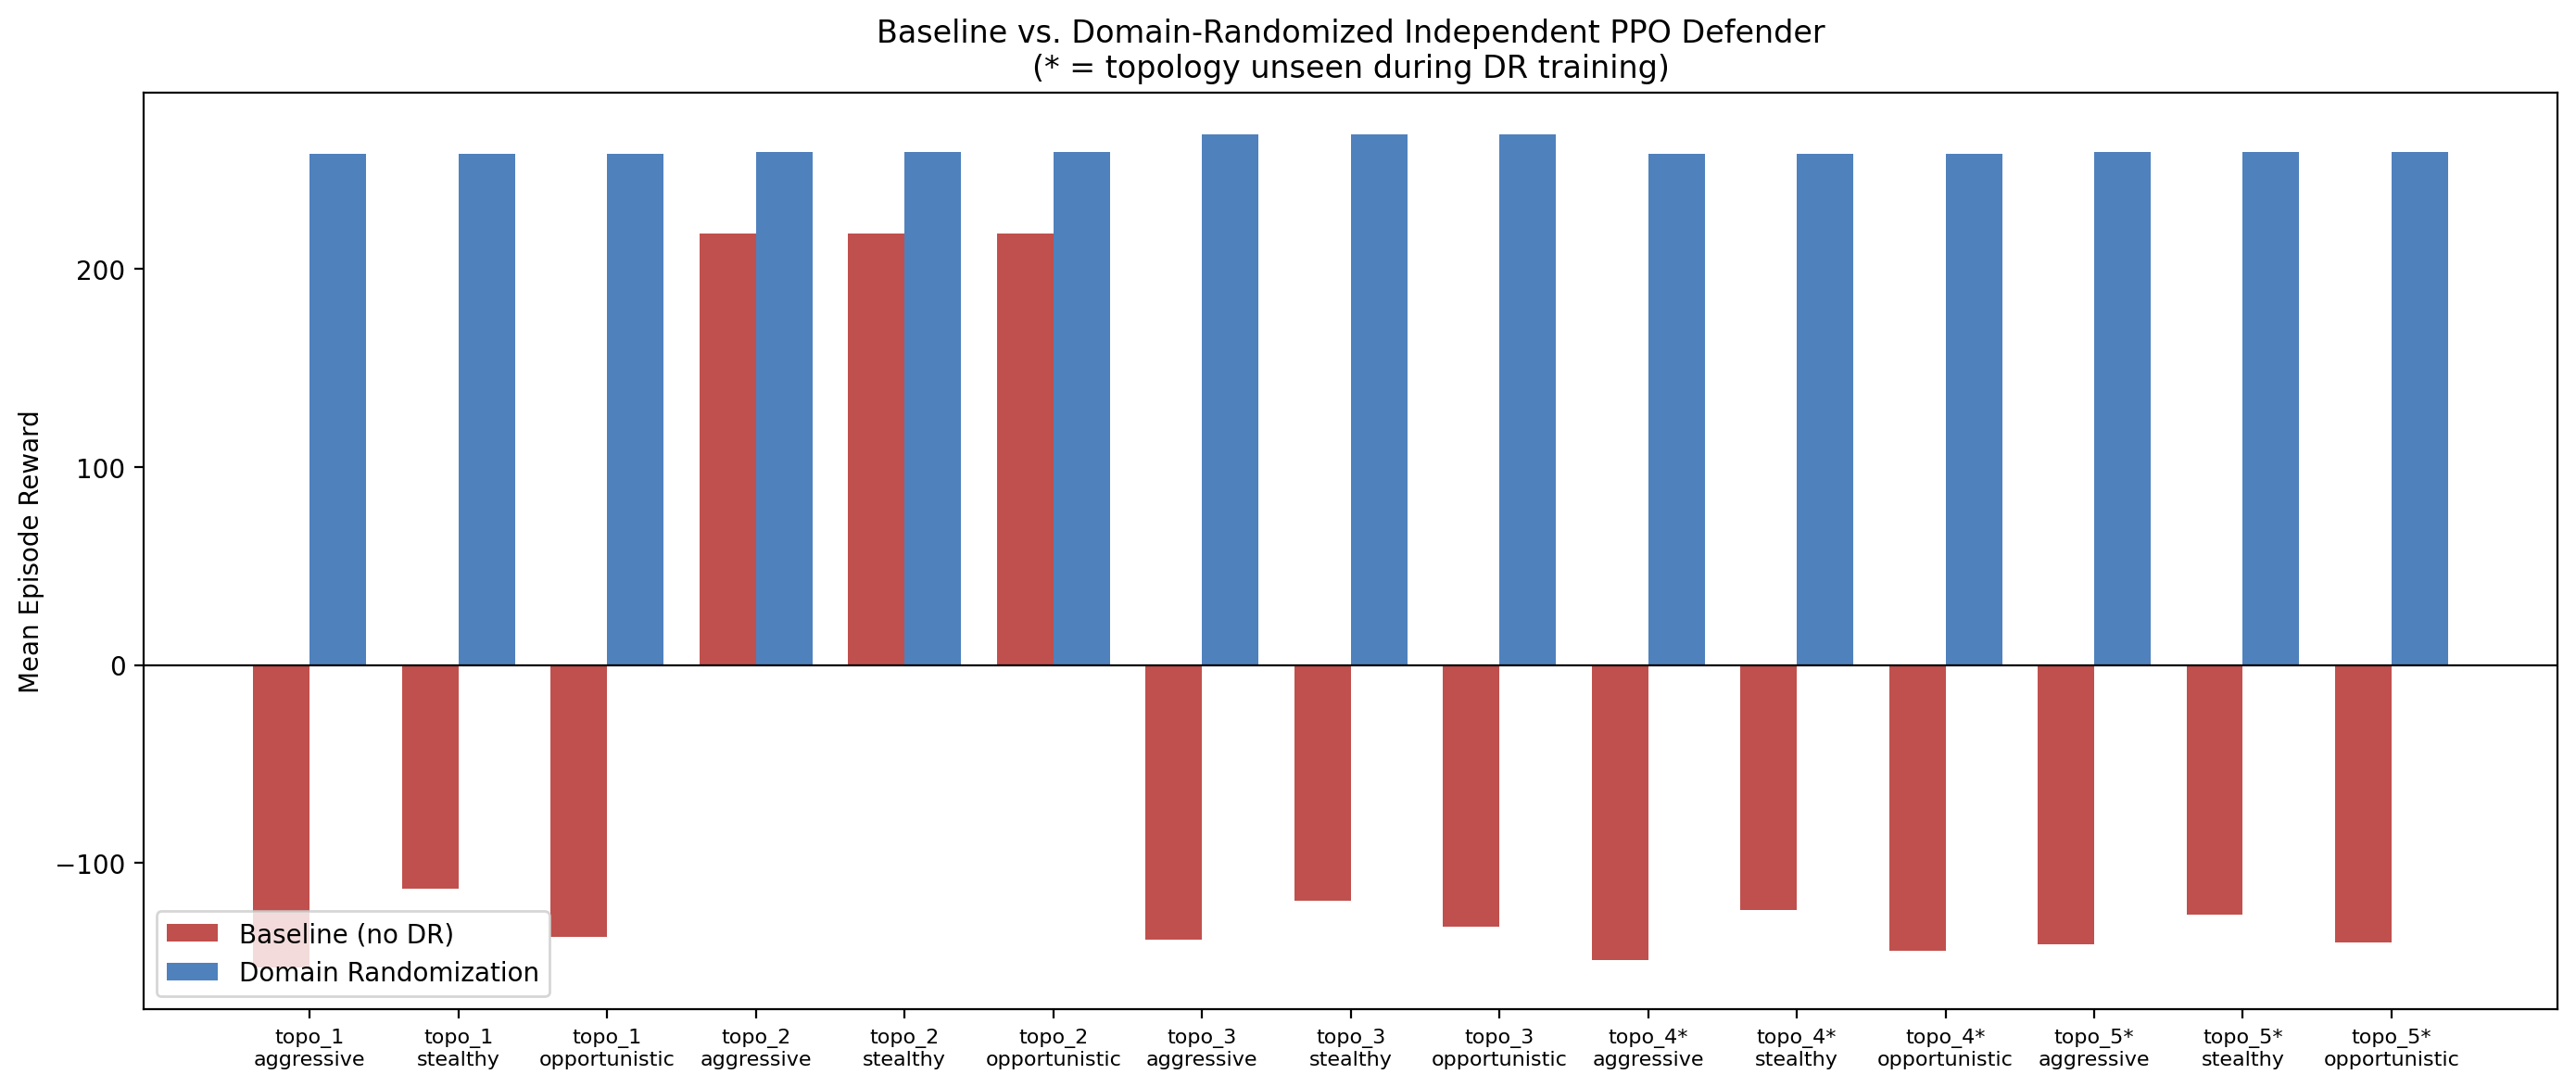

In [ ]:
from IPython.display import Image
Image("results_bar_chart.png")

In [ ]:
%%writefile collect_learning_curve_data.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "topology_generator", "profiles"]:
    if mod in sys.modules:
        del sys.modules[mod]

import json
import numpy as np
from stable_baselines3 import PPO

exec(open("topology_A.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv

def eval_pair(det_model, resp_model, n_episodes=10, max_steps=50):
    rewards = []
    for ep in range(n_episodes):
        e = FixedSizeDefenderEnv(env, PROFILES["aggressive"], max_steps=max_steps)
        obs, _ = e.reset(seed=ep)
        ep_r = 0.0
        done = False
        while not done:
            d, _ = det_model.predict(obs, deterministic=True)
            r, _ = resp_model.predict(obs, deterministic=True)
            obs, reward, term, trunc, info = e.step((int(d), int(r)))
            ep_r += reward
            done = term or trunc
        rewards.append(ep_r)
    return float(np.mean(rewards))

Writing collect_learning_curve_data.py


In [ ]:
print(repr(open("collect_learning_curve_data.py").read()[-100:]))

'rd\n            done = term or trunc\n        rewards.append(ep_r)\n    return float(np.mean(rewards))\n'


In [ ]:
%%writefile -a collect_learning_curve_data.py

baseline_curve = []
dr_curve = []

for round_idx in range(1, 11):
    det = PPO.load(f"checkpoints_ippo_baseline/ippo_baseline_detector_round{round_idx}")
    resp = PPO.load(f"checkpoints_ippo_baseline/ippo_baseline_responder_round{round_idx}")
    r = eval_pair(det, resp)
    baseline_curve.append(r)
    print(f"baseline round {round_idx}: {r:.1f}")

for round_idx in range(1, 11):
    det = PPO.load(f"checkpoints_ippo_dr/ippo_dr_detector_round{round_idx}")
    resp = PPO.load(f"checkpoints_ippo_dr/ippo_dr_responder_round{round_idx}")
    r = eval_pair(det, resp)
    dr_curve.append(r)
    print(f"dr round {round_idx}: {r:.1f}")

with open("learning_curve_data.json", "w") as f:
    json.dump({"baseline": baseline_curve, "dr": dr_curve}, f)
print("Saved learning_curve_data.json")

Appending to collect_learning_curve_data.py


In [ ]:
import ast
src = open("collect_learning_curve_data.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 1823


In [ ]:
%run collect_learning_curve_data.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


TypeError: Cannot interpret 'dtype('float32')' as a data type

AttributeError: 'function' object has no attribute 'called'

In [ ]:
import sys
for mod in ["multi_agent_env", "topology_generator", "profiles", "fixed_size_env"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

print("Reload complete.")

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Reload complete.


In [ ]:
import sys
for mod in ["multi_agent_env", "topology_generator", "profiles", "fixed_size_env"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from multi_agent_env import MultiAgentDefenderEnv

print("Reload complete.")

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Reload complete.


In [ ]:
%run collect_learning_curve_data.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


TypeError: Cannot interpret 'dtype('float32')' as a data type

AttributeError: 'function' object has no attribute 'called'

In [ ]:
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None

In [ ]:
exec(open("topology_A.py").read())
exec(open("profiles.py").read())
print("Setup complete.")

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Setup complete.


In [ ]:
%run collect_learning_curve_data.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


TypeError: Cannot interpret 'dtype('float32')' as a data type

AttributeError: 'function' object has no attribute 'called'

In [ ]:
import numpy as np
print("numpy version:", np.__version__)
print("numpy path:", np.__file__)

import stable_baselines3
print("SB3 path:", stable_baselines3.__file__)

numpy version: 1.26.4
numpy path: /usr/local/lib/python3.12/dist-packages/numpy/__init__.py
SB3 path: /content/myenv/stable_baselines3/__init__.py


In [ ]:
import subprocess
result = subprocess.run(
    ["find", "/content/myenv", "-iname", "numpy", "-maxdepth", "6"],
    capture_output=True, text=True
)
print(result.stdout)

# also check if there's a version marker
result2 = subprocess.run(
    ["bash", "-c", "cat /content/myenv/numpy*/METADATA 2>/dev/null | grep -i version | head -5"],
    capture_output=True, text=True
)
print(result2.stdout)

result3 = subprocess.run(
    ["bash", "-c", "find /content/myenv -iname '*.dist-info' | grep -i numpy"],
    capture_output=True, text=True
)
print(result3.stdout)

/content/myenv/pandas/compat/numpy
/content/myenv/numpy
/content/myenv/numpy/core/include/numpy
/content/myenv/scipy/_external/array_api_compat/numpy
/content/myenv/numpy-2.5.1.dist-info/licenses/numpy
/content/myenv/numpy-2.5.1.dist-info/licenses/numpy/_core/include/numpy

Metadata-Version: 2.1
Version: 1.26.4
          the Free Software Foundation; either version 3, or (at your option)
          any later version.
          Under Section 7 of GPL version 3, you are granted additional

/content/myenv/numpy-1.26.4.dist-info
/content/myenv/numpy-2.5.1.dist-info



In [ ]:
with open("/content/myenv/numpy/version.py") as f:
    print(f.read())


version = "1.26.4"
__version__ = version
full_version = version

git_revision = "9815c16f449e12915ef35a8255329ba26dacd5c0"
release = 'dev' not in version and '+' not in version
short_version = version.split("+")[0]



In [ ]:
import sys
sys.path.insert(0, "/content/myenv")

import numpy as np
print("numpy path:", np.__file__)   # must now show /content/myenv/numpy/__init__.py

import stable_baselines3
print("SB3 path:", stable_baselines3.__file__)

numpy path: /usr/local/lib/python3.12/dist-packages/numpy/__init__.py
SB3 path: /content/myenv/stable_baselines3/__init__.py


In [ ]:
exec(open("topology_A.py").read())
exec(open("profiles.py").read())
print("Setup complete.")

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Setup complete.


In [ ]:
%run collect_learning_curve_data.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']


TypeError: Cannot interpret 'dtype('float32')' as a data type

AttributeError: 'function' object has no attribute 'called'

In [ ]:
import sys

# Evict any numpy-family modules Colab preloaded
for mod in list(sys.modules):
    if mod == "numpy" or mod.startswith("numpy."):
        del sys.modules[mod]

sys.path.insert(0, "/content/myenv")

import numpy as np
print("numpy path:", np.__file__)

import stable_baselines3
print("SB3 path:", stable_baselines3.__file__)


numpy path: /content/myenv/numpy/__init__.py
SB3 path: /content/myenv/stable_baselines3/__init__.py


/tmp/ipykernel_519/1137984201.py:10: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy as np


In [ ]:
import os
print(os.getpid())

519


In [ ]:
import os
print(os.getpid())

519


In [ ]:
import sys
for mod in list(sys.modules):
    if mod == "numpy" or mod.startswith("numpy.") or mod.startswith("stable_baselines3"):
        del sys.modules[mod]

sys.path.insert(0, "/content/myenv")

import numpy as np
from stable_baselines3 import PPO

print(np.__file__)
print(PPO.load.__module__)

try:
    det = PPO.load("checkpoints_ippo_baseline/ippo_baseline_detector_round1")
    print("LOADED OK")
except Exception as e:
    print("STILL FAILS:", type(e).__name__, e)

/tmp/ipykernel_519/3525188292.py:8: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy as np


AttributeError: module 'numpy' has no attribute 'typing'

In [ ]:
import sys
for mod in list(sys.modules):
    if mod == "numpy" or mod.startswith("numpy.") or mod.startswith("stable_baselines3"):
        del sys.modules[mod]

sys.path.insert(0, "/content/myenv")

import numpy as np
import numpy.typing   # <-- explicitly bind this submodule before SB3 needs it

from stable_baselines3 import PPO

print(np.__file__)
print(PPO.load.__module__)

try:
    det = PPO.load("checkpoints_ippo_baseline/ippo_baseline_detector_round1")
    print("LOADED OK")
except Exception as e:
    print("STILL FAILS:", type(e).__name__, e)

/content/myenv/numpy/__init__.py
stable_baselines3.common.base_class
LOADED OK


/tmp/ipykernel_519/2701358291.py:8: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy as np


In [ ]:
%run collect_learning_curve_data.py

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
baseline round 1: 250.0
baseline round 2: 250.0
baseline round 3: 250.0
baseline round 4: 250.0
baseline round 5: 250.0
baseline round 6: 250.0
baseline round 7: 250.0
baseline round 8: 250.0
baseline round 9: 250.0
baseline round 10: 250.0
dr round 1: 250.0
dr round 2: 250.0
dr round 3: 250.0
dr round 4: 250.0
dr round 5: 250.0
dr round 6: 250.0
dr round 7: 250.0
dr round 8: 250.0
dr round 9: 250.0
dr round 10: 250.0
Saved learning_curve_data.json


AttributeError: 'function' object has no attribute 'called'

In [ ]:
import os
print(os.path.exists("learning_curve_data.json"), os.path.getsize("learning_curve_data.json"))

True 162


In [ ]:
with open("collect_learning_curve_data.py") as f:
    print(f.read())

import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "topology_generator", "profiles"]:
    if mod in sys.modules:
        del sys.modules[mod]

import json
import numpy as np
from stable_baselines3 import PPO

exec(open("topology_A.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv

def eval_pair(det_model, resp_model, n_episodes=10, max_steps=50):
    rewards = []
    for ep in range(n_episodes):
        e = FixedSizeDefenderEnv(env, PROFILES["aggressive"], max_steps=max_steps)
        obs, _ = e.reset(seed=ep)
        ep_r = 0.0
        done = False
        while not done:
            d, _ = det_model.predict(obs, deterministic=True)
            r, _ = resp_model.predict(obs, deterministic=True)
            obs, reward, term, trunc, info = e.step((int(d), int(r)))
            ep_r += reward
            done = term or trunc
        rewards.append(ep_r)
    

In [ ]:
with open("fixed_size_env.py") as f:
    print(f.read())

import sys
sys.modules['tensorflow'] = None

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from multi_agent_env import MultiAgentDefenderEnv

MAX_NODES = 10  # largest topology variant (topo_5) across topo_1..5

class FixedSizeDefenderEnv(gym.Env):
    def __init__(self, environment, attacker_profile, max_steps=50, max_nodes=MAX_NODES):
        super().__init__()
        self.inner = MultiAgentDefenderEnv(environment, attacker_profile, max_steps=max_steps)
        self.max_nodes = max_nodes
        self.real_n_nodes = self.inner.n_nodes

        self.action_space = spaces.MultiDiscrete([max_nodes + 1, max_nodes + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(max_nodes * 2,), dtype=np.float32)

    def _pad_obs(self, obs):
        padded = np.zeros(self.max_nodes * 2, dtype=np.float32)
        padded[:len(obs)] = obs
        return padded

    def reset(self, *, seed=None, options=None):
        obs, info = self.inner.reset(seed=seed, op

In [ ]:
import subprocess
print(subprocess.run(["find", "/content", "-iname", "fixed_size_env.py"], capture_output=True, text=True).stdout)

/content/fixed_size_env.py



In [ ]:
with open("/content/fixed_size_env.py") as f:
    print(f.read())

import sys
sys.modules['tensorflow'] = None

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from multi_agent_env import MultiAgentDefenderEnv

MAX_NODES = 10  # largest topology variant (topo_5) across topo_1..5

class FixedSizeDefenderEnv(gym.Env):
    def __init__(self, environment, attacker_profile, max_steps=50, max_nodes=MAX_NODES):
        super().__init__()
        self.inner = MultiAgentDefenderEnv(environment, attacker_profile, max_steps=max_steps)
        self.max_nodes = max_nodes
        self.real_n_nodes = self.inner.n_nodes

        self.action_space = spaces.MultiDiscrete([max_nodes + 1, max_nodes + 1])
        self.observation_space = spaces.Box(low=0, high=1, shape=(max_nodes * 2,), dtype=np.float32)

    def _pad_obs(self, obs):
        padded = np.zeros(self.max_nodes * 2, dtype=np.float32)
        padded[:len(obs)] = obs
        return padded

    def reset(self, *, seed=None, options=None):
        obs, info = self.inner.reset(seed=seed, op

In [ ]:
with open("/content/multi_agent_env.py") as f:
    print(f.read())

import random
import copy
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from cyberbattle.simulation import model as m
from cyberbattle.simulation import actions as bactions


class MultiAgentDefenderEnv(gym.Env):
    def __init__(self, environment: m.Environment, attacker_profile: dict, max_steps: int = 50):
        super().__init__()
        self.base_environment = environment
        self.attacker_profile_vulns = set(attacker_profile["vulns"])
        self.strategy = attacker_profile.get("strategy", "greedy_value")
        self.max_exploits_per_step = attacker_profile.get("max_exploits_per_step", None)
        self.max_steps = max_steps
        self.node_ids = list(environment.network.nodes)
        self.n_nodes = len(self.node_ids)

        self.detector_action_space = spaces.Discrete(self.n_nodes + 1)
        self.responder_action_space = spaces.Discrete(self.n_nodes + 1)
        self.observation_space = spaces.Box(low=0, high=1, shape=(self.n_nodes * 2,),

In [ ]:
if detector_action < self.n_nodes:
    node_id = self.node_ids[detector_action]
    ...
    if node_data.agent_installed:
        reward += 5.0

NameError: name 'detector_action' is not defined

In [ ]:
import multi_agent_env, importlib
importlib.reload(multi_agent_env)
from multi_agent_env import MultiAgentDefenderEnv

env_test = MultiAgentDefenderEnv(environment, PROFILES["aggressive"], max_steps=50)
obs, _ = env_test.reset(seed=0)

for i in range(10):
    obs, reward, term, trunc, info = env_test.step((0, 0))
    print(i, "reward:", reward, "owned nodes:", env_test._owned_nodes())

NameError: name 'environment' is not defined

In [ ]:
exec(open("topology_A.py").read())
exec(open("profiles.py").read())
print("environment" in dir(), "PROFILES" in dir())

Topology A loaded: 7 nodes
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
False True


In [ ]:

with open("topology_A.py") as f:
    print(f.read())

from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            DiscoverWorkstations=m.VulnerabilityInfo(
                description="Scan local network to discover workstations",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["Workstation_1", "Workstation_2"

In [ ]:
from cyberbattle.simulation import model as m

default_firewall = m.FirewallConfiguration(
    incoming=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ],
    outgoing=[
        m.FirewallRule("RDP", m.RulePermission.ALLOW),
        m.FirewallRule("SSH", m.RulePermission.ALLOW),
        m.FirewallRule("HTTPS", m.RulePermission.ALLOW),
    ]
)

nodes = {
    "EntryPoint": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=0,
        properties=["Windows", "ExposedToInternet"],
        agent_installed=True,
        reimagable=False,
        firewall=default_firewall,
        vulnerabilities=dict(
            DiscoverWorkstations=m.VulnerabilityInfo(
                description="Scan local network to discover workstations",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["Workstation_1", "Workstation_2"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_1": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=10,
        properties=["Windows"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceRDP=m.VulnerabilityInfo(
                description="Brute force RDP to gain access",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.8),
                cost=1.0
            ),
            DiscoverFileServer=m.VulnerabilityInfo(
                description="Discover file server from workstation",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["FileServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "Workstation_2": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=10,
        properties=["Linux"],
        firewall=default_firewall,
        vulnerabilities=dict(
            WeakSSH=m.VulnerabilityInfo(
                description="Weak SSH password",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.7),
                cost=1.0
            )
        )
    ),

    "FileServer": m.NodeInfo(
        services=[m.ListeningService("SSH")],
        value=50,
        properties=["Linux", "FileShare"],
        firewall=default_firewall,
        vulnerabilities=dict(
            ExploitSMB=m.VulnerabilityInfo(
                description="Exploit SMB vulnerability",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            DiscoverMore=m.VulnerabilityInfo(
                description="Discover admin workstation and database server",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedNodesId(["AdminWorkstation", "DatabaseServer"]),
                rates=m.Rates(successRate=1.0),
                cost=1.0
            )
        )
    ),

    "DatabaseServer": m.NodeInfo(
        services=[m.ListeningService("HTTPS")],
        value=100,
        properties=["Linux", "Database"],
        owned_string="FLAG: Database accessed",
        firewall=default_firewall,
        vulnerabilities=dict(
            SQLInjection=m.VulnerabilityInfo(
                description="SQL injection on exposed endpoint",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.4),
                cost=3.0
            )
        )
    ),

    "AdminWorkstation": m.NodeInfo(
        services=[m.ListeningService("RDP")],
        value=80,
        properties=["Windows", "AdminHost"],
        firewall=default_firewall,
        vulnerabilities=dict(
            BruteForceAdminRDP=m.VulnerabilityInfo(
                description="Brute force RDP into admin workstation",
                type=m.VulnerabilityType.REMOTE,
                outcome=m.LateralMove(),
                rates=m.Rates(successRate=0.5),
                cost=2.0
            ),
            StealAdminCreds=m.VulnerabilityInfo(
                description="Steal cached admin credentials, revealing Domain Controller",
                type=m.VulnerabilityType.LOCAL,
                outcome=m.LeakedCredentials(credentials=[
                    m.CachedCredential(node="DomainController", port="RDP", credential="admin_pass")
                ]),
                rates=m.Rates(successRate=0.7),
                cost=2.0
            )
        )
    ),

    "DomainController": m.NodeInfo(
        services=[m.ListeningService("RDP", allowedCredentials=["admin_pass"])],
        value=200,
        properties=["Windows", "DomainController"],
        owned_string="FLAG: Domain Controller compromised",
        firewall=default_firewall,
        vulnerabilities=dict()
    ),
}

network = m.create_network(nodes)

ENV_IDENTIFIERS = m.Identifiers(
    ports=["HTTPS", "RDP", "SSH"],
    properties=["Windows", "Linux", "ExposedToInternet", "FileShare", "Database", "AdminHost", "DomainController"],
    local_vulnerabilities=["DiscoverWorkstations", "DiscoverFileServer", "DiscoverMore", "StealAdminCreds"],
    remote_vulnerabilities=["BruteForceRDP", "WeakSSH", "ExploitSMB", "SQLInjection", "BruteForceAdminRDP"],
)

env = m.Environment(
    network=network,
    vulnerability_library=dict([]),
    identifiers=ENV_IDENTIFIERS
)

print("Topology A loaded:", len(nodes), "nodes")



Topology A loaded: 7 nodes


In [ ]:
%%writefile make_corrected_diagram.py
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6", fontsize=8):
    ax.add_patch(plt.Rectangle((x, y), w, h, edgecolor="black", facecolor=color, linewidth=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fontsize)

def group(x, y, w, h, title):
    ax.add_patch(plt.Rectangle((x, y), w, h, edgecolor="gray", facecolor="none",
                                linewidth=1.0, linestyle="--"))
    ax.text(x + 0.1, y + h - 0.15, title, fontsize=8, style="italic", color="dimgray")

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.1))

Writing make_corrected_diagram.py


In [ ]:
print(repr(open("make_corrected_diagram.py").read()[-100:]))

'x2, y2), xytext=(x1, y1),\n                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.1))\n'


In [ ]:
%%writefile -a make_corrected_diagram.py

# --- Left column: inputs ---
group(0.2, 6.8, 3.2, 2.0, "Attacker Profiles")
box(0.4, 7.8, 2.8, 0.7, "Aggressive / Stealthy / Opportunistic\n(seen, used in training)")
box(0.4, 6.9, 2.8, 0.7, "Cloud Pivot\n(held out - true zero-day)")

group(0.2, 4.3, 3.2, 2.2, "Topology Variants (procedural)")
box(0.4, 5.4, 2.8, 0.9, "topo_1, topo_2, topo_3\n(seen - DR training pool)")
box(0.4, 4.4, 2.8, 0.9, "topo_4, topo_5\n(unseen - held out)")

# --- Center: DR controller + training env ---
box(3.9, 5.2, 2.2, 1.2, "Domain Randomization\nController\n(samples topology + profile\n+ seed each episode)")
box(6.6, 5.2, 2.6, 1.2, "CyberBattleSim Env\n(FixedSizeDefenderEnv,\npadded to max_nodes=10)")
box(6.6, 3.4, 2.6, 1.0, "Scripted Attacker\n(profile-driven,\ndiscovery-chain based)")

Appending to make_corrected_diagram.py


In [ ]:
print(repr(open("make_corrected_diagram.py").read()[-150:]))

'ttleSim Env\\n(FixedSizeDefenderEnv,\\npadded to max_nodes=10)")\nbox(6.6, 3.4, 2.6, 1.0, "Scripted Attacker\\n(profile-driven,\\ndiscovery-chain based)")\n'


In [ ]:
%%writefile -a make_corrected_diagram.py

group(9.6, 4.9, 3.2, 1.9, "Defender: Independent PPO")
box(9.8, 5.7, 2.8, 0.9, "Detector Policy\n(own network, own reward)")
box(9.8, 5.0, 2.8, 0.6, "Responder Policy\n(own network, own reward)")

box(3.9, 1.2, 5.3, 1.4, "Alternating self-play training:\nfreeze one policy, train the other,\nswap, repeat (10 rounds x 5000 steps)")

box(9.6, 1.2, 3.2, 1.4, "Evaluation:\nseen vs. unseen topology x\nseen vs. unseen profile\n(mean reward, containment rate)")

# arrows
arrow(3.4, 7.9, 3.9, 6.0)
arrow(3.4, 5.2, 3.9, 5.8)
arrow(6.1, 5.8, 6.6, 5.8)
arrow(7.9, 5.2, 7.9, 4.4)
arrow(9.2, 5.8, 9.6, 5.8)
arrow(6.6, 1.9, 6.6, 2.6)
arrow(6.6, 2.6, 9.6, 2.6)
arrow(11.2, 4.9, 11.2, 2.6)

plt.title("Domain-Randomized Independent PPO Defender for Zero-Day Generalization", fontsize=11)
plt.tight_layout()
plt.savefig("corrected_architecture_diagram.png", dpi=200, bbox_inches="tight")
print("Saved corrected_architecture_diagram.png")

Appending to make_corrected_diagram.py


In [ ]:
import ast
src = open("make_corrected_diagram.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 2519


In [ ]:
import subprocess
result = subprocess.run(["python3", "make_corrected_diagram.py"], capture_output=True, text=True)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

STDOUT: Saved corrected_architecture_diagram.png

STDERR: 


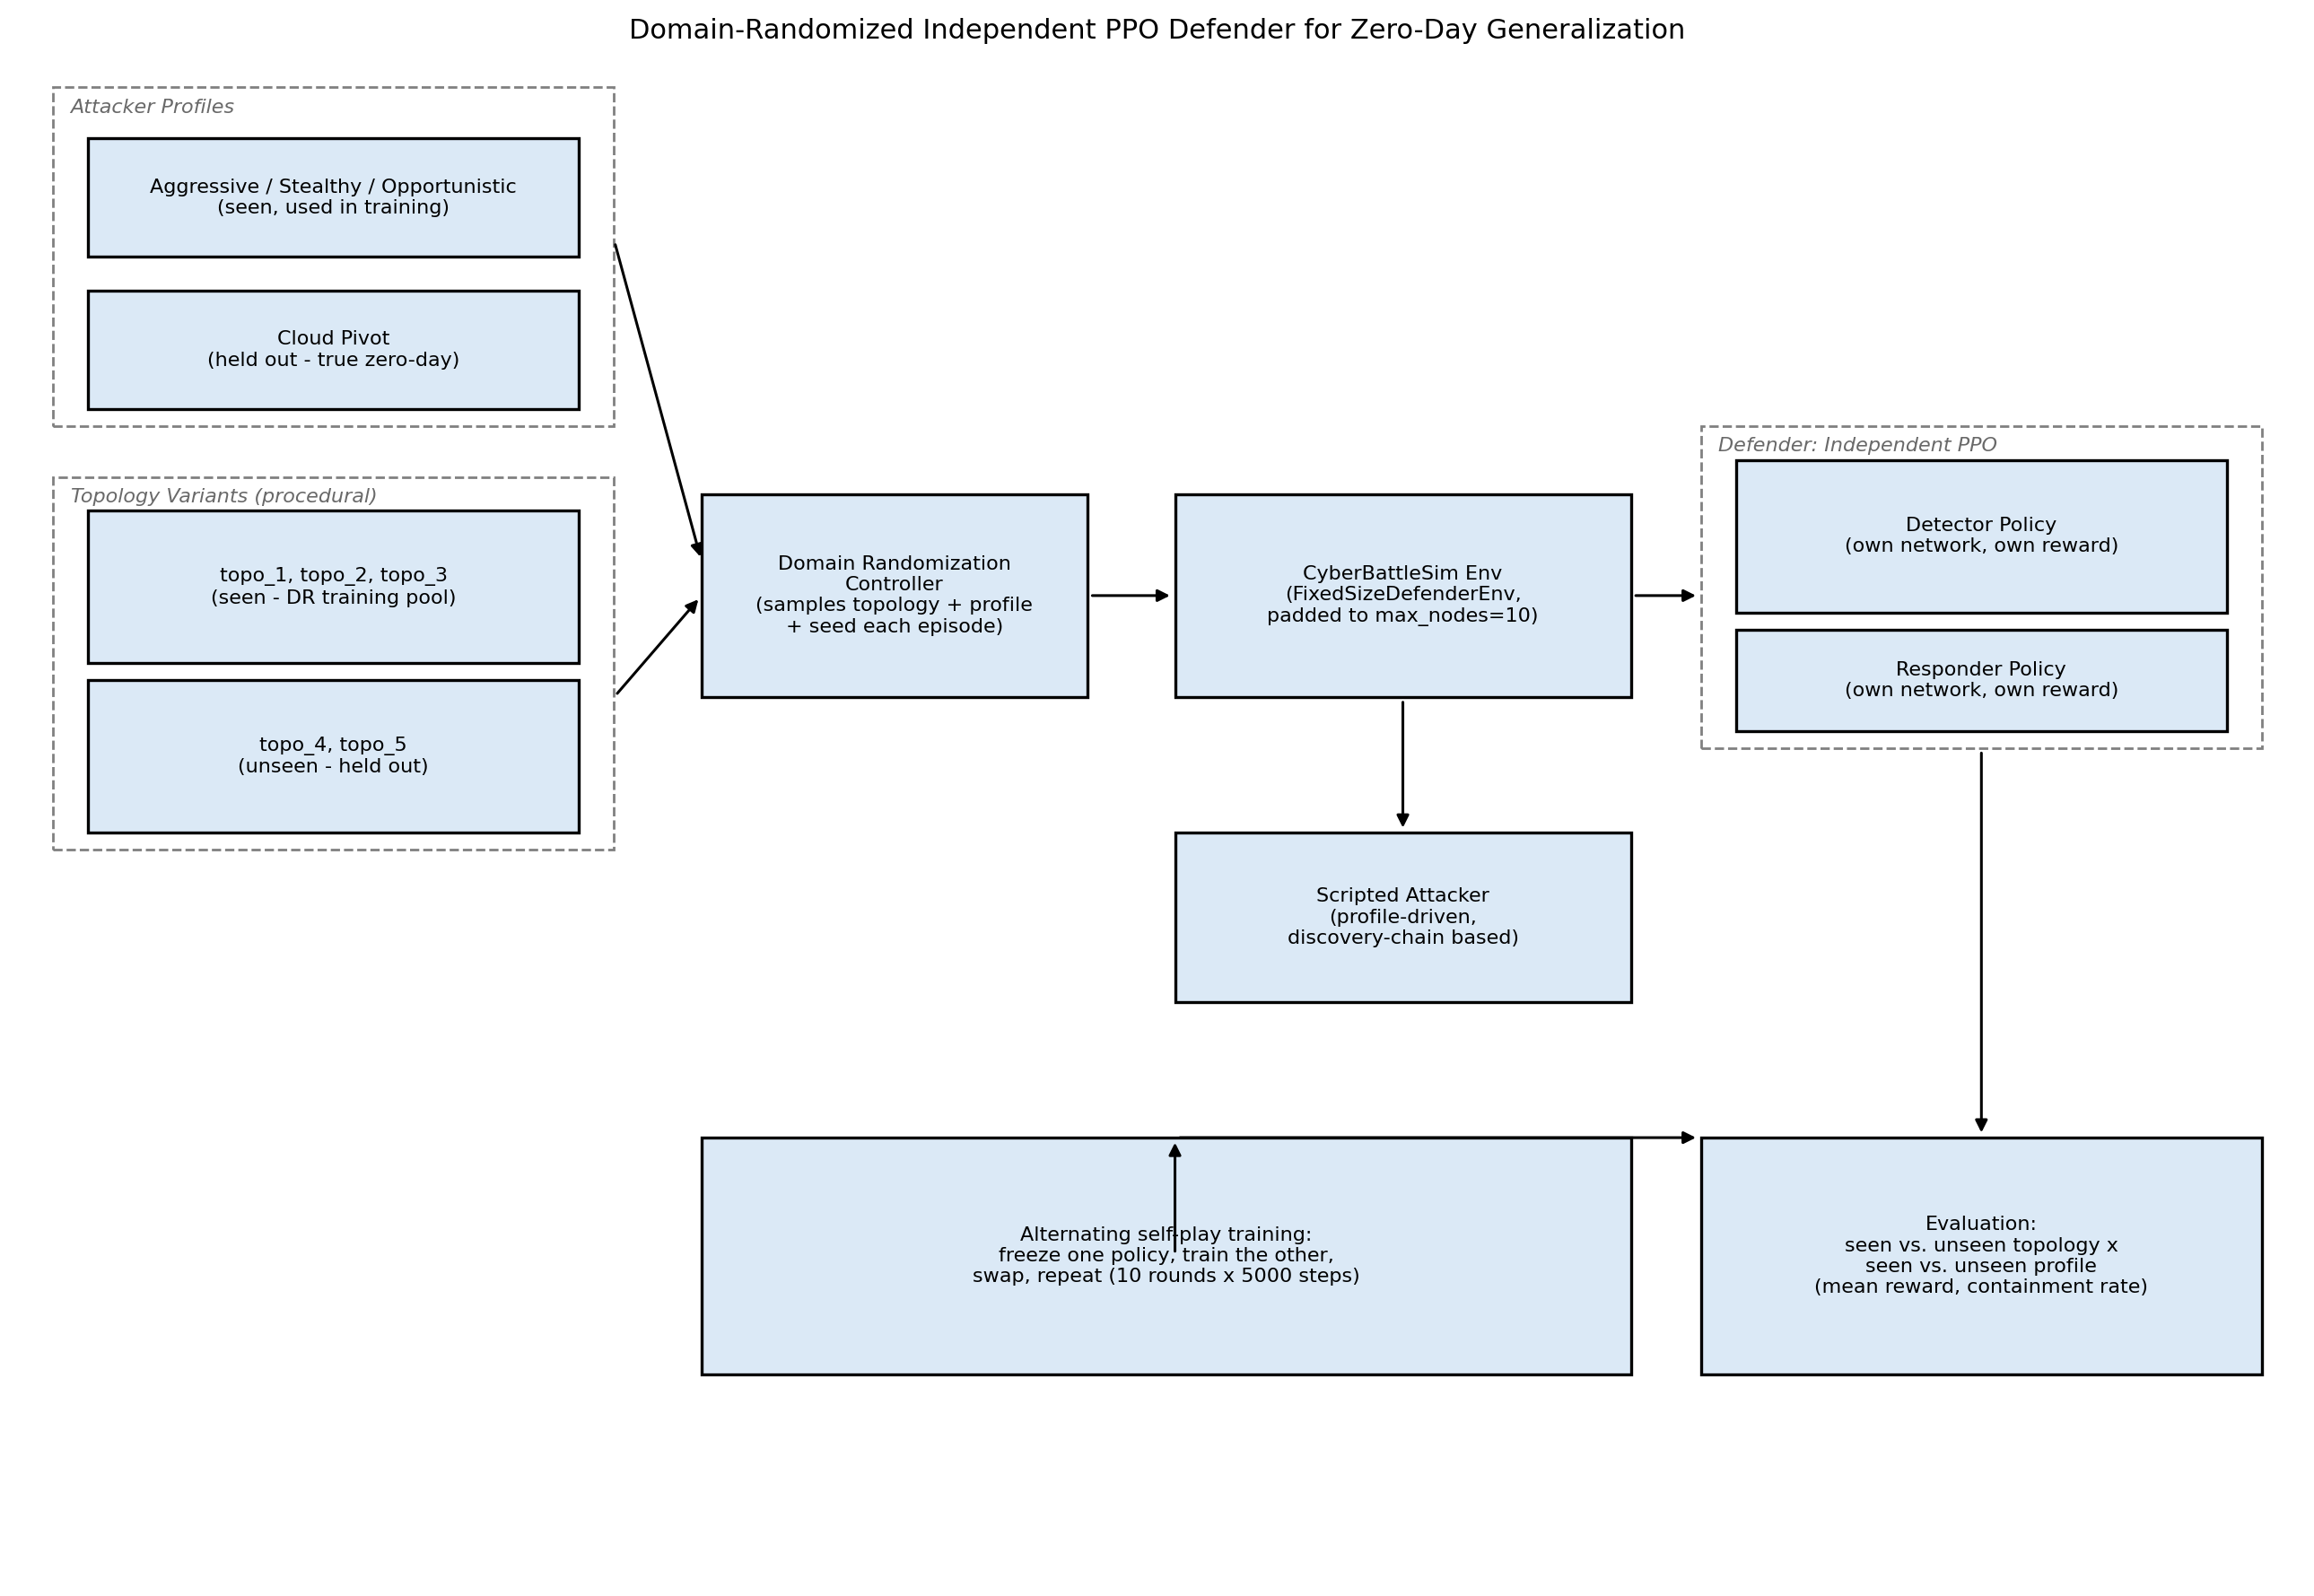

In [ ]:
from IPython.display import Image
Image("corrected_architecture_diagram.png")

In [ ]:
%%writefile patch_trainer_seed.py
with open("independent_ppo_trainer.py") as f:
    src = f.read()

old = '''def train_independent_ppo(inner_env_factory, checkpoint_dir, prefix,
                           n_rounds=10, timesteps_per_round=5000,
                           n_steps=256, batch_size=64, learning_rate=3e-4,
                           verbose=0):'''
new = '''def train_independent_ppo(inner_env_factory, checkpoint_dir, prefix,
                           n_rounds=10, timesteps_per_round=5000,
                           n_steps=256, batch_size=64, learning_rate=3e-4,
                           verbose=0, seed=None):'''
assert old in src
src = src.replace(old, new)

old2 = '''    detector_model = PPO("MlpPolicy", detector_env, verbose=verbose,
                          n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)
    responder_model = PPO("MlpPolicy", responder_env, verbose=verbose,
                           n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate)'''
new2 = '''    detector_model = PPO("MlpPolicy", detector_env, verbose=verbose,
                          n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate, seed=seed)
    responder_model = PPO("MlpPolicy", responder_env, verbose=verbose,
                           n_steps=n_steps, batch_size=batch_size, learning_rate=learning_rate,
                           seed=None if seed is None else seed + 1)'''
assert old2 in src
src = src.replace(old2, new2)

with open("independent_ppo_trainer.py", "w") as f:
    f.write(src)
print("Patched.")

Writing patch_trainer_seed.py


In [ ]:
import ast
ast.parse(open("independent_ppo_trainer.py").read())
print("Valid.")

Valid.


In [ ]:
exec(open("independent_ppo_trainer.py").read())

In [ ]:
%%writefile train_multiseed.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "dr_controller", "topology_generator", "profiles",
            "independent_ppo_env", "independent_ppo_trainer"]:
    if mod in sys.modules:
        del sys.modules[mod]

exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
exec(open("topology_A.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from dr_controller import DomainRandomizationController
from independent_ppo_trainer import train_independent_ppo

SEEN_TOPOLOGIES = ["topo_1", "topo_2", "topo_3"]
SEEDS = [0, 1, 2]

Writing train_multiseed.py


In [ ]:
print(repr(open("train_multiseed.py").read()[-100:]))

'er import train_independent_ppo\n\nSEEN_TOPOLOGIES = ["topo_1", "topo_2", "topo_3"]\nSEEDS = [0, 1, 2]\n'


In [ ]:
%%writefile -a train_multiseed.py

def baseline_env_factory():
    return FixedSizeDefenderEnv(env, PROFILES["aggressive"], max_steps=50)

print("=== Training baseline across 3 seeds ===")
for s in SEEDS:
    print(f"--- baseline seed {s} ---")
    train_independent_ppo(
        inner_env_factory=baseline_env_factory,
        checkpoint_dir=f"checkpoints_ippo_baseline_seed{s}",
        prefix="ippo_baseline",
        n_rounds=10,
        timesteps_per_round=5000,
        seed=s,
    )

Appending to train_multiseed.py


In [ ]:
print(repr(open("train_multiseed.py").read()[-150:]))

'ir=f"checkpoints_ippo_baseline_seed{s}",\n        prefix="ippo_baseline",\n        n_rounds=10,\n        timesteps_per_round=5000,\n        seed=s,\n    )\n'


In [ ]:
%%writefile -a train_multiseed.py

print("=== Training DR across 3 seeds ===")
for s in SEEDS:
    print(f"--- DR seed {s} ---")
    dr = DomainRandomizationController(
        topology_variants=TOPOLOGY_VARIANTS,
        profiles=PROFILES,
        training_profile_names=["aggressive", "stealthy", "opportunistic"],
        training_topology_names=SEEN_TOPOLOGIES,
        seed=7 + s,
    )

    def dr_env_factory(dr=dr):
        config = dr.sample_episode_config()
        return dr.make_env(config, generate_topology, FixedSizeDefenderEnv, max_steps=50)

    train_independent_ppo(
        inner_env_factory=dr_env_factory,
        checkpoint_dir=f"checkpoints_ippo_dr_seed{s}",
        prefix="ippo_dr",
        n_rounds=10,
        timesteps_per_round=5000,
        seed=s,
    )

print("All multi-seed training complete.")

Appending to train_multiseed.py


In [ ]:
import ast
src = open("train_multiseed.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 1903


In [ ]:
%run train_multiseed.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
Topology A loaded: 7 nodes
=== Training baseline across 3 seeds ===
--- baseline seed 0 ---
[ippo_baseline] Round 1/10 - training detector...
[ippo_baseline] Round 1/10 - training responder...
[ippo_baseline] Round 2/10 - training detector...
[ippo_baseline] Round 2/10 - training responder...
[ippo_baseline] Round 3/10 - training detector...
[ippo_baseline] Round 3/10 - training responder...
[ippo_baseline] Round 4/10 - training detector...
[ippo_baseline] Round 4/10 - training responder...
[ippo_baseline] Round 5/10 - training detector...
[ippo_baseline] Round 5/10 - training responder...
[ippo_baseline] Round 6/10 - training detector...
[ippo_baseline] Round 6/10 - training responder...
[ippo_baseline] Round 7/10 - training detector...
[ippo_baseline] Round 7/10 - training responder...

AttributeError: 'function' object has no attribute 'called'

In [ ]:
%%writefile evaluate_multiseed.py
import sys
sys.modules['tensorflow'] = None
sys.modules['torch.utils.tensorboard'] = None
for mod in ["multi_agent_env", "fixed_size_env", "topology_generator", "profiles", "evaluate_ippo"]:
    if mod in sys.modules:
        del sys.modules[mod]

import json
import numpy as np
exec(open("topology_generator.py").read())
exec(open("profiles.py").read())
from fixed_size_env import FixedSizeDefenderEnv
from evaluate_ippo import evaluate_pair, load_pair

SEEDS = [0, 1, 2]
CONDITIONS = [
    ("topo_1", "aggressive"), ("topo_2", "aggressive"), ("topo_3", "aggressive"),
    ("topo_4", "aggressive"), ("topo_5", "aggressive"),
]

Writing evaluate_multiseed.py


In [ ]:
print(repr(open("evaluate_multiseed.py").read()[-100:]))

' "aggressive"), ("topo_3", "aggressive"),\n    ("topo_4", "aggressive"), ("topo_5", "aggressive"),\n]\n'


In [ ]:
%%writefile -a evaluate_multiseed.py

results = {}

for topo_name, profile_name in CONDITIONS:
    key = f"{topo_name}_{profile_name}"
    results[key] = {"baseline": [], "dr": []}
    topo_params = TOPOLOGY_VARIANTS[topo_name]
    profile = PROFILES[profile_name]

    def env_builder(topo_params=topo_params, profile=profile):
        base_env = generate_topology(**topo_params)
        return FixedSizeDefenderEnv(base_env, profile, max_steps=50)

    for s in SEEDS:
        base_det, base_resp = load_pair(f"checkpoints_ippo_baseline_seed{s}", "ippo_baseline")
        res = evaluate_pair(base_det, base_resp, env_builder, n_episodes=20)
        results[key]["baseline"].append(res["mean_reward"])
        print(f"{key} baseline seed{s}: {res['mean_reward']:.1f}")

    for s in SEEDS:
        dr_det, dr_resp = load_pair(f"checkpoints_ippo_dr_seed{s}", "ippo_dr")
        res = evaluate_pair(dr_det, dr_resp, env_builder, n_episodes=20)
        results[key]["dr"].append(res["mean_reward"])
        print(f"{key} dr seed{s}: {res['mean_reward']:.1f}")

Appending to evaluate_multiseed.py


In [ ]:
print(repr(open("evaluate_multiseed.py").read()[-200:]))

' "ippo_dr")\n        res = evaluate_pair(dr_det, dr_resp, env_builder, n_episodes=20)\n        results[key]["dr"].append(res["mean_reward"])\n        print(f"{key} dr seed{s}: {res[\'mean_reward\']:.1f}")\n'


In [ ]:
%%writefile -a evaluate_multiseed.py

print()
print("=== MULTI-SEED SUMMARY (mean +/- std across 3 seeds) ===")
summary = {}
for key, vals in results.items():
    b_mean, b_std = np.mean(vals["baseline"]), np.std(vals["baseline"])
    d_mean, d_std = np.mean(vals["dr"]), np.std(vals["dr"])
    summary[key] = {
        "baseline_mean": float(b_mean), "baseline_std": float(b_std),
        "dr_mean": float(d_mean), "dr_std": float(d_std),
    }
    print(f"{key:25s} Baseline: {b_mean:7.1f} +/- {b_std:5.1f}   DR: {d_mean:7.1f} +/- {d_std:5.1f}")

with open("multiseed_results.json", "w") as f:
    json.dump({"raw": results, "summary": summary}, f, indent=2)
print("\nSaved multiseed_results.json")

Appending to evaluate_multiseed.py


In [ ]:
import ast
src = open("evaluate_multiseed.py").read()
try:
    ast.parse(src)
    print("VALID syntax. Total bytes:", len(src))
except SyntaxError as e:
    print("SYNTAX ERROR:", e)

VALID syntax. Total bytes: 2313


In [ ]:
%run evaluate_multiseed.py

topo_1: 7 nodes, 0 edges
topo_2: 7 nodes, 0 edges
topo_3: 8 nodes, 0 edges
topo_4: 9 nodes, 0 edges
topo_5: 10 nodes, 0 edges
Profiles loaded: ['aggressive', 'stealthy', 'opportunistic', 'cloud_pivot']
topo_1_aggressive baseline seed0: -153.0
topo_1_aggressive baseline seed1: -122.0
topo_1_aggressive baseline seed2: -153.0
topo_1_aggressive dr seed0: 258.0
topo_1_aggressive dr seed1: 278.0
topo_1_aggressive dr seed2: 258.0
topo_2_aggressive baseline seed0: -128.0
topo_2_aggressive baseline seed1: -128.0
topo_2_aggressive baseline seed2: -148.0
topo_2_aggressive dr seed0: 259.0
topo_2_aggressive dr seed1: 259.0
topo_2_aggressive dr seed2: 259.0
topo_3_aggressive baseline seed0: -139.0
topo_3_aggressive baseline seed1: 217.0
topo_3_aggressive baseline seed2: -159.0
topo_3_aggressive dr seed0: 248.0
topo_3_aggressive dr seed1: 268.0
topo_3_aggressive dr seed2: 268.0
topo_4_aggressive baseline seed0: -149.0
topo_4_aggressive baseline seed1: -138.0
topo_4_aggressive baseline seed2: -169.0
t

AttributeError: 'function' object has no attribute 'called'

In [ ]:
%%writefile make_multiseed_chart.py
import json
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

with open("multiseed_results.json") as f:
    data = json.load(f)["summary"]

labels = list(data.keys())
b_means = [data[k]["baseline_mean"] for k in labels]
b_stds = [data[k]["baseline_std"] for k in labels]
d_means = [data[k]["dr_mean"] for k in labels]
d_stds = [data[k]["dr_std"] for k in labels]

x = list(range(len(labels)))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar([i - width/2 for i in x], b_means, width, yerr=b_stds, capsize=5,
       label="Baseline (no DR)", color="#c0504d")
ax.bar([i + width/2 for i in x], d_means, width, yerr=d_stds, capsize=5,
       label="Domain Randomization", color="#4f81bd")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([l.replace("_aggressive", "") for l in labels])
ax.set_ylabel("Mean Episode Reward (+/- std across 3 seeds)")
ax.set_xlabel("Topology (topo_4, topo_5 unseen during DR training)")
ax.set_title("Baseline vs. DR: Robustness Across Independent Training Seeds")
ax.legend()
plt.tight_layout()
plt.savefig("multiseed_chart.png", dpi=200, bbox_inches="tight")
print("Saved

Writing make_multiseed_chart.py


In [ ]:
import subprocess
result = subprocess.run(["python3", "make_multiseed_chart.py"], capture_output=True, text=True)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

STDOUT: 
STDERR:   File "/content/make_multiseed_chart.py", line 32
    print("Saved
          ^
SyntaxError: unterminated string literal (detected at line 32)



In [ ]:
from IPython.display import Image
Image("multiseed_chart.png")

FileNotFoundError: No such file or directory: 'multiseed_chart.png'

FileNotFoundError: No such file or directory: 'multiseed_chart.png'

<IPython.core.display.Image object>

In [ ]:
import subprocess
result = subprocess.run(["python3", "make_multiseed_chart.py"], capture_output=True, text=True)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)
print("Return code:", result.returncode)

STDOUT: 
STDERR:   File "/content/make_multiseed_chart.py", line 32
    print("Saved
          ^
SyntaxError: unterminated string literal (detected at line 32)

Return code: 1


In [ ]:
print(repr(open("make_multiseed_chart.py").read()[-60:]))

'seed_chart.png", dpi=200, bbox_inches="tight")\nprint("Saved\n'


In [ ]:
with open("make_multiseed_chart.py") as f:
    lines = f.readlines()

# Drop the last (broken) line and replace with the correct ending
lines = lines[:-1] if lines and "print(" in lines[-1] and not lines[-1].rstrip().endswith(")") else lines
lines.append('print("Saved multiseed_chart.png")\n')

with open("make_multiseed_chart.py", "w") as f:
    f.writelines(lines)

print(repr(open("make_multiseed_chart.py").read()[-100:]))

'plt.savefig("multiseed_chart.png", dpi=200, bbox_inches="tight")\nprint("Saved multiseed_chart.png")\n'


In [ ]:
import ast
try:
    ast.parse(open("make_multiseed_chart.py").read())
    print("VALID")
except SyntaxError as e:
    print("STILL BROKEN:", e)

VALID


In [ ]:
import subprocess
result = subprocess.run(["python3", "make_multiseed_chart.py"], capture_output=True, text=True)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

STDOUT: Saved multiseed_chart.png

STDERR: 


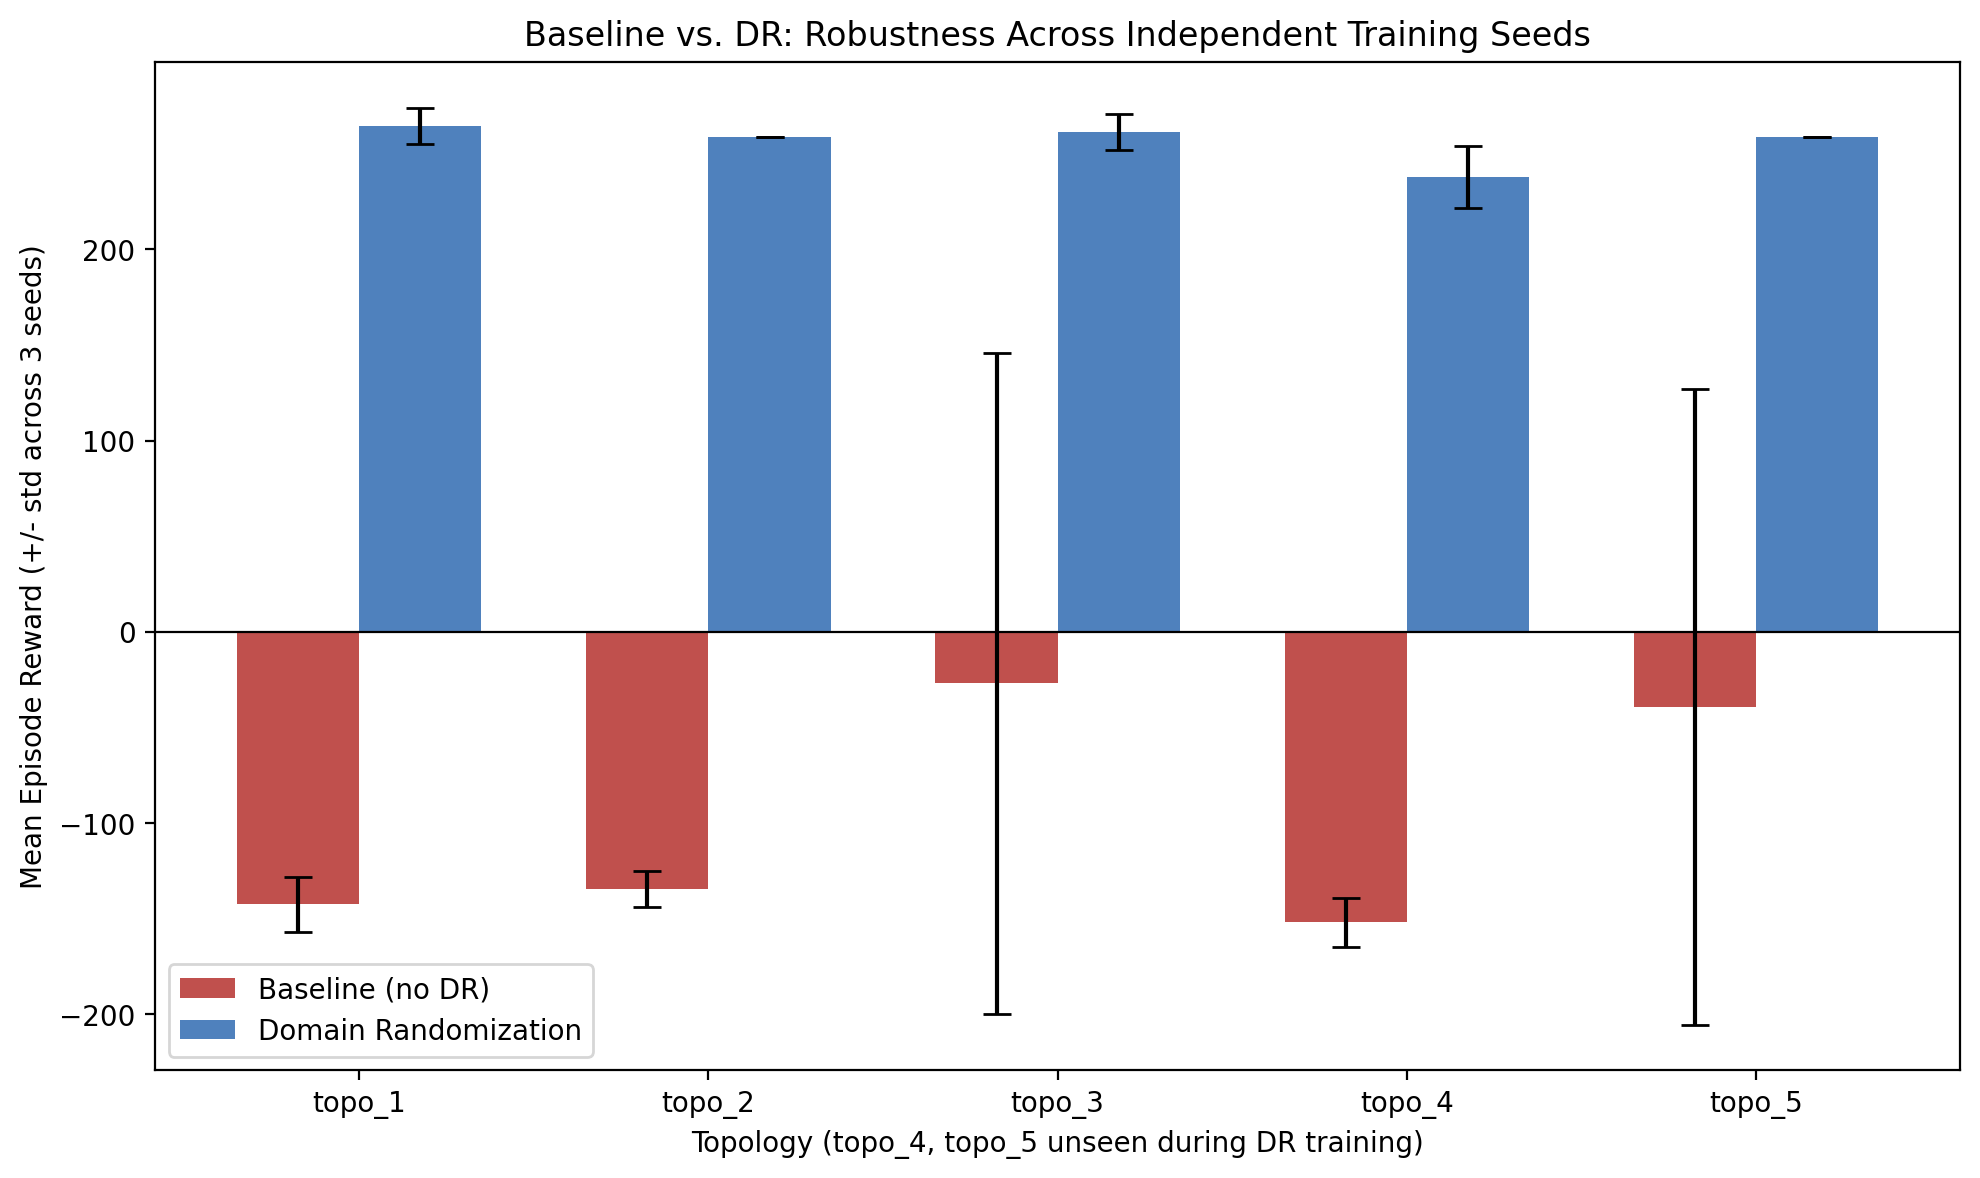

In [ ]:
from IPython.display import Image
Image("multiseed_chart.png")